# Segmentation clients Karafun : ACM + CAH

**Problématique** : identifier des groupes de clients homogènes pour **adapter la communication** (onboarding, fidélisation, réactivation, reconquête…) selon le profil de chacun.

**Méthode** : classification en deux temps, classique pour des données qualitatives.

1. **ACM (Analyse des Correspondances Multiples)** : elle résume 7 variables qualitatives en quelques axes factoriels numériques. Elle sert de « prétraitement » : la CAH ne sait pas travailler directement sur des modalités.
2. **CAH (Classification Ascendante Hiérarchique, critère de Ward)** sur les coordonnées des individus : elle regroupe les clients proches sur ces axes et fournit la typologie finale.

## Plan du notebook

| # | Étape | Objectif |
|---|---|---|
| 1 | Préparation | Packages, paramètres et fonctions utiles |
| 2 | Chargement | Lecture des données Karafun (341 092 clients) |
| 3 | Audit des données | Qualité, types, modalités |
| 4 | Liaisons entre variables | V de Cramér : repérer les variables redondantes |
| 5 | Regroupement des modalités | Supprimer les modalités rares, fusionner les variables redondantes, créer des variables « métier » |
| 6 | Jeux de données | `df_base` (brut) vs `df_regrouped` (regroupé) |
| 7 | ACM | 4 ACM comparées, choix de l'ACM 3, analyse des axes, variables supplémentaires |
| 8 | CAH | K-Means + CAH de Ward sur les coordonnées de l'ACM, lecture du dendrogramme |
| 9 | Synthèse | Bilan, points de vigilance, suite du projet |

**Convention de lecture** : `prince` numérote les axes à partir de **0** (« Axe 0 » = 1er axe). Cette numérotation est conservée dans tout le notebook.

# 1. Préparation de l'environnement
Montage de Google Drive (données), installation de `prince` (librairie ACM) et imports.
Deux paramètres globaux sont fixés dans la cellule d'imports : `SEUIL_RARE = 5` (une modalité représentant moins de 5 % de la population est jugée « rare ») et `SEED = 42` (reproductibilité).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install prince

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.0/208.0 kB 3.9 MB/s eta 0:00:00


In [3]:
!pip install fastcluster

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.9/193.9 kB 3.4 MB/s eta 0:00:00


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import prince
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from matplotlib.colors import ListedColormap, BoundaryNorm
import fastcluster
from scipy.cluster.hierarchy import dendrogram, fcluster
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
SEUIL_RARE = 5.0     # % : seuil de modalité rare
SEED = 42

## Fonctions utiles
Ces fonctions servent à **sécuriser les regroupements** et à **mesurer les liaisons** :
- `map_strict` : comme `.map()` mais stoppe si une modalité n'est pas dans le dictionnaire. Avec `.replace()`, une clé oubliée ou mal orthographiée est ignorée sans alerte, et la variable reste silencieusement non regroupée.
- `controle_modalites` : affiche la répartition de chaque variable et signale les modalités sous le seuil de 5 %.
- `cramers_v` / `matrice_cramer` : V de Cramér entre deux variables qualitatives (0 = aucun lien, 1 = lien parfait).

In [5]:
def map_strict(serie, mapping, nom=None):
    """Comme .map(), mais lève une erreur si une modalité n'est pas dans le dictionnaire
    (c'est exactement le bug qui a laissé 'avg_songs_sessions_tr' non regroupée)."""
    out = serie.map(mapping)
    manquantes = sorted(serie[out.isna()].unique())
    assert not manquantes, f"[{nom or serie.name}] modalités non mappées : {manquantes}"
    return out


def controle_modalites(d, seuil=SEUIL_RARE):
    """Affiche, pour chaque variable, la répartition (%) et alerte si une modalité est rare."""
    ok = True
    for c in d.columns:
        if c == 'id_anonyme':
            continue
        p = d[c].value_counts(normalize=True).mul(100).round(1)
        flag = '  ⚠️ MODALITÉ RARE' if (p < seuil).any() else ''
        ok &= not (p < seuil).any()
        print(f"{c:<28} {dict(p)}{flag}")
    print('\n✅ Toutes les modalités ≥ %.0f %%' % seuil if ok else '\n❌ Il reste des modalités rares')


def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2 = chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    return np.sqrt(chi2 / n / (min(t.shape) - 1))


def matrice_cramer(d, annot=True, titre="V de Cramér"):
    cols = [c for c in d.columns if c != 'id_anonyme']
    M = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            M.loc[a, b] = M.loc[b, a] = cramers_v(d[a], d[b])
    plt.figure(figsize=(1 + .8 * len(cols), .8 * len(cols)))
    sns.heatmap(M, annot=annot, fmt='.2f', cmap='viridis', vmin=0, vmax=1)
    plt.title(titre); plt.tight_layout(); plt.show()
    return M

# 2. Chargement des données
Lecture du fichier depuis Google Drive, puis sauvegarde d'une copie locale `df_karafun.csv` pour pouvoir relancer le notebook sans Drive. La cellule suivante recharge cette copie.

In [6]:
file_path = '/content/drive/MyDrive/All - SIAD/SIAD - Projets/M2/Clustering/td_clustering_karafun'

try:
    df = pd.read_csv(file_path)
    print(f"Successfully loaded the file: {file_path}")
    display(df.head())
except Exception as e:
    print(f"Error loading file as CSV: {e}")
    print("Trying to load it without headers and with a different separator, or please specify the file type if it's not a CSV.")
    # Attempt to read without header and different separator, as a common fallback
    try:
        df = pd.read_csv(file_path, header=None, sep='\t') # Common for some raw data files
        print("Successfully loaded the file with no header and tab separator.")
        display(df.head())
    except Exception as e_fallback:
        print(f"Fallback attempt also failed: {e_fallback}")
        print("Please check the file format and provide the correct parameters (e.g., delimiter, header=None).")

Successfully loaded the file: /content/drive/MyDrive/All - SIAD/SIAD - Projets/M2/Clustering/td_clustering_karafun


,id_anonyme,anciennete_client_tr,anciennete_abonnement_tr,statut_abonnement,type_client,type_very_first_abo,type_first_abo_last_streak,ratio_fidelite_tr,methode_paiement,nb_abo_periode,valeur_12M_tr,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,zone_geo,contactable
0,fbb58c58395ab62899c58d6a52f8159ca12ddd7f46bfe2...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Apple,1,00_moins_10,02_1a2,01_1a2,non,US,oui
1,8c981dbb88db4abcfd1c07b30ec42c370195fabaf74b8a...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Android,1,00_moins_10,03_2a3,02_2a3,non,Europe,oui
2,a4b6c3d31fb413aa830dbb423bd3d8446438dae71d9973...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,03_2a3,09_15a20,non,Europe,non
3,ef9a45455295911d59cd8a9c76d32d582709e40a5a238f...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,02_1a2,09_15a20,non,CA,oui
4,91d37bd372c738eddb00a6b2878877161fb26a2a519bf8...,00_moins_1_mois,00_moins_1_mois,actif,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,00_pas_de_session,00_pas_de_session,non,FR,oui


In [7]:
df.to_csv('df_karafun.csv', index=False)

In [8]:
# Pour importer le csv directement si le premier chemin ne marche pas (remplacer par ton chemin -> tu peux faire un glisser deposer du csv dans la partie fichier à gauche )
df = pd.read_csv("/content/df_karafun.csv")

# 3. Audit et description des données
Une ligne = un client. Les variables décrivent son **parcours d'abonnement** (ancienneté, type de client, fidélité, valeur), son **canal de paiement**, son **usage** du service (sessions, chansons, télécommande) et sa **zone géographique**.

Valeur : CA sur la période en €

### Valeurs manquantes

In [9]:
# Nombre total de valeurs manquantes dans le DataFrame
total_missing_values = df.isnull().sum().sum()

# Nombre total de lignes dans le DataFrame
total_rows = df.shape[0]

# Nombre total de colonnes dans le DataFrame
total_columns = df.shape[1]

print(f"Nombre total de valeurs manquantes : {total_missing_values}")
print(f"Nombre total de lignes : {total_rows}")
print(f"Nombre total de colonnes : {total_columns}")

Nombre total de valeurs manquantes : 0
Nombre total de lignes : 341092
Nombre total de colonnes : 16


✅ Aucune valeur manquante

**Lecture** : 341 092 clients × 16 variables, aucune valeur manquante : pas d'imputation à prévoir.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 341092 entries, 0 to 341091
Data columns (total 16 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   id_anonyme                  341092 non-null  object
 1   anciennete_client_tr        341092 non-null  object
 2   anciennete_abonnement_tr    341092 non-null  object
 3   statut_abonnement           341092 non-null  object
 4   type_client                 341092 non-null  object
 5   type_very_first_abo         341092 non-null  object
 6   type_first_abo_last_streak  341092 non-null  object
 7   ratio_fidelite_tr           341092 non-null  object
 8   methode_paiement            341092 non-null  object
 9   nb_abo_periode              341092 non-null  int64 
 10  valeur_12M_tr               341092 non-null  object
 11  avg_sessions_actifs_tr      341092 non-null  object
 12  avg_songs_sessions_tr       341092 non-null  object
 13  utilise_remote              3

**Lecture** : 15 variables qualitatives (`object`) et une seule numérique (`nb_abo_periode`, entier). `id_anonyme` est un identifiant unique, jamais utilisé comme variable.

On doit convertir nb_abo_periode en variable quali car on fait une ACM donc tout doit être quali

In [11]:
# Convertir nb_abo_periode en type 'object' pour le traiter comme une variable qualitative
df['nb_abo_periode'] = df['nb_abo_periode'].astype(str)

print("Le type de la colonne 'nb_abo_periode' a été converti en:")
print(df['nb_abo_periode'].dtype)

Le type de la colonne 'nb_abo_periode' a été converti en:
object


### Modalités de chaque variable

In [12]:
print("Modalités uniques pour TOUTES les colonnes :\n")

for col in df.columns:
    if col in df.columns:
        unique_values = df[col].unique()
        print(f"Colonne '{col}' (Nombre de modalités uniques: {len(unique_values)}):")
        # Display unique values, but truncate if there are too many for readability
        if len(unique_values) > 50:
            print(f"{unique_values[:10]} ... (premières 5 valeurs)")
        else:
            print(unique_values)
        print("----------------------------------------")
    else:
        print(f"La colonne '{col}' n'existe pas dans le DataFrame.\n")

Modalités uniques pour TOUTES les colonnes :

Colonne 'id_anonyme' (Nombre de modalités uniques: 341092):
['fbb58c58395ab62899c58d6a52f8159ca12ddd7f46bfe2b7ee22a8af810c0cde'
 '8c981dbb88db4abcfd1c07b30ec42c370195fabaf74b8a5876a863e464494159'
 'a4b6c3d31fb413aa830dbb423bd3d8446438dae71d9973f9c163900bf21beb86'
 'ef9a45455295911d59cd8a9c76d32d582709e40a5a238fe31f63f9915dc8c3df'
 '91d37bd372c738eddb00a6b2878877161fb26a2a519bf8d2932f8427775749a6'
 'ab7675775e8da713802fd7a408396997e347e42216bf618e98638cfdd285474b'
 'd7c30410b31df6c8a380f4857ee2e70991e1f0b37e0c7b454e6a68b039510c30'
 '9a3a77d0b996b940fd18d7e68aa98d5d9d3edc2408e4625ed64fbc9b56d1f30f'
 '89a4e69aa93e7a45ac20f1eba7b0c1432b169e7c3d044b2a4aeca8fee5f45262'
 '2ab17b42e9ab501b659448864cf0db56902ff792def1ddf73731cf2db9b472fa'] ... (premières 5 valeurs)
----------------------------------------
Colonne 'anciennete_client_tr' (Nombre de modalités uniques: 20):
['00_moins_1_mois' '01_1_mois' '02_2_mois' '03_3_mois' '04_4_mois'
 '05_5_mois' 

**Lecture** : plusieurs variables ont beaucoup de modalités (ancienneté : 20, sessions : 14, chansons : 13, valeur : 12, nb d'abonnements : 12). Or l'ACM donne un poids d'autant plus grand à une modalité qu'elle est **rare**, et une variable à nombreuses modalités pèse davantage dans l'inertie totale. Il faudra donc regrouper (étape 5).

# 4. Analyse des liaisons entre variables (V de Cramér)

**Pourquoi** : dans une ACM, toutes les variables actives ont le même poids. Si 5 variables disent la même chose (par exemple « le client est parti »), cette information domine le 1er axe et écrase le reste (usage, canal…). Il faut donc repérer les variables redondantes **avant** l'ACM.

**Lecture du V de Cramér** : < 0,2 liaison faible · 0,2-0,5 modérée · **> 0,5 forte, à surveiller** (redondance probable).

Decisions de regrouper ou non les modalités d'une variables se base sur 2 critères :
- modalités rare <5%
- la force de l'association V de cramer

In [13]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    phi2 = chi2 / n
    v = np.sqrt(phi2 / min(k - 1, r - 1))
    return v

In [14]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
if 'id_anonyme' in categorical_cols:
    categorical_cols.remove('id_anonyme')

cramers_v_matrix = pd.DataFrame(index=categorical_cols, columns=categorical_cols)

for col1 in categorical_cols:
    for col2 in categorical_cols:
        if col1 == col2:
            cramers_v_matrix.loc[col1, col2] = 1.0
        else:
            v_val = cramers_v(df[col1], df[col2])
            cramers_v_matrix.loc[col1, col2] = v_val

display(cramers_v_matrix)

,anciennete_client_tr,anciennete_abonnement_tr,statut_abonnement,type_client,type_very_first_abo,type_first_abo_last_streak,ratio_fidelite_tr,methode_paiement,nb_abo_periode,valeur_12M_tr,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,zone_geo,contactable
anciennete_client_tr,1.0,0.554697,0.319753,0.441446,0.131526,0.045589,0.49678,0.057387,0.264201,0.218532,0.070838,0.050385,0.074498,0.04213,0.353275
anciennete_abonnement_tr,0.554697,1.0,0.477993,0.536737,0.074232,0.082335,0.397741,0.084643,0.288554,0.245678,0.099525,0.071913,0.13548,0.047659,0.175127
statut_abonnement,0.319753,0.477993,1.0,1.0,0.06971,0.014519,0.693099,0.07894,0.635498,0.621169,0.269207,0.169576,0.042694,0.120881,0.025887
type_client,0.441446,0.536737,1.0,1.0,0.159843,0.022956,0.513902,0.077642,0.592044,0.531722,0.177497,0.119477,0.094586,0.080262,0.165877
type_very_first_abo,0.131526,0.074232,0.06971,0.159843,1.0,0.353259,0.091391,0.069391,0.070284,0.03789,0.034126,0.047153,0.045761,0.037978,0.053865
type_first_abo_last_streak,0.045589,0.082335,0.014519,0.022956,0.353259,1.0,0.024006,0.643815,0.039191,0.021165,0.017159,0.017327,0.027507,0.021275,0.0392
ratio_fidelite_tr,0.49678,0.397741,0.693099,0.513902,0.091391,0.024006,1.0,0.035967,0.405936,0.392996,0.156394,0.05946,0.022421,0.067197,0.122081
methode_paiement,0.057387,0.084643,0.07894,0.077642,0.069391,0.643815,0.035967,1.0,0.052373,0.161381,0.029822,0.071546,0.071127,0.111704,0.196028
nb_abo_periode,0.264201,0.288554,0.635498,0.592044,0.070284,0.039191,0.405936,0.052373,1.0,0.633475,0.132006,0.045679,0.06954,0.051272,0.09487
valeur_12M_tr,0.218532,0.245678,0.621169,0.531722,0.03789,0.021165,0.392996,0.161381,0.633475,1.0,0.129767,0.04658,0.0567,0.116709,0.115508


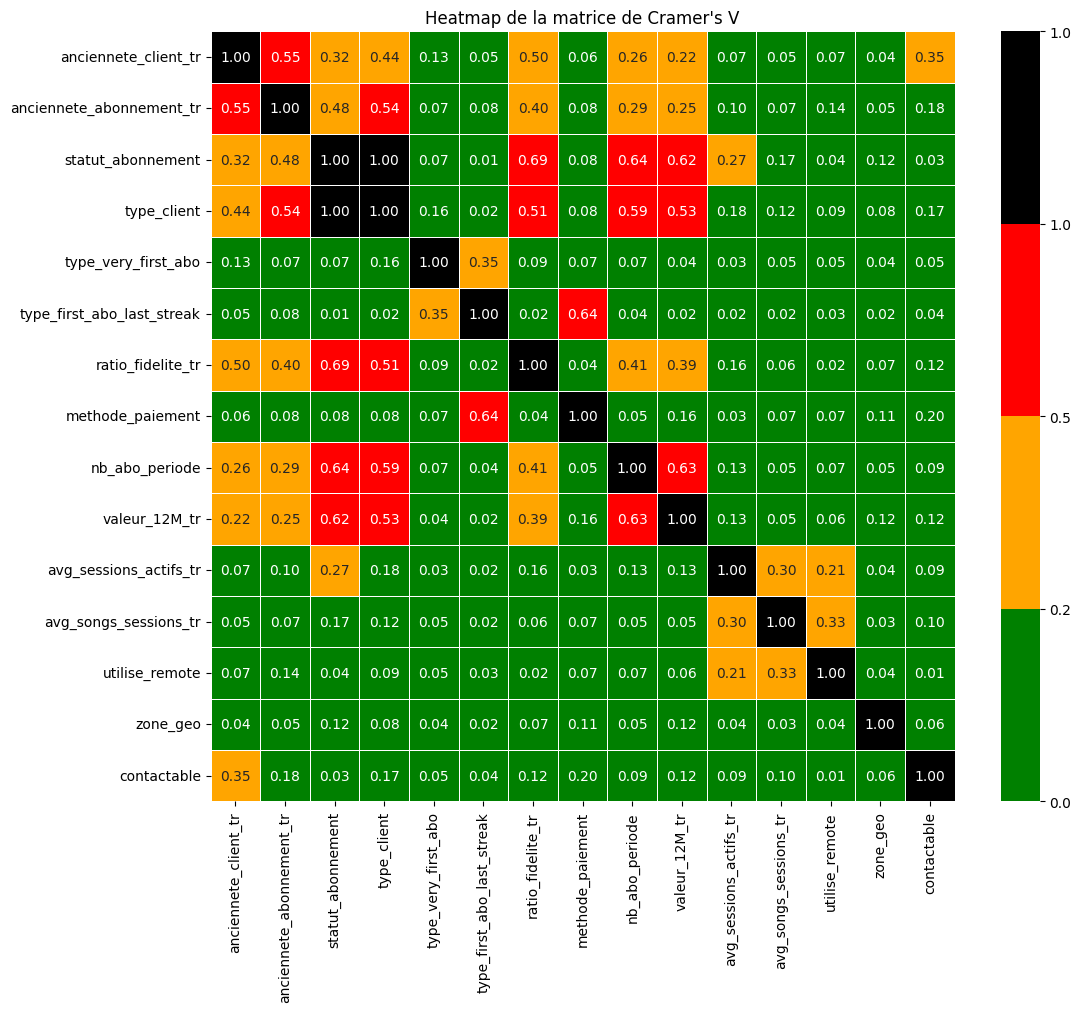

In [15]:
colors = ['green', 'orange', 'red', 'black']
boundaries = [0, 0.2, 0.5001, 1.0, 1.0001]

# 2. Créer la normalisation et la colormap personnalisées
norm = BoundaryNorm(boundaries, len(colors))
cmap = ListedColormap(colors)

# 3. Tracer la heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    cramers_v_matrix.astype(float),
    annot=True,
    cmap=cmap,
    norm=norm,
    fmt='.2f',
    linewidths=.5
)
plt.title('Heatmap de la matrice de Cramer\'s V')
plt.show()

### Lecture de la matrice (heatmap)
Les liaisons qui ressortent :

| Paire | V | Interprétation |
|---|---|---|
| `statut_abonnement` × `type_client` | **1,00** | Identiques : `statut` = actif/non actif, `type_client` le détaille. |
| `statut_abonnement` × `ratio_fidelite` / `nb_abo_periode` / `valeur_12M` | 0,69 / 0,64 / 0,62 | Conséquence du point précédent : ces liens sont ceux de `type_client` (un client « churn » a peu de mois, peu de valeur). |
| `type_client` × `nb_abo_periode` / `valeur_12M` / `ratio_fidelite` | 0,59 / 0,53 / 0,51 | Le statut du client structure fortement sa valeur et sa fidélité. |
| `nb_abo_periode` × `valeur_12M` | 0,63 | Lien mécanique : valeur ≈ nombre de mois × tarif. |
| `anciennete_client` × `anciennete_abonnement` | 0,55 | Deux mesures proches du même concept. |
| `anciennete_client` × `ratio_fidelite` | 0,50 | La fidélité est un ratio rapporté à l'ancienneté. |
| `type_first_abo_last_streak` × `methode_paiement` | 0,64 | Liaison à manier avec prudence : modalités très rares (0,2 à 0,7 % d'offres). |
| `type_very_first_abo` × `type_first_abo_last_streak` | 0,35 | Les deux variables d'acquisition portent une information voisine. |
| `avg_sessions` × `avg_songs` × `utilise_remote` | 0,21 à 0,33 | Les trois variables d'usage sont liées entre elles, mais pas aux autres. |
| `zone_geo` × toutes | ≤ 0,12 | La géographie est indépendante du comportement. |

Les variables d'**usage** et de **géographie** sont donc peu liées au parcours d'abonnement : elles apporteront de l'information nouvelle, à condition de ne pas être noyées sous les variables de cycle de vie.

Statut abonnement et type de client : la liaison est de 1,00. ->
Ces deux variables portent exactement la même information.

Option : combinaison de 2 variables - exemple : actif nouveau pour statut abo et type client

In [16]:
contingency_table = pd.crosstab(df['statut_abonnement'], df['type_client'])
display(contingency_table)

type_client,churn,nouveau,reactivated,retained
statut_abonnement,,,,
actif,0,54621,49865,65120
non_actif,171486,0,0,0


**Lecture** : la table de contingence confirme que `statut_abonnement` n'ajoute rien : tous les « non_actif » sont des « churn » et tous les « actif » sont répartis entre nouveau, reactivated et retained.

**Décision** : On met supprime statut_abonnement qui apporte la meme info que type_client

In [17]:
df = df.drop(['statut_abonnement'], axis=1)

`contactable` est retirée du jeu de données : consigne de la prof car mauvaise qualité de donnée

In [18]:
df = df.drop(['contactable'], axis=1)

## ❗ Liaisons à surveiller (> 0,5) : lecture détaillée par tableaux croisés

### ratio_fidelite_tr x type_client

In [19]:
display (pd.crosstab(df['ratio_fidelite_tr'], df['type_client']))


type_client,churn,nouveau,reactivated,retained
ratio_fidelite_tr,,,,
01_moins_30,84712,0,8307,525
02_30a50,29269,0,8383,1631
03_50a70,27697,17,9704,3187
04_70a90,16275,19,8931,6774
05_90_et_plus,13533,42111,14540,53003
99_vient_de_s_abonner,0,12474,0,0


**Lecture** :
- Les **nouveaux** ont tous une fidélité ≥ 90 % (42 111 + 12 474 « vient de s'abonner » sur 54 621) : par construction, ils viennent de s'abonner.
- Près de la **moitié des churn (49 %)** a une fidélité < 30 % : beaucoup d'abonnés n'ont fait qu'un passage bref.
- 81 % des **retained** sont à plus de 90 %.
- Les **reactivated** sont dispersés sur tous les niveaux : leur parcours est discontinu.

Conclusion : `ratio_fidelite` et `type_client` se recouvrent en partie (V = 0,51), mais la fidélité apporte la nuance au sein de chaque type : elle est conservée.

### valeur_12M_tr x type_client

In [20]:
display (pd.crosstab(df['valeur_12M_tr'], df['type_client']))

type_client,churn,nouveau,reactivated,retained
valeur_12M_tr,,,,
00_moins_10,80490,13513,3521,2
01_10a15,23313,4981,2810,0
02_15a20,15859,4102,3150,0
03_20a25,8219,1218,1522,0
04_25a30,8322,4007,2755,0
05_30a40,12657,5487,5243,3
06_40a50,8636,7941,5651,0
07_50a60,5009,3773,4447,3
08_60a70,4444,4168,6849,3341


**Lecture** :
- Les **retained** sont quasiment tous (99,99 %) à plus de 60 € de CA sur la période.
- 60 % des **churn** génèrent moins de 15 €.
- Les **nouveaux** et **reactivated** occupent toute l'échelle de valeur.

La valeur mesure donc le **poids économique** du client, au-delà de son statut. C'est le KPI business de l'étude : on la garde en variable active (voir 5.4).

###type_very_first_abo x methode_paiement

In [21]:
display (pd.crosstab(df['type_very_first_abo'], df['methode_paiement']))

methode_paiement,Amazon,Android,Apple,Credit,Others,Paypal,Stripe
type_very_first_abo,,,,,,,
offert,11,695,1506,60,0,901,5293
payant,2827,52078,110233,535,1,36728,128181
reduc,8,114,188,7,0,474,1252


**Lecture** : les offres promotionnelles (offertes ou avec réduction) passent majoritairement par **Stripe, donc par le web** : 62 % des offres « offert » et 61 % des « reduc », alors que Stripe ne représente que 39,5 % de l'ensemble des paiements. Les promotions sont donc plutôt un levier web que store.

### ancienneté client × ancienneté abonnement

In [22]:
display (pd.crosstab(df['anciennete_client_tr'], df['anciennete_abonnement_tr']))

anciennete_abonnement_tr,00_moins_1_mois,01_1_mois,02_2_mois,03_3_mois,04_4_mois,05_5_mois,06_6_mois,07_7a9_mois,08_10a12_mois,09_13a15_mois,10_16a18_mois,11_19a21_mois,12_22a24_mois,13_25a30_mois,14_31a36_mois,15_37a48_mois,16_49a60_mois,17_61a84_mois,18_85a120_mois,19_121_mois_et_plus
anciennete_client_tr,,,,,,,,,,,,,,,,,,,,
00_moins_1_mois,12474,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
01_1_mois,251,12429,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
02_2_mois,323,192,9940,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
03_3_mois,310,291,158,9326,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
04_4_mois,258,290,251,129,8907,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
05_5_mois,296,332,252,225,164,11041,0,0,0,0,0,0,0,0,0,0,0,0,0,0
06_6_mois,1174,705,602,547,603,300,28745,0,0,0,0,0,0,0,0,0,0,0,0,0
07_7a9_mois,1152,1273,988,694,611,678,959,29124,0,0,0,0,0,0,0,0,0,0,0,0
08_10a12_mois,1190,921,746,654,737,715,1204,1583,22555,0,0,0,0,0,0,0,0,0,0,0


**Lecture** :
- Le triangle supérieur est vide : l'ancienneté de l'abonnement en cours est toujours ≤ à l'ancienneté client.
- Pour les clients de moins de 4 mois, tout est sur la **diagonale** (12 474 ; 12 429 ; 9 940 ; 9 326) : l'abonnement en cours date de leur arrivée.
- Pour les clients plus anciens, la masse se déplace sous la diagonale : ces clients ont connu des **interruptions puis des reprises**.

Les deux anciennetés décrivent le même concept (V = 0,55). On garde l'ancienneté client, qui couvre tout le parcours.

### CA x nb abo periode

In [23]:
display (pd.crosstab(df['nb_abo_periode'], df['valeur_12M_tr']))

valeur_12M_tr,00_moins_10,01_10a15,02_15a20,03_20a25,04_25a30,05_30a40,06_40a50,07_50a60,08_60a70,09_70a90,10_90a110,11_110_et_plus
nb_abo_periode,,,,,,,,,,,,
1,95819,1200,18,1,3,1,6,0,0,0,0,0
10,2,1,1,0,3,6,5,408,5692,556,2417,6
11,3,1,1,0,3,10,4,10,3577,5030,3646,27
12,8,1,1,0,1,3,5,8,3304,42842,2278,23186
2,1617,29439,9785,111,3,1,1,0,0,0,0,1
3,35,423,13119,6168,5586,81,1,0,1,1,0,0
4,19,12,157,4629,8744,5310,18,0,0,0,0,0
5,3,12,15,40,710,10682,3975,5,0,1,0,1
6,2,6,10,7,17,7207,3798,3730,10,1,0,0


**Lecture** : les deux variables sont reliées mécaniquement. 96 000 clients à 1 seul mois sont à moins de 10 € ; les clients à 12 mois sont presque tous entre 70 et 90 € (≈ 43 000), soit environ 6 à 7,5 € par mois. La valeur dépend du nombre de mois et du tarif.

### Bilan de l'analyse des liaisons

| Décision | Raison |
|---|---|
| Supprimer `statut_abonnement` | V = 1,00 avec `type_client` |
| Retirer `contactable` de la segmentation | variable de joignabilité, pas de comportement |
| Fusionner `avg_sessions` et `avg_songs` en un profil d'usage | même concept, V = 0,30 |
| Fusionner `type_very_first_abo` et `type_first_abo_last_streak` | même concept, V = 0,35 |
| Ne garder qu'une ancienneté (client) dans les variables actives | V = 0,55 |
| Garder `valeur_12M` en active et passer `nb_abo_periode` en supplémentaire | V = 0,63 : on ne double pas l'information |

# 5. Regroupement des modalités

**Objectif** : obtenir des variables qui donnent de bonnes ACM, c'est-à-dire :
1. **aucune modalité rare** (< 5 %) : une modalité rare reçoit un poids très élevé en ACM et attire un axe à elle seule ;
2. **peu de modalités par variable** (2 à 5) pour équilibrer le poids des variables ;
3. **des regroupements cohérents avec le marketing** : les classes doivent correspondre à des profils que l'on sait nommer et cibler ;
4. **pas de redondance** entre variables actives (étape 4).

Les regroupements passent par `map_strict` : si une modalité est oubliée, le code s'arrête.

Pour les décisions de regroupements, on regarde les modalités rares (<5%)

Colonnes avec au moins une modalité ayant moins de 5% des valeurs (hors NaN) :
- anciennete_client_tr
- anciennete_abonnement_tr
- type_very_first_abo
- type_first_abo_last_streak
- ratio_fidelite_tr
- methode_paiement
- nb_abo_periode
- valeur_12M_tr
- avg_sessions_actifs_tr
- avg_songs_sessions_tr
- zone_geo

--- Visualisation des répartitions ---


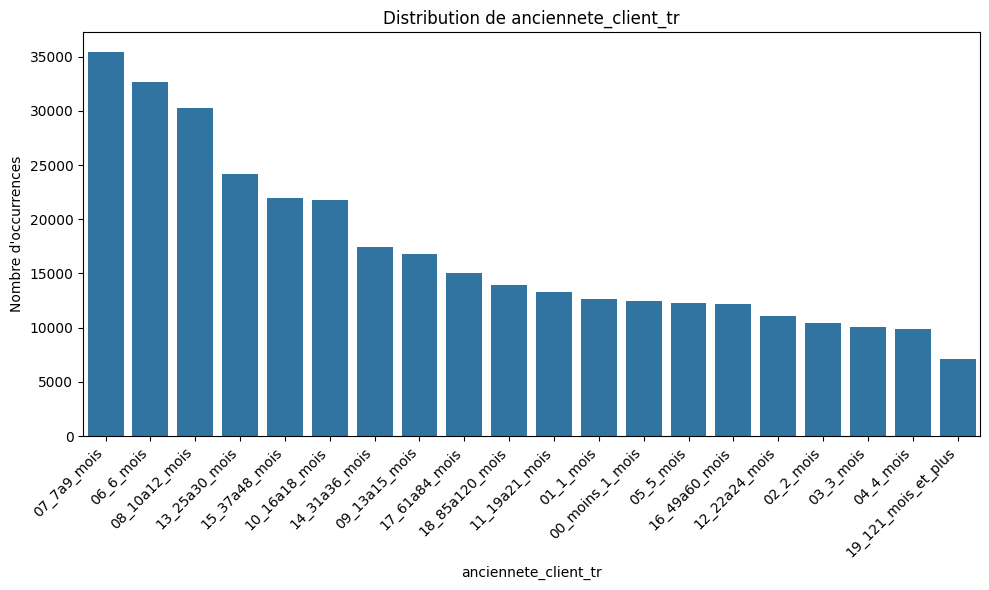

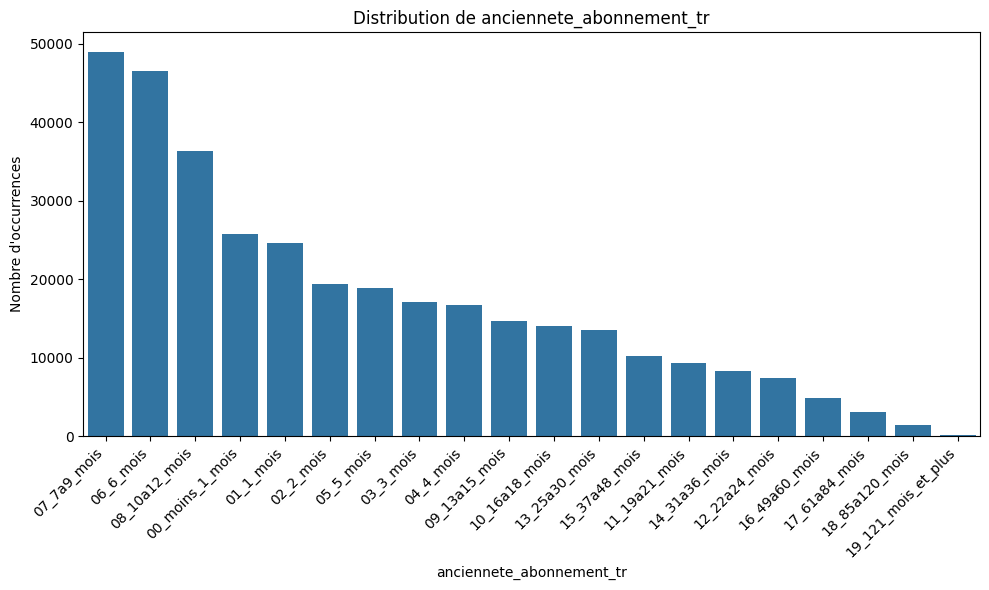

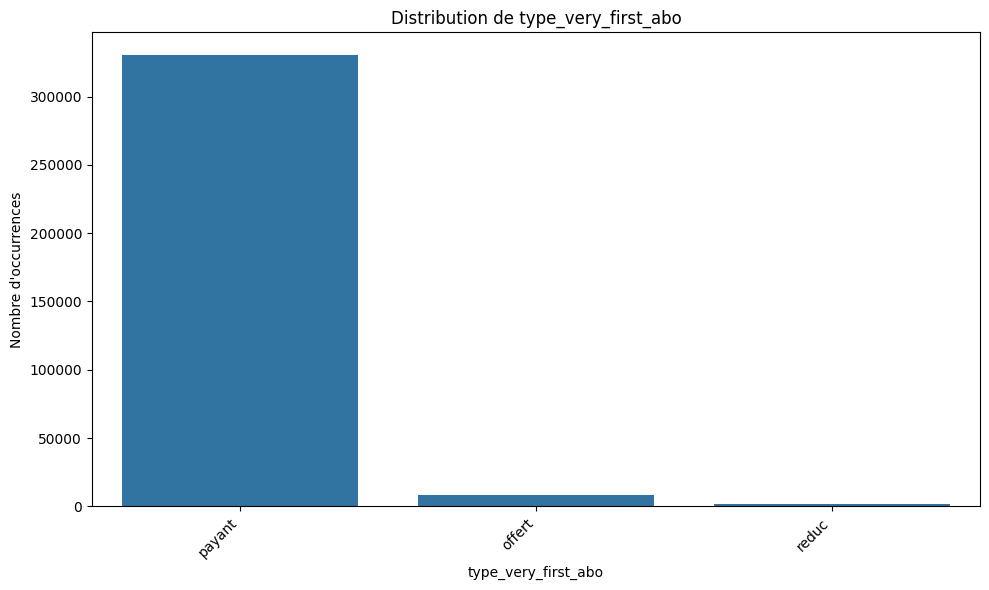

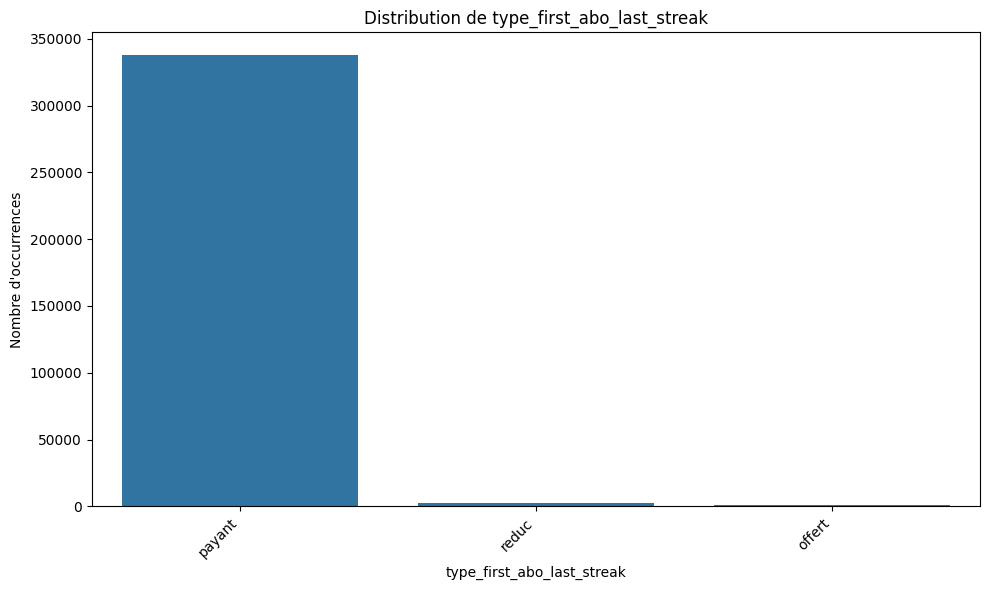

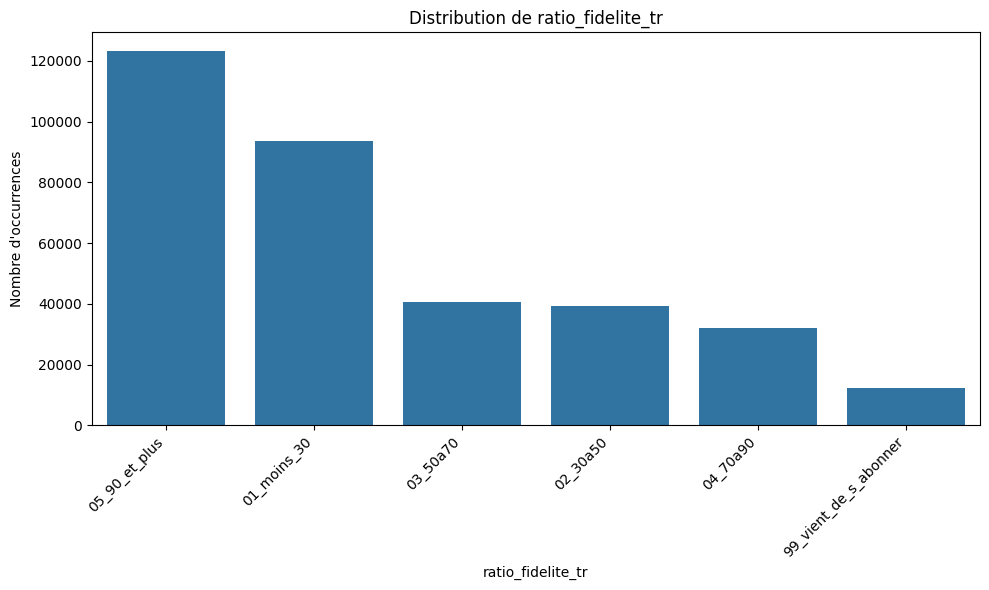

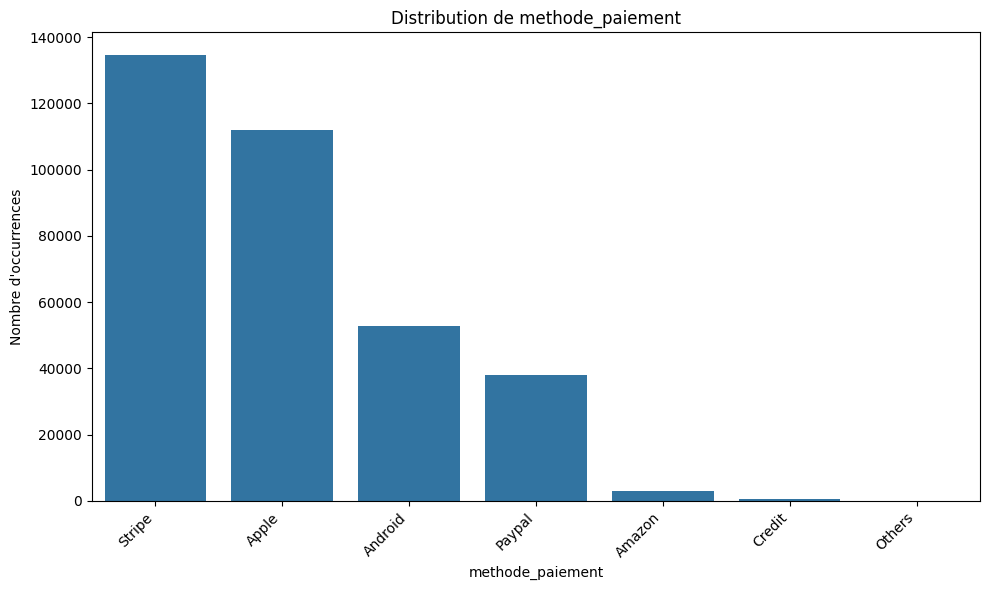

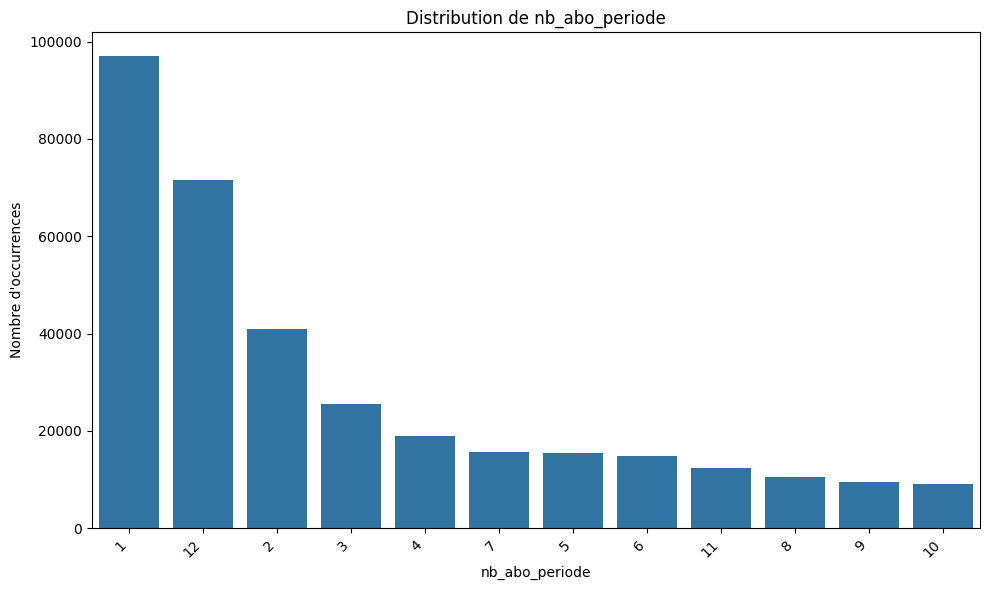

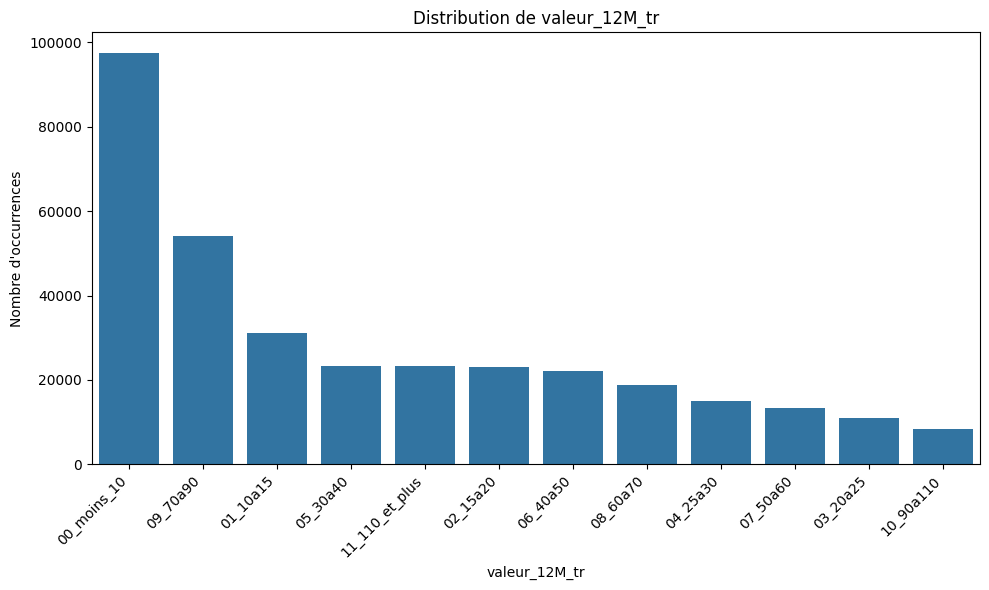

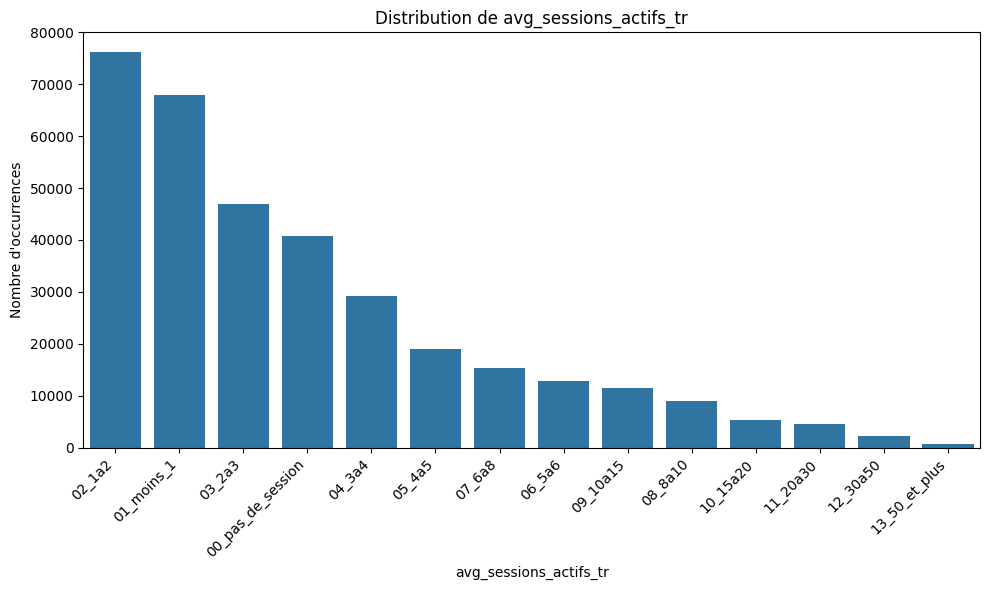

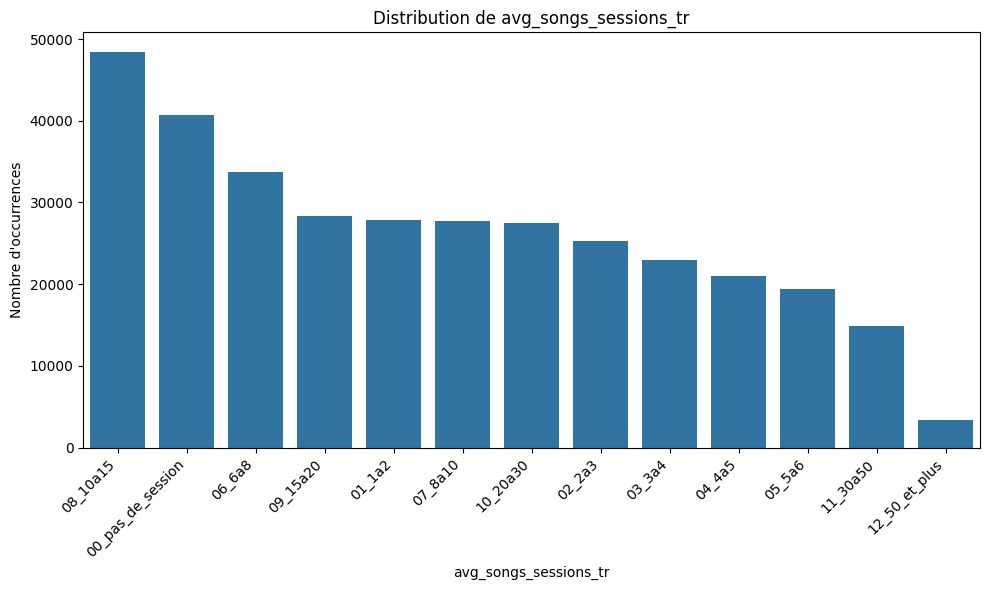

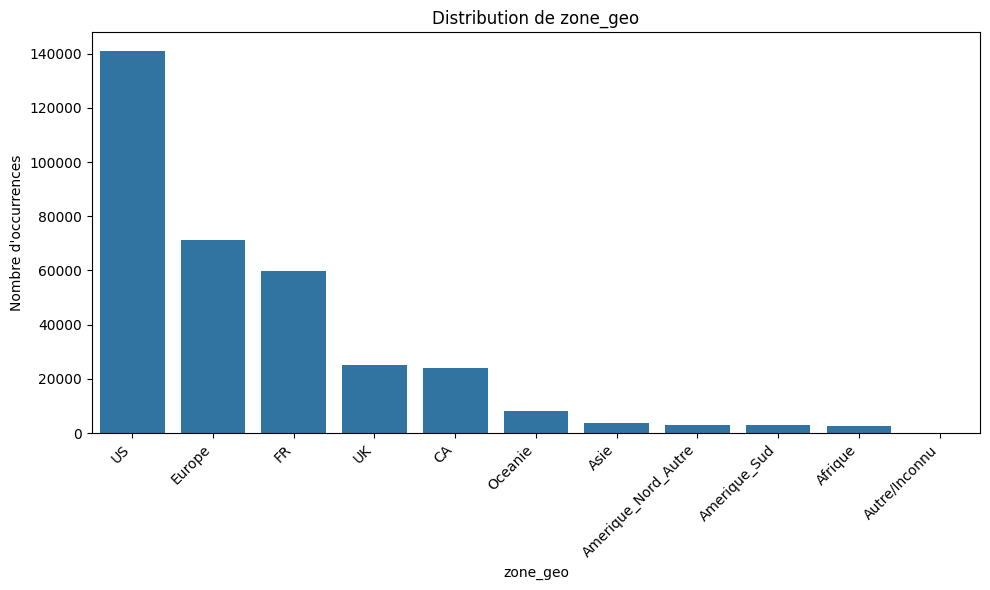

In [24]:
low_frequency_columns = []
seuil = 5

for col in df.columns:
    # Exclure les NaN du calcul des fréquences
    value_counts = df[col].value_counts(dropna=True, normalize=True) * 100

    # Vérifie si au moins une modalité non nulle a une fréquence < seuil
    if any(value_counts < seuil):
        low_frequency_columns.append(col)

# Exclure 'id_anonyme' de la liste car il ne doit pas être regroupé ou visualisé de cette manière
if 'id_anonyme' in low_frequency_columns:
    low_frequency_columns.remove('id_anonyme')

print("Colonnes avec au moins une modalité ayant moins de 5% des valeurs (hors NaN) :")
for col in low_frequency_columns:
    print(f"- {col}")


print("\n--- Visualisation des répartitions ---")

# Générer un histogramme pour chaque colonne dans low_frequency_columns
for col in low_frequency_columns:
    plt.figure(figsize=(10, 6))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'Distribution de {col}')
    plt.xlabel(col)
    plt.ylabel('Nombre d\'occurrences')
    plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
    plt.tight_layout()
    plt.show()

**Lecture** : 11 variables sur 13 ont au moins une modalité sous 5 %. Seules `type_client` et `utilise_remote` n'en ont pas.

In [25]:
for col in low_frequency_columns :
  print(f"Frequences pour la colonne '{col}':")
  display(df[col].value_counts(normalize=True) * 100)
  print("----------------------------------------")

Frequences pour la colonne 'anciennete_client_tr':


,proportion
anciennete_client_tr,
07_7a9_mois,10.401593
06_6_mois,9.579820
08_10a12_mois,8.884700
13_25a30_mois,7.077269
15_37a48_mois,6.426126
10_16a18_mois,6.388013
14_31a36_mois,5.125010
09_13a15_mois,4.914803
17_61a84_mois,4.420215


----------------------------------------
Frequences pour la colonne 'anciennete_abonnement_tr':


,proportion
anciennete_abonnement_tr,
07_7a9_mois,14.367385
06_6_mois,13.639135
08_10a12_mois,10.655776
00_moins_1_mois,7.537556
01_1_mois,7.228255
02_2_mois,5.696410
05_5_mois,5.530766
03_3_mois,5.018294
04_4_mois,4.900437


----------------------------------------
Frequences pour la colonne 'type_very_first_abo':


...

----------------------------------------
Frequences pour la colonne 'avg_songs_sessions_tr':


,proportion
avg_songs_sessions_tr,
08_10a15,14.188547
00_pas_de_session,11.936955
06_6a8,9.897623
09_15a20,8.322095
01_1a2,8.180491
07_8a10,8.123908
10_20a30,8.048562
02_2a3,7.402402
03_3a4,6.712852


----------------------------------------
Frequences pour la colonne 'zone_geo':


,proportion
zone_geo,
US,41.291499
Europe,20.857716
FR,17.534859
UK,7.337023
CA,7.035932
Oceanie,2.404923
Asie,1.071265
Amerique_Nord_Autre,0.846692
Amerique_Sud,0.821186


----------------------------------------


**Lecture** : voici ce qui justifie les regroupements.
- `anciennete_client_tr` et `anciennete_abonnement_tr` : 20 modalités chacune, dont 13 et 12 sous 5 %.
- `ratio_fidelite_tr` : « vient de s'abonner » (3,7 %).
- `methode_paiement` : `Amazon` 0,8 %, `Credit` 0,2 %, `Others` 0,0003 % (1 individu).
- `type_very_first_abo` / `type_first_abo_last_streak` : offres à 3,1 % et 0,9 %.
- `nb_abo_periode`, `valeur_12M_tr` : 12 modalités, la plupart sous 7 %.
- `avg_sessions` / `avg_songs` : 14 et 13 modalités, dont les plus fortes consommations sont très rares.
- `zone_geo` : `Autre/Inconnu` = 22 individus.

## 5.1 `type_client`

### Type client

On conserve `type_client` car statistuquement, elle est viable elle ne présente pas de modalité rare. C'est la segmentation business déjà connue des équipes ; elle est conservée car elle est centrale pour répondre à la problématique.

## 5.2 Ancienneté (client et abonnement)

### Ancienneté abo et client

Les deux ancienneté apportent le même type d'informations et posent problème car elles ont bcp de modalités.
`anciennete_abonnement_tr` (V = 0,55 avec l'ancienneté client, 0,54 avec `type_client`) est retirée des variables actives : l'information « depuis combien de temps le cycle courant »
est déjà portée par `type_client` + `fidelite`. L'ancienneté client est regroupée en **4 classes équilibrées** (20 / 29 / 31 / 21 %).
La notion de *continuité* (série courante vs historique total) est conservée comme variable **supplémentaire**

In [26]:
MAP_ANC_CLIENT = {
    '00_moins_1_mois':'<6m', '01_1_mois':'<6m', '02_2_mois':'<6m', '03_3_mois':'<6m',
    '04_4_mois':'<6m', '05_5_mois':'<6m',
    '06_6_mois':'6-12m', '07_7a9_mois':'6-12m', '08_10a12_mois':'6-12m',
    '09_13a15_mois':'1-3ans', '10_16a18_mois':'1-3ans', '11_19a21_mois':'1-3ans',
    '12_22a24_mois':'1-3ans', '13_25a30_mois':'1-3ans', '14_31a36_mois':'1-3ans',
    '15_37a48_mois':'>3ans', '16_49a60_mois':'>3ans', '17_61a84_mois':'>3ans',
    '18_85a120_mois':'>3ans', '19_121_mois_et_plus':'>3ans',
}
df['anciennete_client_reg'] = map_strict(df['anciennete_client_tr'], MAP_ANC_CLIENT)

In [27]:
display(df['anciennete_client_reg'].value_counts(normalize=True) * 100)

,proportion
anciennete_client_reg,
1-3ans,30.652141
6-12m,28.866112
>3ans,20.592978
<6m,19.888769


**Lecture** : 4 classes équilibrées : < 6 mois (19,9 %), 6-12 mois (28,9 %), 1-3 ans (30,7 %), > 3 ans (20,6 %). Elles correspondent à des étapes de vie client : découverte, première année, installation, client historique. Aucune modalité n'est sous 5 %.

`anciennete_abo_reg` (durée de l'abonnement en cours, 5 classes) est construite pour être projetée en **variable supplémentaire** (voir § 7).

In [28]:
MAP_ANC_ABO = {k: v for k, v in {
    '00_moins_1_mois':'0-3m','01_1_mois':'0-3m','02_2_mois':'0-3m','03_3_mois':'0-3m',
    '04_4_mois':'4-6m','05_5_mois':'4-6m','06_6_mois':'4-6m',
    '07_7a9_mois':'7-12m','08_10a12_mois':'7-12m',
    '09_13a15_mois':'1-2ans','10_16a18_mois':'1-2ans','11_19a21_mois':'1-2ans','12_22a24_mois':'1-2ans'}.items()}
MAP_ANC_ABO.update({k: '>2ans' for k in ['13_25a30_mois','14_31a36_mois','15_37a48_mois','16_49a60_mois',
                                          '17_61a84_mois','18_85a120_mois','19_121_mois_et_plus']})
df['anciennete_abo_reg'] = map_strict(df['anciennete_abonnement_tr'], MAP_ANC_ABO)

In [29]:
display(df['anciennete_abo_reg'].value_counts(normalize=True) * 100)

,proportion
anciennete_abo_reg,
0-3m,25.480516
7-12m,25.023161
4-6m,24.070339
1-2ans,13.303742
>2ans,12.122243


**Lecture** : les 5 classes ont toutes plus de 12 %.

## 5.3 Fidélité

### Fidelite
`fidelite_reg` – part des mois abonnés depuis le 1er abonnement
Regroupement en 3 niveaux (39 / 21 / 40 %).

In [30]:
MAP_FIDELITE = {
    '01_moins_30':'1_faible(<50%)', '02_30a50':'1_faible(<50%)',
    '03_50a70':'2_moyenne(50-90%)', '04_70a90':'2_moyenne(50-90%)',
    '05_90_et_plus':'3_forte(>=90%)', '99_vient_de_s_abonner':'vient_de_s_abonner',
}
df['fidelite_reg'] = map_strict(df['ratio_fidelite_tr'], MAP_FIDELITE)

In [31]:
display(df['fidelite_reg'].value_counts(normalize=True) * 100)

,proportion
fidelite_reg,
1_faible(<50%),38.941693
3_forte(>=90%),36.115476
2_moyenne(50-90%),21.285753
vient_de_s_abonner,3.657078


**Lecture** : 4 niveaux (39 / 21 / 40 %/3%
). Une fidélité **faible** correspond à des clients occasionnels, **moyenne** à des abonnés qui reviennent par vagues, **forte** aux clients présents presque chaque mois depuis leur arrivée.

## 5.4 Chiffre d'affaires (valeur)

`valeur_12M_reg` – chiffre d'affaires sur la période (conservée en variable ACTIVE)
`valeur_12M` est le CA généré : c'est le KPI business, on la garde comme variable active, en 4 classes (38 / 14 / 17 / 31 %)
**< 15 €**, **15-30 €**, **30-60 €**, **> 60 €**.

`nb_abo_periode` (V = 0,63 avec la valeur) passe en variable **supplémentaire** : elle sert à lire *comment* la valeur a été produite
(un seul mois ? abonné permanent ?) sans doubler la valeur dans l'ACM.

In [32]:
MAP_VALEUR = {'00_moins_10':'<15EUR', '01_10a15':'<15EUR',
              '02_15a20':'15-30EUR', '03_20a25':'15-30EUR', '04_25a30':'15-30EUR',
              '05_30a40':'30-60EUR', '06_40a50':'30-60EUR', '07_50a60':'30-60EUR',
              '08_60a70':'>60EUR', '09_70a90':'>60EUR', '10_90a110':'>60EUR', '11_110_et_plus':'>60EUR'}
df['valeur_12M_reg'] = map_strict(df['valeur_12M_tr'], MAP_VALEUR)

In [33]:
display(df['valeur_12M_reg'].value_counts(normalize=True) * 100)

,proportion
valeur_12M_reg,
<15EUR,37.711233
>60EUR,30.624582
30-60EUR,17.253410
15-30EUR,14.410775


**Lecture** : répartition équilibrée, sans modalité rare : 37,7 % sous 15 €, 14,4 % entre 15 et 30 €, 17,3 % entre 30 et 60 €, 30,6 % au-dessus de 60 €. La classe > 60 € regroupe les gros contributeurs (abonnés permanents), la classe < 15 € les clients ponctuels.

## 5.5 Méthode de paiement

### Méthode de paiement

On remarque que Stripe est le moyen de paiement le plus utilisé or il est utilisable que sur le web -> canal principal de karafun ( site + utilisé que l'app)

Au niveau du tarif, le paiement via le web (Stripe,Paypal et credit) est moins cher (7,99€) que le paiement sur l'appli (9,99€)  

La variable est ramenée à **2 modalités de canal** : `paiement_web` (Stripe, PayPal, Crédit) et `paiement_appli` (Apple, Android, Amazon). Le canal est un levier de communication (e-mail ou site d'un côté, notifications in-app de l'autre) ; le prix ne sert pas ici de mesure de valeur, qui est portée par `valeur_12M_reg`.

In [34]:
MAP_CANAL = {'Stripe':'paiement_web', 'Paypal':'paiement_web', 'Credit':'paiement_web',
             'Apple':'paiement_appli', 'Android':'paiement_appli', 'Amazon':'paiement_appli',
             'Others':np.nan}                       # 1 individu -> exclu
df['canal_paiement'] = df['methode_paiement'].map(MAP_CANAL)
assert df['methode_paiement'].isin(MAP_CANAL).all()
print('Individus sans canal (exclus ACM) :', df['canal_paiement'].isna().sum())

Individus sans canal (exclus ACM) : 1


In [35]:
print(df['canal_paiement'].value_counts(normalize=True) * 100)

canal_paiement
paiement_web      50.845962
paiement_appli    49.154038
Name: proportion, dtype: float64


**Lecture** : 50,8 % web / 49,2 % appli. Un seul individu (`Others`) est exclu de l'ACM. `Credit` (0,18 %) est supposé être du paiement web (hypothèse à confirmer).

## 5.6 Usage du service : fusion de `avg_sessions_actifs_tr` et `avg_songs_sessions_tr`

### avg_sessions_actifs_tr × avg_songs_sessions_tr
-> profil_usage – fusion

In [36]:
df['avg_sessions_actifs_tr'].value_counts(normalize=True) * 100

,proportion
avg_sessions_actifs_tr,
02_1a2,22.339721
01_moins_1,19.940661
03_2a3,13.736470
00_pas_de_session,11.936955
04_3a4,8.535527
05_4a5,5.571224
07_6a8,4.504650
06_5a6,3.742685
09_10a15,3.356572


- Grosse concentration sur les valeurs basses or sans utilisation -> 42% font entre 1 et 2 sessions par mois
- Important d'isoler les clients sans sessions de ceux avec au moins 1 sessions

In [37]:
df['avg_songs_sessions_tr'].value_counts(normalize=True) * 100

,proportion
avg_songs_sessions_tr,
08_10a15,14.188547
00_pas_de_session,11.936955
06_6a8,9.897623
09_15a20,8.322095
01_1a2,8.180491
07_8a10,8.123908
10_20a30,8.048562
02_2a3,7.402402
03_3a4,6.712852


Une session de 10 chansons -> courte

Les deux variables décrivent le même concept (comment l'abonné utilise le service) et partagent le groupe « aucune session ».
On croise **fréquence** (sessions / mois : < 2 vs ≥ 2) et **profondeur** (chansons / session : < 10 vs ≥ 10) :

| Profil | Lecture marketing |
|---|---|
| `dormant` | abonné sans aucune session : risque de churn, message d'activation |
| `rare_courte` | usage léger et ponctuel |
| `rare_longue` | peu de sessions mais longues → usage « soirée / événement » |
| `frequent_courte` | usage régulier, entraînement individuel |
| `frequent_longue` | power users, ambassadeurs potentiels |


Les seuils retenus sont : **< 2 sessions par mois** = rare, **≥ 2** = fréquent ; **< 10 chansons par session** = courte, **≥ 10** = longue.

In [38]:
SEUIL_FREQ  = {'00_pas_de_session':None, '01_moins_1':'rare', '02_1a2':'rare'}   # tout le reste = fréquent (>=2/mois)
SONGS_COURT = ['01_1a2','02_2a3','03_3a4','04_4a5','05_5a6','06_6a8','07_8a10']    # < 10 chansons / session
SONGS_LONG  = ['08_10a15','09_15a20','10_20a30','11_30a50','12_50_et_plus']        # >= 10

assert set(df['avg_songs_sessions_tr']) <= set(SONGS_COURT + SONGS_LONG + ['00_pas_de_session']), \
    set(df['avg_songs_sessions_tr']) - set(SONGS_COURT + SONGS_LONG + ['00_pas_de_session'])

def profil_usage(row):
    s, c = row['avg_sessions_actifs_tr'], row['avg_songs_sessions_tr']
    if s == '00_pas_de_session':
        return '0_dormant'
    freq = 'rare' if SEUIL_FREQ.get(s) == 'rare' else 'frequent'
    prof = 'longue' if c in SONGS_LONG else 'courte'
    return f"{freq}_{prof}"

df['profil_usage'] = df[['avg_sessions_actifs_tr', 'avg_songs_sessions_tr']].apply(profil_usage, axis=1)


In [39]:
display(df['profil_usage'].value_counts(normalize=True) * 100)

,proportion
profil_usage,
frequent_courte,28.360091
rare_courte,23.812051
rare_longue,18.468331
frequent_longue,17.422572
0_dormant,11.936955


**Lecture** : les 5 profils dépassent tous 11 % : 28,4 % fréquent-court, 23,8 % rare-court, 18,5 % rare-long, 17,4 % fréquent-long, 11,9 % dormants. Cette variable remplace deux variables qui comptaient chacune le groupe « aucune session » : il n'est plus compté qu'une fois.

## 5.7 Intensité d'abonnement (`nb_abo_periode`)

### nb_abo_periode

Bcp de modalité, on va créer renommer la variable pour lui donner un nom plus parlant et essayer de catégoriser les clients selon leurs usages

**intensité** : nombre de mois abonnés sur 12 mois


In [40]:
def regroupe_nb_abo(n):
    n = int(n)
    if n == 1:   return '1_ponctuel(1m)'
    if n <= 5:   return '2_occasionnel(2-5m)'
    if n <= 11:  return '3_regulier(6-11m)'
    return '4_permanent(12m)'
df['intensite_12m'] = df['nb_abo_periode'].map(regroupe_nb_abo)

In [41]:
display(df["intensite_12m"].value_counts(normalize=True)*100)

,proportion
intensite_12m,
2_occasionnel(2-5m),29.524586
1_ponctuel(1m),28.452148
3_regulier(6-11m),21.021015
4_permanent(12m),21.002252


**Lecture** : 4 classes bien équilibrées, avec une logique marketing : ponctuel (28,5 %, un seul mois : essai ou achat unique), occasionnel (29,5 %, saisonnier), régulier (21,0 %), permanent (21,0 %, abonné toute l'année). C'est la cible naturelle d'une offre annuelle.

Cette variable est liée à la valeur (V = 0,63) : elle est donc utilisée en **supplémentaire**.

## 5.8 Type d'abonnement (acquisition) : fusion de deux variables

### type_very_first_abo x type_first_abo_last_streak
On va fusionner les 2 variables car elle sont bien associés entre elles, à hauteur de 0,35 et elles apportent globalement la même information

Vérifie si le tout premier abonnement OU le premier abonnement de la dernière série n'est pas payant (!= 'payant'), c'est-à-dire s'il s'agit d'une offre gratuite (offert) ou d'une promotion/réduction (reduc) sinon c'est plein tarif

In [42]:
# acquisition : fusion des 2 variables 'type_*_abo'
df['type_abo'] = np.where((df['type_very_first_abo'] != 'payant') |
                                   (df['type_first_abo_last_streak'] != 'payant'),
                                   'offre_promo/offerte', 'plein_tarif')

In [43]:
display(df["type_abo"].value_counts(normalize=True)*100)

,proportion
type_abo,
plein_tarif,96.394521
offre_promo/offerte,3.605479


**Lecture** : 96,4 % des clients sont à plein tarif et **3,6 %** ont bénéficié d'une offre (offerte ou promotionnelle). Cette modalité est sous le seuil de 5 % : si elle était active, elle capterait un axe à elle seule. La variable est donc **supplémentaire** : elle sert à vérifier si les clients venus par promotion se retrouvent dans un groupe particulier.

## 5.9 Zone géographique

###zone_geo

`Autre/Inconnu` (22 individus) est regroupé avec `Reste_du_monde`. Les autres zones sont regroupées par proximité de marché et de langue (Amérique du Nord, Europe hors France, France, reste du monde).

In [44]:
display(df["zone_geo"].value_counts())

,count
zone_geo,
US,140842
Europe,71144
FR,59810
UK,25026
CA,23999
Oceanie,8203
Asie,3654
Amerique_Nord_Autre,2888
Amerique_Sud,2801


In [45]:
MAP_ZONE = {
    'FR':                  'FR',
    'Europe':              'Europe_hors_FR',
    'UK':                  'Europe_hors_FR',
    'US':                  'Amerique_Nord',
    'CA':                  'Amerique_Nord',
    'Amerique_Nord_Autre': 'Amerique_Nord',
    'Asie':                'Reste_du_monde',
    'Afrique':             'Reste_du_monde',
    'Oceanie':             'Reste_du_monde',
    'Oceani':              'Reste_du_monde',
    'Amerique_Sud':        'Reste_du_monde',
    'Autre/Inconnu' : 'Reste_du_monde'
}

In [46]:
df['zone_geo_reg'] = df['zone_geo'].replace(MAP_ZONE)

In [47]:
display(df["zone_geo_reg"].value_counts(normalize=True)*100)

,proportion
zone_geo_reg,
Amerique_Nord,49.174123
Europe_hors_FR,28.194739
FR,17.534859
Reste_du_monde,5.096279


**Lecture** : 4 zones : Amérique du Nord (49,2 %), Europe hors FR (28,2 %), France (17,5 %), reste du monde (5,1 %). Elles dépassent toutes le seuil de 5 %.

La zone n'est liée à aucune autre variable (V ≤ 0,12). Elle est utilisée en **variable supplémentaire** : elle ne construira pas les groupes, mais elle dira dans quel marché se trouve chaque groupe, donc quelle langue utiliser pour communiquer.

# 6. Constitution des jeux de données

Deux jeux sont construits pour **comparer** une ACM sur les variables brutes et une ACM sur les variables regroupées :
- `df_base` : variables d'origine, sans regroupement (hors `statut_abonnement` et `contactable`) ;
- `df_regrouped` : variables regroupées, avec toutes celles construites à l'étape 5.

In [48]:
df_base_columns = [
    'id_anonyme',
    'anciennete_client_tr',
    'anciennete_abonnement_tr',
    'type_client',
    'type_very_first_abo',
    'type_first_abo_last_streak',
    'ratio_fidelite_tr',
    'methode_paiement',
    'nb_abo_periode',
    'valeur_12M_tr',
    'avg_sessions_actifs_tr',
    'avg_songs_sessions_tr',
    'utilise_remote',
    'zone_geo'
]
df_base = df[df_base_columns].copy()
print("df_base created with the following columns:")
display(df_base.head())
print(f"Shape of df_base: {df_base.shape}")

df_base created with the following columns:


,id_anonyme,anciennete_client_tr,anciennete_abonnement_tr,type_client,type_very_first_abo,type_first_abo_last_streak,ratio_fidelite_tr,methode_paiement,nb_abo_periode,valeur_12M_tr,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,zone_geo
0,fbb58c58395ab62899c58d6a52f8159ca12ddd7f46bfe2...,00_moins_1_mois,00_moins_1_mois,nouveau,payant,payant,99_vient_de_s_abonner,Apple,1,00_moins_10,02_1a2,01_1a2,non,US
1,8c981dbb88db4abcfd1c07b30ec42c370195fabaf74b8a...,00_moins_1_mois,00_moins_1_mois,nouveau,payant,payant,99_vient_de_s_abonner,Android,1,00_moins_10,03_2a3,02_2a3,non,Europe
2,a4b6c3d31fb413aa830dbb423bd3d8446438dae71d9973...,00_moins_1_mois,00_moins_1_mois,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,03_2a3,09_15a20,non,Europe
3,ef9a45455295911d59cd8a9c76d32d582709e40a5a238f...,00_moins_1_mois,00_moins_1_mois,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,02_1a2,09_15a20,non,CA
4,91d37bd372c738eddb00a6b2878877161fb26a2a519bf8...,00_moins_1_mois,00_moins_1_mois,nouveau,payant,payant,99_vient_de_s_abonner,Paypal,1,00_moins_10,00_pas_de_session,00_pas_de_session,non,FR


Shape of df_base: (341092, 14)


In [49]:
df_regrouped_columns = [
    'id_anonyme',
    'anciennete_client_reg',
    'anciennete_abo_reg',
    'type_client',
    'type_abo',
    'fidelite_reg',
    'canal_paiement',
    'intensite_12m',
    'valeur_12M_reg',
    'profil_usage',
    'utilise_remote',
    'zone_geo_reg'
]
df_regrouped = df[df_regrouped_columns].copy()
print("df_regrouped created with the following columns:")
display(df_regrouped.head())
print(f"Shape of df_regrouped: {df_regrouped.shape}")

df_regrouped created with the following columns:


,id_anonyme,anciennete_client_reg,anciennete_abo_reg,type_client,type_abo,fidelite_reg,canal_paiement,intensite_12m,valeur_12M_reg,profil_usage,utilise_remote,zone_geo_reg
0,fbb58c58395ab62899c58d6a52f8159ca12ddd7f46bfe2...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_appli,1_ponctuel(1m),<15EUR,rare_courte,non,Amerique_Nord
1,8c981dbb88db4abcfd1c07b30ec42c370195fabaf74b8a...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_appli,1_ponctuel(1m),<15EUR,frequent_courte,non,Europe_hors_FR
2,a4b6c3d31fb413aa830dbb423bd3d8446438dae71d9973...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_web,1_ponctuel(1m),<15EUR,frequent_longue,non,Europe_hors_FR
3,ef9a45455295911d59cd8a9c76d32d582709e40a5a238f...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_web,1_ponctuel(1m),<15EUR,rare_longue,non,Amerique_Nord
4,91d37bd372c738eddb00a6b2878877161fb26a2a519bf8...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_web,1_ponctuel(1m),<15EUR,0_dormant,non,FR


Shape of df_regrouped: (341092, 12)


## Récapitulatif des variables

**Variables actives (7)** : celles qui construisent les axes.
`type_client` · `anciennete_client_reg` · `fidelite_reg` · `valeur_12M_reg` · `canal_paiement` · `profil_usage` · `utilise_remote`

Elles couvrent 4 dimensions : cycle de vie (`type_client`, ancienneté), fidélité, valeur, usage et canal.

**Variables supplémentaires (4)** : projetées après coup, elles servent à interpréter les axes et les groupes sans les influencer.

## Variables SUPPLÉMENTAIRES (interprétation des groupes, pas de construction des axes)

| Variable | Pourquoi supplémentaire |
|---|---|
| `zone_geo_reg` (FR / Europe_hors_FR / Amerique_Nord / Reste_du_monde) | V ≤ 0,12 avec tout : créerait un axe « géographie » indépendant du comportement. Elle sert à **choisir la langue / le ton** de la communication une fois les groupes constitués. |
| `type_abo` (fusion de `type_very_first_abo` et `type_first_abo_last_streak`) | 3,6 % seulement d'offres promotionnelles : en active, cette modalité rare capterait un axe à elle seule |
| `intensite_12m` (nb de mois abonnés : 1 / 2-5 / 6-11 / 12) | V = 0,63 avec la valeur : elle explique *comment* la valeur est produite (ponctuel, saisonnier, permanent) sans la doubler dans l'ACM |
| `anciennete_abo_reg` | durée de l'abonnement en cours : proche de l'ancienneté client (V = 0,55), gardée pour la lecture |

*Pistes non implémentées dans ce notebook* : `contactable` (retirée du jeu de données, mais très utile pour chiffrer la cible joignable de chaque groupe) et une variable de « continuité de la série » (durée de l'abonnement en cours rapportée à l'ancienneté client).

# 7. ACM (Analyse des Correspondances Multiples)

### Principe
L'ACM place les **modalités** et les **individus** dans un espace de faible dimension. Deux individus sont proches s'ils ont les mêmes modalités ; deux modalités sont proches si elles concernent les mêmes individus.
Chaque axe est une dimension de variation entre les clients, dotée d'une **valeur propre** (inertie portée par l'axe).

### Protocole
- **Échantillon de 20 %** de la population (68 218 clients), et **5 axes** conservés (consigne de l'enseignant). Les individus sont tirés une seule fois (`random_state=42`) pour que toutes les ACM portent sur les mêmes clients.
- **Démarche itérative** : 4 ACM sont comparées, avec des variables de plus en plus travaillées.
- **Critères de choix** : inertie expliquée, équilibre des contributions, interprétabilité des axes.

### Lecture de l'inertie
En ACM, le % de variance par axe est **mécaniquement faible** : l'inertie totale est répartie sur toutes les modalités (≈ K − Q axes). Quelques points de pourcentage par axe sont normaux. Deux repères sont utiles :
- la valeur propre moyenne vaut **1/Q** (Q = nombre de variables actives) : un axe en dessous de ce seuil porte moins d'information qu'une variable moyenne ;
- la **correction de Benzécri** réévalue le % de variance de façon plus réaliste.

Pour l'ACM : faire que sur 20% de la population, prendre 5 axes et faire que sur les variables dans un premier temps

In [50]:
df_base_sampled = df_base.sample(frac=0.2, random_state=42)
print(f"Shape of sampled dataframe: {df_base_sampled.shape}")
display(df_base_sampled.head())

Shape of sampled dataframe: (68218, 14)


,id_anonyme,anciennete_client_tr,anciennete_abonnement_tr,type_client,type_very_first_abo,type_first_abo_last_streak,ratio_fidelite_tr,methode_paiement,nb_abo_periode,valeur_12M_tr,avg_sessions_actifs_tr,avg_songs_sessions_tr,utilise_remote,zone_geo
192771,709bcfd4c4dc1fa1d018bcda0655638a6c824cee04d623...,10_16a18_mois,00_moins_1_mois,reactivated,payant,payant,02_30a50,Stripe,5,05_30a40,02_1a2,08_10a15,oui,Europe
258483,0d27d4ae10820e5606060b6a95fff9bbcab8af9115b5d8...,14_31a36_mois,01_1_mois,reactivated,payant,payant,03_50a70,Apple,4,03_20a25,01_moins_1,11_30a50,non,US
34156,95013aa7d07e9496132557d06969481f47fe1ac830b572...,02_2_mois,02_2_mois,nouveau,payant,payant,05_90_et_plus,Android,3,03_20a25,02_1a2,09_15a20,oui,Europe
61403,dcf818cd6f8f278dd829927f7428b5496c796716185e29...,05_5_mois,05_5_mois,churn,payant,payant,02_30a50,Apple,2,01_10a15,00_pas_de_session,00_pas_de_session,non,CA
193729,6f8f3483a4c964e5d588b548d485a481b38ec3cf897be3...,10_16a18_mois,00_moins_1_mois,reactivated,payant,payant,03_50a70,Stripe,7,06_40a50,04_3a4,10_20a30,oui,FR


**Lecture** : 68 218 individus tirés au hasard (20 % de 341 092).

In [51]:
# Get the 'id_anonyme' of the sampled individuals from df_sampled
sampled_ids = df_base_sampled['id_anonyme']

# Filter df_regrouped to keep only these individuals
df_regrouped_sampled = df_regrouped[df_regrouped['id_anonyme'].isin(sampled_ids)].copy()

print(f"Shape of sampled regrouped dataframe: {df_regrouped_sampled.shape}")
display(df_regrouped_sampled.head())

Shape of sampled regrouped dataframe: (68218, 12)


,id_anonyme,anciennete_client_reg,anciennete_abo_reg,type_client,type_abo,fidelite_reg,canal_paiement,intensite_12m,valeur_12M_reg,profil_usage,utilise_remote,zone_geo_reg
0,fbb58c58395ab62899c58d6a52f8159ca12ddd7f46bfe2...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_appli,1_ponctuel(1m),<15EUR,rare_courte,non,Amerique_Nord
2,a4b6c3d31fb413aa830dbb423bd3d8446438dae71d9973...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_web,1_ponctuel(1m),<15EUR,frequent_longue,non,Europe_hors_FR
6,d7c30410b31df6c8a380f4857ee2e70991e1f0b37e0c7b...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_appli,1_ponctuel(1m),<15EUR,frequent_courte,non,Amerique_Nord
7,9a3a77d0b996b940fd18d7e68aa98d5d9d3edc2408e462...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_web,1_ponctuel(1m),<15EUR,frequent_longue,non,Europe_hors_FR
16,6dda2b9ef1be9e1154a2f55adebeed84e82ba91ebf66be...,<6m,0-3m,nouveau,plein_tarif,vient_de_s_abonner,paiement_appli,1_ponctuel(1m),<15EUR,frequent_longue,oui,Amerique_Nord


`df_regrouped_sampled` contient exactement les mêmes clients que `df_base_sampled`, ce qui garantit que les ACM sont comparables.

On prend 20% du jeu de données et on garde que 5 axes : consignes du prof

## ACM1 : le df de base


On utilise ici les **variables brutes** (13 variables, environ 127 modalités au total, dont beaucoup de rares). C'est le point de départ de la démarche : il sert de référence pour mesurer l'apport des regroupements.

In [52]:
# L'Analyse des Correspondances Multiples ---
# Création de l'objet MCA (ACM en français)
acm_base = prince.MCA(
    n_components=5,
    n_iter=3,
    random_state=42
)
# Exclure la colonne 'id_anonyme' car ce n'est pas une variable catégorielle pertinente pour l'ACM
acm_base = acm_base.fit(df_base_sampled.drop(columns=['id_anonyme']))
acm_base

MCA(n_components=5, n_iter=3, random_state=42)

In [53]:
acm_base.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.339,3.90%,3.90%
1,0.234,2.69%,6.59%
2,0.211,2.43%,9.02%
3,0.179,2.06%,11.08%
4,0.170,1.95%,13.04%


**Lecture** : l'inertie est **très diluée** : 3,9 % pour l'Axe 0 et 13,0 % cumulés sur 5 axes. Les modalités rares, nombreuses, éparpillent l'information et les variables redondantes la dupliquent. Aucun axe ne se détache. Cette ACM est inutilisable.

## ACM 2 : le df avec les modalités regroupées

On utilise ici **toutes les variables regroupées** : 11 variables actives (dont les deux anciennetés, `intensite_12m`, `type_abo` et `zone_geo_reg`).

In [54]:
acm_regrouped = prince.MCA(
    n_components=5,
    n_iter=3,
    random_state=42
)
acm_regrouped = acm_regrouped.fit(df_regrouped_sampled.drop(columns=['id_anonyme']))
acm_regrouped

MCA(n_components=5, n_iter=3, random_state=42)

In [55]:
acm_regrouped.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.374,14.18%,14.18%
1,0.216,8.19%,22.37%
2,0.211,7.99%,30.36%
3,0.155,5.90%,36.26%
4,0.138,5.25%,41.51%


**Lecture** : l'inertie cumulée sur 5 axes passe de 13,0 % à **42,0 %**. L'Axe 0 pèse 14,4 %. Les regroupements ont donc nettement amélioré la structure. Mais cette ACM garde des variables redondantes (deux anciennetés, `intensite_12m` et `valeur_12M_reg`) et des variables qui ne structurent pas (`zone_geo_reg`, `type_abo`).

## ACM 2.2 : df regroupés + critère de Benzécri

### Correction de Benzécri
Pour une ACM, la formule corrige la sous-estimation de l'inertie : on ne conserve que les axes dont la valeur propre dépasse le seuil **1/p**, puis on recalcule leur part de variance :

`λ corrigée = [ p/(p−1) × (λ − 1/p) ]²`

La cellule calcule le seuil 1/p, les valeurs propres corrigées, le % de variance corrigé et le cumul, puis trace l'éboulis.

In [56]:
# 1. Identifier le nombre de variables actives (p)
# On exclut 'id_anonyme' du dataset utilisé pour acm_regrouped
variables_actives = df_regrouped_sampled.drop(columns=['id_anonyme']).columns
p = len(variables_actives)
seuil_benzecri = 1 / p

print(f"Nombre de variables actives (p) : {p}")
print(f"Seuil de Benzécri (1/p) : {seuil_benzecri:.4f}\n")

# 2. Récupérer les valeurs propres brutes (lambda_tilde) et les convertir explicitement en float
eigenvalues_raw = acm_regrouped.eigenvalues_summary['eigenvalue'].astype(float).values

# 3. Application de la formule de correction de Benzécri
corrected_eigenvalues = []
for lmbda in eigenvalues_raw:
    if lmbda > seuil_benzecri:
        lmbda_corr = (p / (p - 1) * (lmbda - 1 / p)) ** 2
        corrected_eigenvalues.append(lmbda_corr)
    else:
        corrected_eigenvalues.append(0.0)

# 4. Calcul du pourcentage d'inertie corrigé
sum_corrected_eigenvalues = sum(corrected_eigenvalues)
pct_variance_corrected = [
    (val / sum_corrected_eigenvalues) * 100 if sum_corrected_eigenvalues > 0 else 0.0
    for val in corrected_eigenvalues
]

# Cumul des pourcentages
cum_pct_variance_corrected = []
current_sum = 0.0
for pct in pct_variance_corrected:
    current_sum += pct
    cum_pct_variance_corrected.append(current_sum)

# 5. Construction du tableau récapitulatif
import pandas as pd

summary_benzecri = pd.DataFrame({
    'Valeur propre brute': eigenvalues_raw,
    'Valeur propre corrigée': corrected_eigenvalues,
    '% var. corrigée': [f"{pct:.2f}%" for pct in pct_variance_corrected],
    '% var. cumulée corrigée': [f"{cum:.2f}%" for cum in cum_pct_variance_corrected]
}, index=[f"Axe {i}" for i in range(len(eigenvalues_raw))])

display(summary_benzecri)

Nombre de variables actives (p) : 11
Seuil de Benzécri (1/p) : 0.0909



,Valeur propre brute,Valeur propre corrigée,% var. corrigée,% var. cumulée corrigée
Axe 0,0.374,0.096970,68.77%,68.77%
Axe 1,0.216,0.018934,13.43%,82.20%
Axe 2,0.211,0.017450,12.38%,94.57%
Axe 3,0.155,0.004970,3.52%,98.10%
Axe 4,0.138,0.002683,1.90%,100.00%


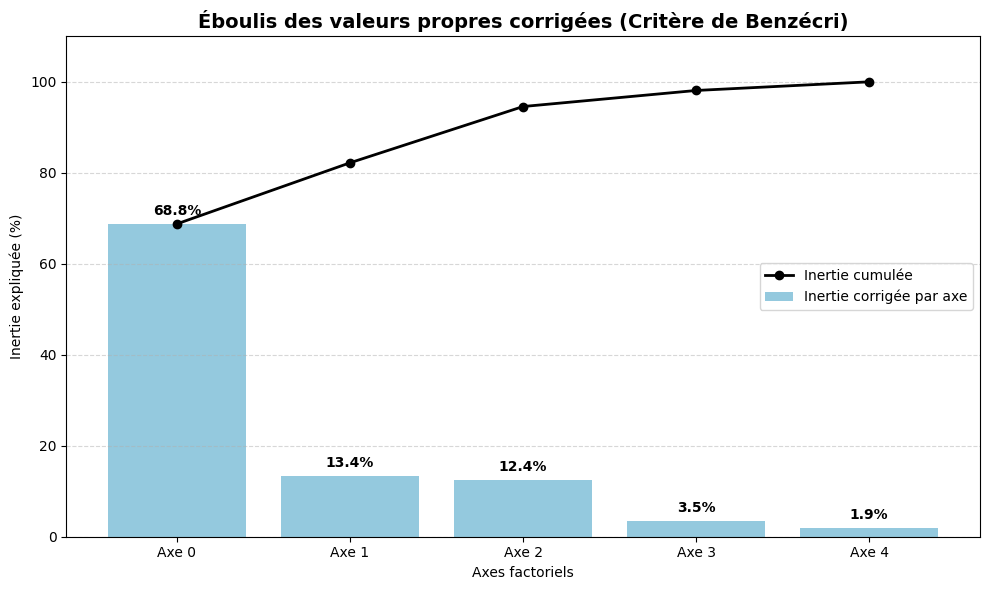

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extraction des valeurs corrigées calculées précédemment
axes_labels = summary_benzecri.index
pct_corrige = [float(val.replace('%', '')) for val in summary_benzecri['% var. corrigée']]

plt.figure(figsize=(10, 6))

# Histogramme des variances corrigées
sns.barplot(x=list(axes_labels), y=pct_corrige, color='skyblue', label='Inertie corrigée par axe')

# Courbe cumulative
cum_pct_corrige = [float(val.replace('%', '')) for val in summary_benzecri['% var. cumulée corrigée']]
plt.plot(list(axes_labels), cum_pct_corrige, color='black', marker='o', linestyle='-', linewidth=2, label='Inertie cumulée')

# Ajout des valeurs au-dessus des barres
for i, val in enumerate(pct_corrige):
    plt.text(i, val + 2, f"{val:.1f}%", ha='center', fontweight='bold')

plt.title("Éboulis des valeurs propres corrigées (Critère de Benzécri)", fontsize=14, fontweight='bold')
plt.xlabel("Axes factoriels")
plt.ylabel("Inertie expliquée (%)")
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='center right')
plt.tight_layout()
plt.show()

**Lecture** :
- Avec p = 11, le seuil est 0,0909 : les 5 axes le dépassent.
- Après correction, l'**Axe 0 porte 70 %** de l'information, l'Axe 1 14 %, l'Axe 2 10 %. Les 3 premiers axes cumulent 94 %.
- L'éboulis corrigé montre un **coude net après l'Axe 0**, puis une décroissance régulière.

Autrement dit : la structure est dominée par un **axe principal** (le cycle de vie et la valeur, cf. ACM 3), suivi de deux axes secondaires.

*Précision* : la correction a ici été calculée sur les 5 axes conservés seulement. Le total des valeurs propres corrigées est donc sous-estimé, ce qui **surestime** les pourcentages. L'ordre de grandeur et la hiérarchie des axes restent valides.

## ACM 3 : avec plusieurs variables supplémentaires

### Choix des variables actives
L'ACM 3 conserve **7 variables actives** et rend les autres **supplémentaires**. Les choix sont expliqués à l'étape 5 et résumés au § 6 :
- on garde une seule ancienneté, une seule mesure de valeur, un seul profil d'usage ;
- les variables qui ne structurent pas ou qui ont une modalité rare passent en supplémentaires.

In [58]:
SUPP = ['zone_geo_reg', 'type_abo', 'intensite_12m', 'anciennete_abo_reg']

In [59]:
ACTIVES = ['type_client', 'anciennete_client_reg', 'fidelite_reg', 'valeur_12M_reg',
           'canal_paiement', 'profil_usage', 'utilise_remote']

In [60]:
# On reconstruit d'abord df_regrouped_sampled à partir de df pour s'assurer d'avoir toutes les colonnes à jour
df_regrouped = df[df_regrouped_columns].copy()
df_regrouped_sampled = df_regrouped[df_regrouped['id_anonyme'].isin(sampled_ids)].copy()

# Sélection des variables actives pour l'ACM
cols_a_garder = ACTIVES
df_actives = df_regrouped_sampled[cols_a_garder]
display(df_actives.head())

,type_client,anciennete_client_reg,fidelite_reg,valeur_12M_reg,canal_paiement,profil_usage,utilise_remote
0,nouveau,<6m,vient_de_s_abonner,<15EUR,paiement_appli,rare_courte,non
2,nouveau,<6m,vient_de_s_abonner,<15EUR,paiement_web,frequent_longue,non
6,nouveau,<6m,vient_de_s_abonner,<15EUR,paiement_appli,frequent_courte,non
7,nouveau,<6m,vient_de_s_abonner,<15EUR,paiement_web,frequent_longue,non
16,nouveau,<6m,vient_de_s_abonner,<15EUR,paiement_appli,frequent_longue,oui


**Lecture** : le jeu actif contient 7 colonnes (`type_client`, `anciennete_client_reg`, `fidelite_reg`, `valeur_12M_reg`, `canal_paiement`, `profil_usage`, `utilise_remote`), soit 24 modalités, toutes à plus de 5 %.

In [61]:
acm_3 = prince.MCA(
    n_components=5,
    n_iter=3,
    random_state=42
)

acm_3 = acm_3.fit(df_actives)

In [62]:
acm_3.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.371,14.44%,14.44%
1,0.297,11.56%,26.00%
2,0.221,8.60%,34.60%
3,0.196,7.61%,42.21%
4,0.169,6.58%,48.78%


**Lecture** : l'Axe 0 porte 14,9 % de l'inertie et l'Axe 1 11,4 %. Sur 5 axes, le cumul est de **50,0 %** : le meilleur de toutes les ACM. La décroissance est plus **progressive** que dans l'ACM 2 : plusieurs dimensions portent de l'information, au lieu d'un axe qui écrase le reste. C'est ce qu'on cherche avant une CAH.

Les valeurs propres des 5 axes (de 0,362 à 0,161) dépassent toutes le seuil 1/Q = 1/7 = 0,143 : **les 5 axes sont informatifs**.

*Nuance* : le pourcentage cumulé augmente aussi mécaniquement quand on retire des variables (7 variables au lieu de 11). La décision repose donc aussi sur la lisibilité des axes, étudiée plus loin.

✅Meilleure ACM, on la garde !

## ACM 4 : avec le type de clients en var supp

Test : on retire `type_client`, pour vérifier que l'ACM ne se résume pas à cette variable.

In [63]:
acm_sans_tclient = prince.MCA(
    n_components=5,
    n_iter=3,
    random_state=42
)
acm_sans_tclient = acm_sans_tclient.fit(df_regrouped_sampled.drop(columns=['id_anonyme','type_client']))
acm_regrouped

MCA(n_components=5, n_iter=3, random_state=42)

In [64]:
acm_sans_tclient.eigenvalues_summary

,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.337,12.98%,12.98%
1,0.211,8.10%,21.08%
2,0.190,7.31%,28.39%
3,0.158,6.07%,34.46%
4,0.147,5.66%,40.11%


**Lecture** : sans `type_client`, l'inertie cumulée tombe à **40,6 %** (13,1 % pour l'Axe 0), moins bien que l'ACM 3 et même que l'ACM 2. `type_client` structure donc le jeu de données de façon utile : on la garde en variable active.

*Note* : dans cette ACM, `type_client` est seulement retirée, pas projetée en supplémentaire (le code utilise `drop`). La dernière ligne de la cellule affiche `acm_regrouped` : c'est sans effet sur les résultats.

### Comparaison des 4 ACM

| ACM | Variables actives | Axe 0 | Cumul 5 axes | Verdict |
|---|---|---|---|---|
| 1 : brut | 13 (environ 127 modalités, beaucoup de rares) | 3,9 % | 13,0 % | Inutilisable : inertie diluée |
| 2 : regroupé, 11 variables | 11 (redondantes, dont zone et type d'abonnement) | 14,4 % | 42,0 % | Mieux, mais variables redondantes |
| 3 : 7 actives + 4 supplémentaires | 7 | **14,9 %** | **50,0 %** | **Retenue** |
| 4 : sans `type_client` | 10 | 13,1 % | 40,6 % | Moins bonne : `type_client` est utile |

## Analyse des contributions de l'ACM 3 - var actives

On analyse l'**ACM 3** : les coordonnées des individus et des modalités, les contributions (qui construit chaque axe) et les cos² (qualité de représentation).

In [65]:
acm_3.row_coordinates(df_actives).head()

,0,1,2,3,4
0,-0.719559,1.738152,-0.226319,-0.524319,0.537890
2,-0.678522,1.737112,-0.263452,0.348473,1.051388
6,-0.757081,1.794557,-0.399485,-0.293083,0.725274
7,-0.678522,1.737112,-0.263452,0.348473,1.051388
16,-0.777241,1.792800,-0.068799,0.594369,0.834500


**Coordonnées des individus** : chaque ligne est un client, chaque colonne un axe. Ce sont ces 5 coordonnées qui alimenteront la CAH. Les individus qui ont le même profil ont des coordonnées identiques (ici les lignes 2 et 7).

In [66]:
acm_3.column_coordinates(df_actives).head()

,0,1,2,3,4
type_client__churn,-0.669050,-0.510913,-0.139324,-0.059827,0.028611
type_client__nouveau,-0.246303,1.970251,0.375565,-0.194137,-0.308692
type_client__reactivated,0.449775,-0.408320,1.169693,0.316973,0.327726
type_client__retained,1.628596,-0.000274,-0.825548,0.082199,-0.062516
anciennete_client_reg__1-3ans,0.479659,-0.437414,-0.044213,-0.205018,0.257266


**Coordonnées des modalités** : plus une coordonnée est grande en valeur absolue, plus la modalité caractérise cet axe. Le signe indique le côté de l'axe (par exemple `type_client__churn` est négatif sur l'Axe 0, `retained` positif).

In [67]:
acm_3.row_cosine_similarities(df_actives).head()

,0,1,2,3,4
0,0.085470,0.498722,0.008455,0.045381,0.047761
2,0.073460,0.481480,0.011075,0.019376,0.176380
6,0.096191,0.540463,0.026783,0.014416,0.088279
7,0.073460,0.481480,0.011075,0.019376,0.176380
16,0.090691,0.482519,0.000711,0.053035,0.104545


**Cos² des individus** : part de la distance d'un client à l'origine qui est représentée par chaque axe. Les clients de cet extrait sont bien représentés par l'Axe 1 (cos² de 0,5 à 0,7) : ce sont des nouveaux.

In [68]:
# Coordonnées des modalités sur les axes
print(acm_3.column_coordinates(df_actives).head(10))

                                        0         1         2         3  \
type_client__churn              -0.669050 -0.510913 -0.139324 -0.059827   
type_client__nouveau            -0.246303  1.970251  0.375565 -0.194137   
type_client__reactivated         0.449775 -0.408320  1.169693  0.316973   
type_client__retained            1.628596 -0.000274 -0.825548  0.082199   
anciennete_client_reg__1-3ans    0.479659 -0.437414 -0.044213 -0.205018   
anciennete_client_reg__6-12m    -0.586384 -0.224898  0.127576  0.117714   
anciennete_client_reg__<6m      -0.656921  1.422197  0.006667 -0.122079   
anciennete_client_reg__>3ans     0.757981 -0.410275 -0.122214  0.258674   
fidelite_reg__1_faible(<50%)    -0.773397 -0.594422 -0.386566  0.294306   
fidelite_reg__2_moyenne(50-90%)  0.206307 -0.560865  1.012764 -0.501819   

                                        4  
type_client__churn               0.028611  
type_client__nouveau            -0.308692  
type_client__reactivated         0.327726 

Affichage des contributions et cos ²

In [69]:
# Affichage des contributions
print("Contributions")
display(acm_3.column_contributions_.style.format('{:.0%}'))
# Affichage des cos²
print("Cosinus carrés")
display(acm_3.column_cosine_similarities(df_actives))

Contributions


,0,1,2,3,4
type_client__churn,9%,6%,1%,0%,0%
type_client__nouveau,0%,30%,1%,0%,1%
type_client__reactivated,1%,1%,13%,1%,1%
type_client__retained,20%,0%,8%,0%,0%
anciennete_client_reg__1-3ans,3%,3%,0%,1%,2%
anciennete_client_reg__6-12m,4%,1%,0%,0%,25%
anciennete_client_reg__<6m,3%,19%,0%,0%,5%
anciennete_client_reg__>3ans,5%,2%,0%,1%,4%
fidelite_reg__1_faible(<50%),9%,7%,4%,2%,1%
fidelite_reg__2_moyenne(50-90%),0%,3%,14%,4%,13%


Cosinus carrés


,0,1,2,3,4
type_client__churn,0.454957,2.653061e-01,0.019729,0.003638,0.000832
type_client__nouveau,0.011601,7.423225e-01,0.026972,0.007207,0.018222
type_client__reactivated,0.033965,2.799261e-02,0.229713,0.016869,0.018033
type_client__retained,0.628835,1.783248e-08,0.161583,0.001602,0.000927
anciennete_client_reg__1-3ans,0.101439,8.435779e-02,0.000862,0.018532,0.029181
anciennete_client_reg__6-12m,0.141163,2.076488e-02,0.006682,0.005689,0.409825
anciennete_client_reg__<6m,0.107199,5.024408e-01,0.000011,0.003702,0.076813
anciennete_client_reg__>3ans,0.147223,4.313295e-02,0.003827,0.017146,0.063361
fidelite_reg__1_faible(<50%),0.379552,2.242105e-01,0.094823,0.054962,0.021957
fidelite_reg__2_moyenne(50-90%),0.011622,8.589521e-02,0.280071,0.068762,0.189927


### Lecture des contributions et cos²
**Contributions** (part de l'axe construite par chaque modalité) :

| Axe | Principales modalités contributrices | Dimension |
|---|---|---|
| **0** | `valeur > 60 €` (21 %), `retained` (20 %), `fidélité faible` (12 %), `churn` (11 %), `valeur < 15 €` (11 %), `fidélité forte` (9 %) | **Valeur et fidélité** : clients qui restent et rapportent vs clients qui partent |
| **1** | `nouveau` (34 %), `ancienneté < 6 mois` (23 %), `fidélité forte` (13 %) | **Arrivée dans la base** : onboarding |
| **2** | `valeur 30-60 €` (25 %), `fidélité moyenne` (16 %), `reactivated` (14 %), `valeur < 15 €` (9 %) | **Parcours discontinu** : clients réactivés, valeur intermédiaire |
| **3** | `remote oui` (23 %), `fréquent-long` (20 %), `dormant` (11 %), `rare-court` (9 %), `remote non` (8 %), canal (5 % + 5 %) | **Usage** et canal : utilisateurs avancés vs peu actifs |
| **4** | `dormant` (18 %), `valeur 15-30 €` (16 %), `ancienneté 6-12 m` (12 %), `fréquent-court` (9 %) | **Usage régulier vs dormant** parmi les clients à valeur faible |

Les **cos²** confirment : `churn` (0,58) et `retained` (0,62) sont bien représentés sur l'Axe 0 ; `nouveau` (0,78) et `< 6 mois` (0,55) sur l'Axe 1 ; `reactivated` (0,25) et `valeur 30-60 €` (0,46) sur l'Axe 2 ; `remote` (0,42) et `fréquent-long` (0,33) sur l'Axe 3.

**Point important** : les variables d'**usage** et de **canal** n'apparaissent qu'à partir de l'**Axe 3**. Elles seront donc absentes du premier plan factoriel, mais elles sont bien présentes dans les 5 axes qui alimentent la CAH.

**Équilibre** : aucune modalité n'écrase un axe (le maximum est 34 % pour `nouveau` sur l'Axe 1, ce qui est normal pour un axe d'« arrivée »). Chaque dimension du projet a son axe : valeur/fidélité (0), arrivée (1), parcours (2), usage (3-4).

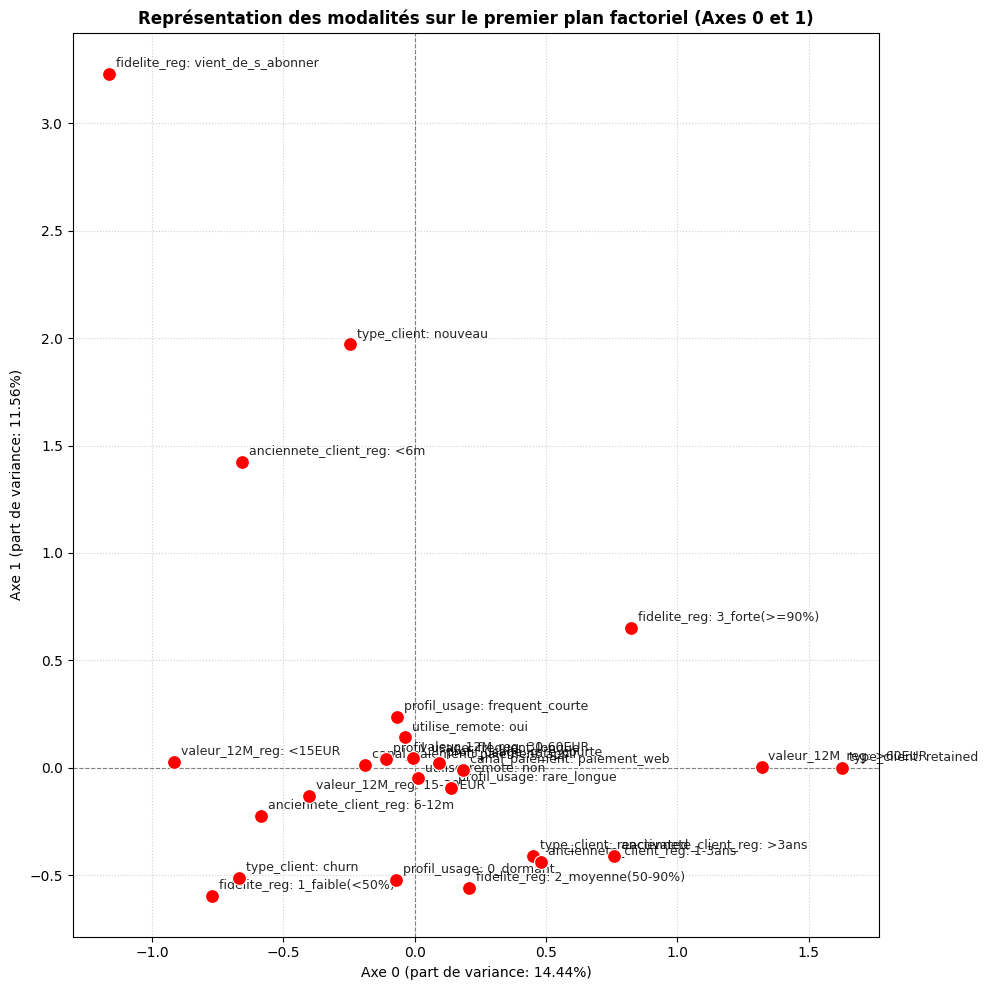

In [70]:
# Récupération des coordonnées des modalités pour les deux premiers axes (0 et 1)
coords = acm_3.column_coordinates(df_actives)

# Création du graphique
plt.figure(figsize=(10, 10))
sns.scatterplot(
    x=coords[0],
    y=coords[1],
    color='red',
    s=100,
    zorder=5
)

# Ajout des étiquettes des modalités avec un léger décalage
for i, txt in enumerate(coords.index):
    plt.annotate(
        txt.replace('__', ': '),
        (coords[0].iloc[i], coords[1].iloc[i]),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=9,
        alpha=0.85
    )

# Personnalisation des axes et du style
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title("Représentation des modalités sur le premier plan factoriel (Axes 0 et 1)", fontsize=12, fontweight='bold')
plt.xlabel(f"Axe 0 (part de variance: {acm_3.eigenvalues_summary.loc[0, '% of variance']})")
plt.ylabel(f"Axe 1 (part de variance: {acm_3.eigenvalues_summary.loc[1, '% of variance']})")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

📊 Analyse du plan factoriel des variables actives (Axes 0 et 1)

Ce graphique représente la cartographie de vos variables actives sur le premier plan factoriel, qui cumule **26,27 %** de l'inertie totale (14,89 % pour l'Axe 0 et 11,38 % pour l'Axe 1).   

Voici la lecture détaillée des grands axes structurants du portefeuille clients :
- 1. Axe 0 (Horizontal) : L'Axe de la Valeur et de la Fidélité

Pôle droit (Le cœur de cible stable et rentable) : On y retrouve de manière très isolée et cohérente les modalités type_client: retained, valeur_12M_reg: >60EUR et fidelite_reg: 3_forte(>=90%).   
Cet axe sépare nettement les clients les plus engagés et générateurs de revenus pour l'entreprise.

Pôle gauche (Les clients à faible valeur / Churn) :À l'opposé, le côté gauche regroupe les clients en rupture (type_client: churn), associés à une faible valeur monétaire (valeur_12M_reg: <15EUR) et à une fidélité minimale (fidelite_reg: 1_faible).   

- 2. Axe 1 (Vertical) : L'Axe du Cycle de Vie (Nouveauté vs Ancienneté)
Pôle haut (L'acquisition et l'entrée dans la base) :Le haut du graphique est dominé par la modalité type_client: nouveau, directement corrélée à une faible ancienneté client (anciennete_client_reg: <6m).
C'est l'axe de l'onboarding et des nouveaux inscrits.   Pôle bas (La maturité et la réactivation)

Pole bas rassemble les clients installés de longue date (anciennete_client_reg: >3ans), les clients reactivated, ainsi que les fidélités intermédiaires (2_moyenne).   

- 3. Le Centre du Graphique (Zone neutre)Les modalités situées au cœur du repère (proches de 0,0) — comme certains modes de paiement ou profils d'usage intermédiaires — correspondent aux comportements standards ou partagés par la majorité de la base, qui ne créent pas de différenciation forte à eux seuls.  

### Compléments de lecture
- **Forme du nuage** : le plan est structuré par trois modalités de `type_client` très éloignées de l'origine : `retained` (à droite), `churn` (à gauche) et `nouveau` (en haut). Chacune est entourée de modalités cohérentes (valeur, fidélité, ancienneté). Ces trois pôles sont des groupes importants (16 à 50 % de la base) : aucune modalité rare n'isole un axe, ce qui valide les regroupements.
- **Les profils d'usage et le canal** sont regroupés près de l'origine : ils ne sont pas discriminants sur ce plan (conforme aux contributions ci-dessus : ils agissent sur l'Axe 3).
- **`reactivated`** se situe entre `retained` et `churn`, du côté des fidélités moyennes : ce sont des clients à parcours discontinu, ni complètement perdus, ni fidèles.
- **`dormant`** est en bas, à proximité de `fidélité moyenne` et de `reactivated` : cela suggère que l'absence d'usage va de pair avec un parcours irrégulier.

,eigenvalue
component,
0,0.371
1,0.297
2,0.221
3,0.196
4,0.169


/tmp/ipykernel_600/3514946176.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Component', y='Eigenvalue', data=eigen_df, palette='viridis')


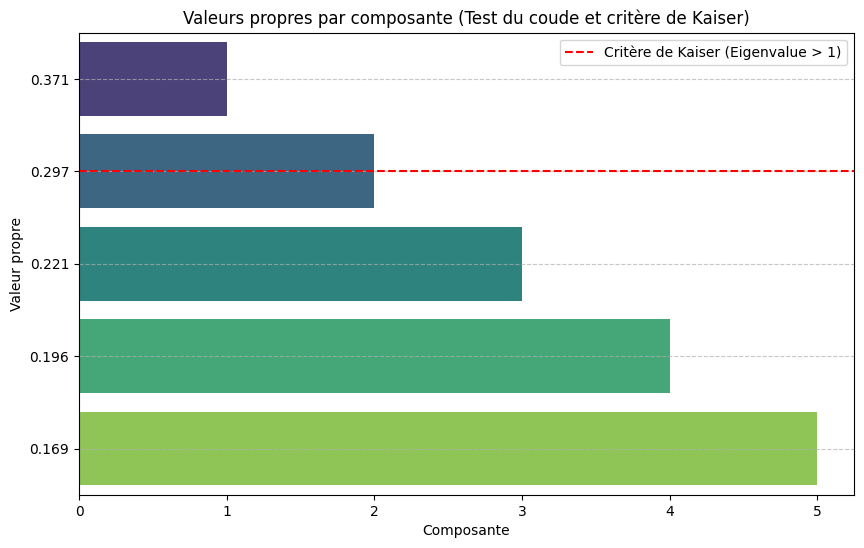

In [71]:
# Récupérer les valeurs propres
valeurs_propres = acm_3.eigenvalues_summary['eigenvalue']
display(valeurs_propres)

# Créer un DataFrame pour le plotting
eigen_df = pd.DataFrame({
    'Component': range(1, len(valeurs_propres) + 1),
    'Eigenvalue': valeurs_propres
})

plt.figure(figsize=(10, 6))
sns.barplot(x='Component', y='Eigenvalue', data=eigen_df, palette='viridis')

# Ajouter une ligne pour le critère de Kaiser (eigenvalue > 1, si applicable)
plt.axhline(y=1, color='r', linestyle='--', label='Critère de Kaiser (Eigenvalue > 1)')

plt.title('Valeurs propres par composante (Test du coude et critère de Kaiser)')
plt.xlabel('Composante')
plt.ylabel('Valeur propre')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

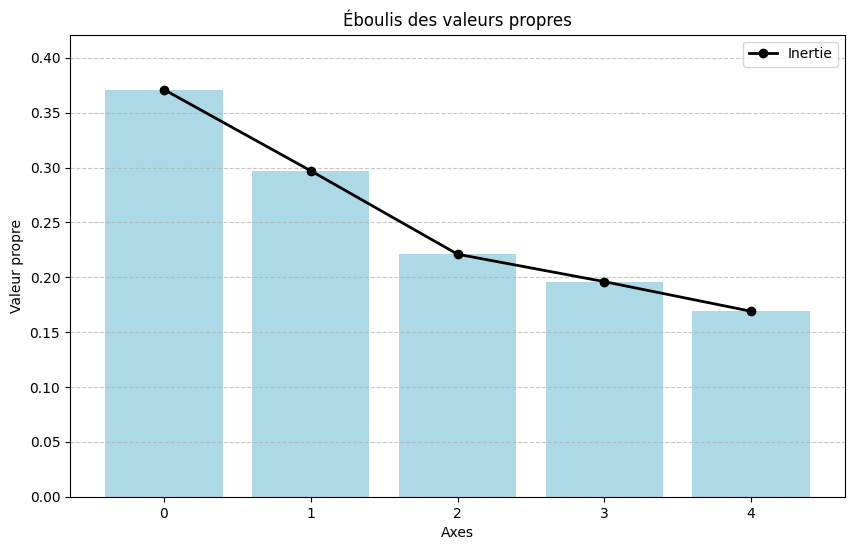

In [72]:
plt.figure(figsize=(10, 6))

# 1. Préparation des données pour la courbe (adaptée dynamiquement à la taille réelle)
n_comp = len(valeurs_propres)
x_values = range(0, n_comp)
y_values = [float(valeurs_propres[i]) for i in x_values]

# 2. Tracé de l'histogramme (les barres)
for component in x_values:
    plt.bar(x=component, height=y_values[component], color="lightblue")

# 3. AJOUT DE LA COURBE
# marker='o' place un point au milieu du sommet de chaque barre
plt.plot(x_values, y_values, color='black', marker='o', linestyle='-', linewidth=2, label='Inertie')

# 4. Habillage habituel
plt.title('Éboulis des valeurs propres')
plt.xlabel('Axes')
plt.ylabel('Valeur propre')
plt.xticks(x_values)
plt.ylim([0, max(y_values) + 0.05]) # Dynamise la hauteur maximale de l'axe Y
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()

plt.show()

### Lecture de l'éboulis des valeurs propres
- Les valeurs propres décroissent régulièrement de 0,362 à 0,161 : **pas de coude brutal**. L'information est répartie sur plusieurs axes, ce qui est favorable (le 1er axe n'écrase pas les autres).
- **La ligne rouge de la 1re figure (critère de Kaiser, valeur propre > 1) ne s'applique pas à l'ACM** : les valeurs propres d'une ACM sont inférieures à 1. Le seuil pertinent est **1/Q = 0,143**. Les 5 axes le dépassent : les 5 sont conservés.

## Analyse ACM 3 - var inactives

On analyse que les modalités avec des contrib supérieures à la contribution moyenne sinon pas significatif

Possible d'avoir qu'une modalité par variable qui contribue bien

### Principe
Les variables supplémentaires ne participent pas au calcul des axes. On les **projette** sur les axes existants : la coordonnée d'une modalité est le barycentre des individus qui la possèdent. Lire :
- une modalité **proche d'une modalité active** va avec elle ;
- une modalité **proche de l'origine** n'est pas liée aux axes (elle ne distingue pas les groupes).

In [73]:
# Correction du nom de la colonne d'ancienneté d'abonnement dans SUPP
# Le nom de la colonne dans le DataFrame est 'anciennete_abo_reg'
SUPP = [col if col != 'anciennete_abonnement_reg' else 'anciennete_abo_reg' for col in SUPP]
if 'anciennete_abo_reg' not in SUPP and 'anciennete_abonnement_reg' in SUPP:
    SUPP = [col if col != 'anciennete_abonnement_reg' else 'anciennete_abo_reg' for col in SUPP]

df_supp = df_regrouped_sampled[SUPP]
display(df_supp.head())

,zone_geo_reg,type_abo,intensite_12m,anciennete_abo_reg
0,Amerique_Nord,plein_tarif,1_ponctuel(1m),0-3m
2,Europe_hors_FR,plein_tarif,1_ponctuel(1m),0-3m
6,Amerique_Nord,plein_tarif,1_ponctuel(1m),0-3m
7,Europe_hors_FR,plein_tarif,1_ponctuel(1m),0-3m
16,Amerique_Nord,plein_tarif,1_ponctuel(1m),0-3m


In [74]:
df_total = df_regrouped_sampled[ACTIVES + SUPP]
all_coords = acm_3.column_coordinates(df_total)

In [75]:
supp_coords_filtered = all_coords[all_coords.index.str.startswith(tuple(SUPP))]

In [76]:
print("Coordonnées des modalités supplémentaires :")
display(supp_coords_filtered.head())

Coordonnées des modalités supplémentaires :


,0,1,2,3,4
anciennete_abo_reg__0-3m,-0.354224,0.676988,0.339141,0.135348,0.498446
anciennete_abo_reg__1-2ans,0.953641,-0.317894,-0.433581,-0.382886,0.289938
anciennete_abo_reg__4-6m,-0.514296,-0.123765,0.187814,-0.008965,-0.268427
anciennete_abo_reg__7-12m,-0.331927,-0.340877,0.014676,0.085782,-0.512816
anciennete_abo_reg__>2ans,1.400371,-0.119986,-0.637584,-0.020779,0.226748


**Lecture** : les coordonnées sont celles des 4 variables supplémentaires sur les 5 axes. La cellule n'affiche que les 5 premières lignes (`head`), d'où uniquement `anciennete_abo_reg` : l'ensemble est tracé sur le graphique suivant.

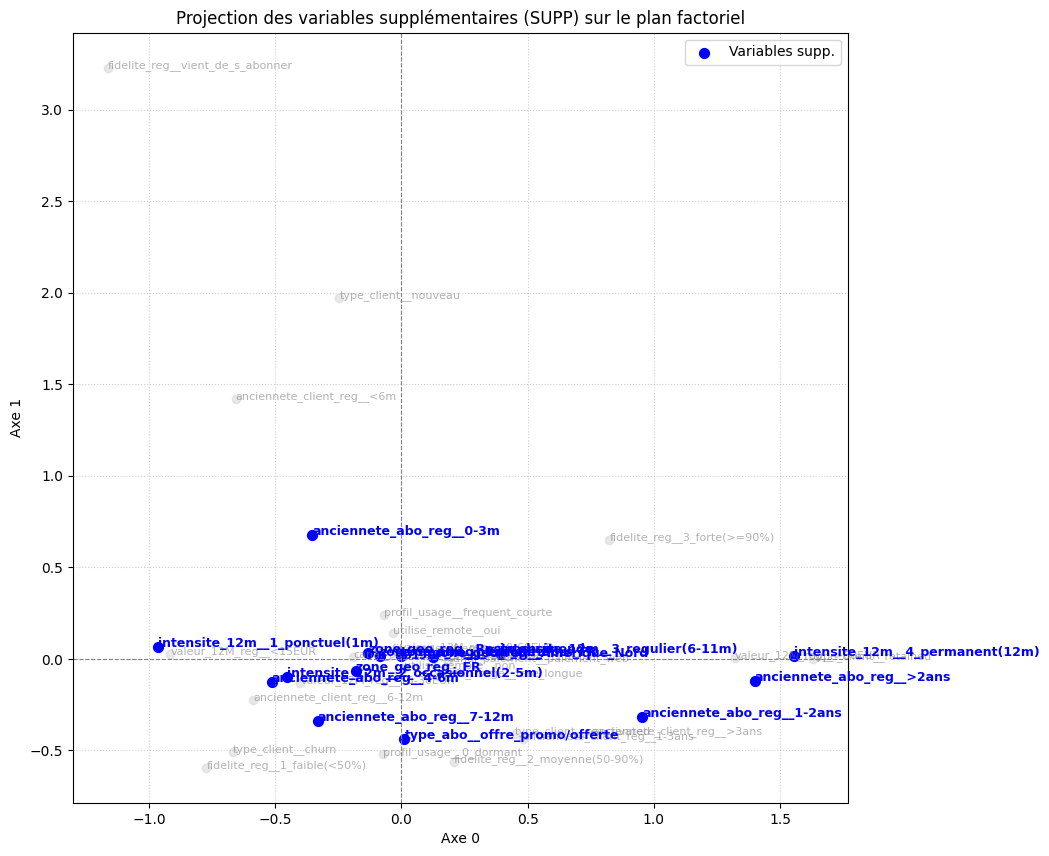

In [77]:
fig, ax = plt.subplots(figsize=(10, 10))
active_coords = acm_3.column_coordinates(df_actives)
ax.scatter(active_coords[0], active_coords[1], color='lightgray', alpha=0.5)
for idx, row in active_coords.iterrows():
    ax.text(row[0], row[1], idx, fontsize=8, color='gray', alpha=0.6)

# Tracer les variables supplémentaires en couleur (ex: en bleu)
ax.scatter(supp_coords_filtered[0], supp_coords_filtered[1], color='blue', s=50, label='Variables supp.')
for idx, row in supp_coords_filtered.iterrows():
    ax.text(row[0], row[1], idx, fontsize=9, color='blue', fontweight='bold')

ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
ax.axvline(0, color='grey', linestyle='--', linewidth=0.8)
ax.set_xlabel("Axe 0")
ax.set_ylabel("Axe 1")
ax.set_title("Projection des variables supplémentaires (SUPP) sur le plan factoriel")
ax.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

📊 Analyse de la projection des variables supplémentaires
1. Axe 0 (Horizontal) : L'Axe de la Valeur et de l'Engagement
Côté droit (Clients fidèles et à haute valeur) :

On y retrouve les abonnements de longue durée (anciennete_abo_reg__>2ans et 1-2ans).

L'intensité maximale d'utilisation (intensite_12m__4_permanent(12m)).

Ces modalités se superposent parfaitement avec les clients fidèles et à forte valeur (type_client: retained).

Côté gauche (Clients à faible engagement / Risque de Churn) :

On y retrouve l'intensité minimale (intensite_12m__1_ponctuel(1m)).

Ces points se calent naturellement aux côtés des clients en churn ou à faible valeur.

2. Axe 1 (Vertical) : L'Axe du Cycle de Vie et de l'Ancienneté
En haut : Regroupe les abonnements très récents (anciennete_abo_reg__0-3m), proches des nouveaux clients.

En bas : Rassemble les abonnements intermédiaires (7-12m) et les offres promotionnelles (offre_promo/offerte), qui glissent vers les clients réactivés.

3. Effet des autres variables (zone_geo_reg, etc.)
Les zones géographiques (FR, Europe_hors_FR, Amerique_Nord, Reste_du_monde) se situent près du centre (0,0), ce qui indique qu'elles se répartissent de manière homogène et ne créent pas de rupture majeure sur ce premier plan factoriel.

### Complément d'interprétation
- **`intensite_12m`** : c'est la supplémentaire la plus nette. Elle s'étale sur tout l'Axe 0 (de `1_ponctuel` à gauche, jusqu'à `4_permanent` à droite) : elle **confirme** que l'Axe 0 mesure la régularité de l'abonnement, donc la valeur. Elle justifie d'avoir gardé `valeur_12M` plutôt que `nb_abo_periode` comme variable active (la valeur est le reflet de l'intensité).
- **`anciennete_abo_reg`** : `0-3m` est en haut (Axe 1, nouveaux), `>2ans` et `1-2ans` à droite (Axe 0, clients installés). Elle suit l'ancienneté client : c'est ce qui justifie de ne pas la garder en active.
- **`type_abo` (offre promotionnelle)** : proche de l'origine sur l'Axe 0, plutôt vers le bas (Axe 1) : les clients venus par offre ne forment pas un groupe distinct, mais tendent vers les parcours discontinus (réactivés).
- **`zone_geo_reg`** : au centre, aucune zone n'est associée à un profil de comportement. Le choix de la placer en supplémentaire est confirmé : elle ne fait pas de segment à elle seule. Elle servira à adapter la **langue** de la communication dans chaque groupe.

## Modalités à garder


- Nb de modalités actives : 24
- Contribution moyennne = 1/24 dc **4,17%** ou par variable 1/Q (nb de variable actives) dc **14,29%**

In [78]:
# 1. Récupération de la matrice des contributions des modalités (en %) pour les 5 axes
contrib_df = acm_3.column_contributions_

# 2. Calcul du seuil moyen théorique (1 / nombre total de modalités actives)
num_modalities = len(contrib_df)
seuil_moyen = 1.0 / num_modalities
print(f"Nombre de modalités actives : {num_modalities}")
print(f"Seuil de contribution moyenne par modalité : {seuil_moyen:.2%}\n")

# 3. Identification des modalités significatives pour chaque axe
modalites_significatives = {}
for col in contrib_df.columns:
    significatives = contrib_df[contrib_df[col] > seuil_moyen][col].sort_values(ascending=False)
    modalites_significatives[col] = significatives
    print(f"--- Axe {col} : {len(significatives)} modalités supérieures à la moyenne ---")
    for mod, val in significatives.items():
        print(f"  * {mod:<50} : {val:.2%}")
    print()

Nombre de modalités actives : 25
Seuil de contribution moyenne par modalité : 4.00%

--- Axe 0 : 7 modalités supérieures à la moyenne ---
  * valeur_12M_reg__>60EUR                             : 20.54%
  * type_client__retained                              : 19.56%
  * valeur_12M_reg__<15EUR                             : 12.14%
  * fidelite_reg__3_forte(>=90%)                       : 9.43%
  * fidelite_reg__1_faible(<50%)                       : 8.94%
  * type_client__churn                                 : 8.68%
  * anciennete_client_reg__>3ans                       : 4.51%

--- Axe 1 : 6 modalités supérieures à la moyenne ---
  * type_client__nouveau                               : 29.94%
  * anciennete_client_reg__<6m                         : 19.34%
  * fidelite_reg__vient_de_s_abonner                   : 17.95%
  * fidelite_reg__3_forte(>=90%)                       : 7.36%
  * fidelite_reg__1_faible(<50%)                       : 6.59%
  * type_client__churn                        

### Bilan de l'ACM 3
- **5 axes retenus** (valeurs propres supérieures à 1/Q ; inertie cumulée de 50 %).
- **Axes interprétables** : 0 = valeur et fidélité · 1 = arrivée (nouveaux) · 2 = parcours discontinu (réactivés) · 3-4 = usage.
- **Les regroupements ont fonctionné** : plus de modalité isolée captant un axe, et inertie nettement mieux répartie qu'avec les variables brutes (13 % → 50 %).
- Les coordonnées des individus sur ces 5 axes sont l'entrée de la CAH.

# 8. CAH (Classification Ascendante Hiérarchique)

### Principe
La CAH regroupe progressivement les individus les plus proches (ici sur les 5 axes de l'ACM 3) jusqu'à n'en faire qu'un groupe. Le **critère de Ward** fusionne à chaque étape les deux groupes dont le regroupement fait le moins augmenter l'inertie intra-classe : il donne des groupes compacts et bien séparés. Le **dendrogramme** représente l'ordre des fusions ; la hauteur d'une fusion indique la perte d'homogénéité.

### Choix des coordonnées de l'ACM
On travaille sur les coordonnées factorielles et non sur les modalités : elles sont numériques, débarrassées du bruit des derniers axes, et résument bien les 7 variables.

In [79]:
# 1. Extraction des coordonnées des individus sur les 5 axes de l'ACM 3
coordonnees_individus = acm_3.row_coordinates(df_actives)
print("Dimensions des coordonnées pour la CAH :", coordonnees_individus.shape)
display(coordonnees_individus.head())

Dimensions des coordonnées pour la CAH : (68218, 5)


,0,1,2,3,4
0,-0.719559,1.738152,-0.226319,-0.524319,0.537890
2,-0.678522,1.737112,-0.263452,0.348473,1.051388
6,-0.757081,1.794557,-0.399485,-0.293083,0.725274
7,-0.678522,1.737112,-0.263452,0.348473,1.051388
16,-0.777241,1.792800,-0.068799,0.594369,0.834500


**Lecture** : 68 218 individus × 5 axes. Ce tableau reprend les coordonnées de la cellule d'analyse de l'ACM 3.

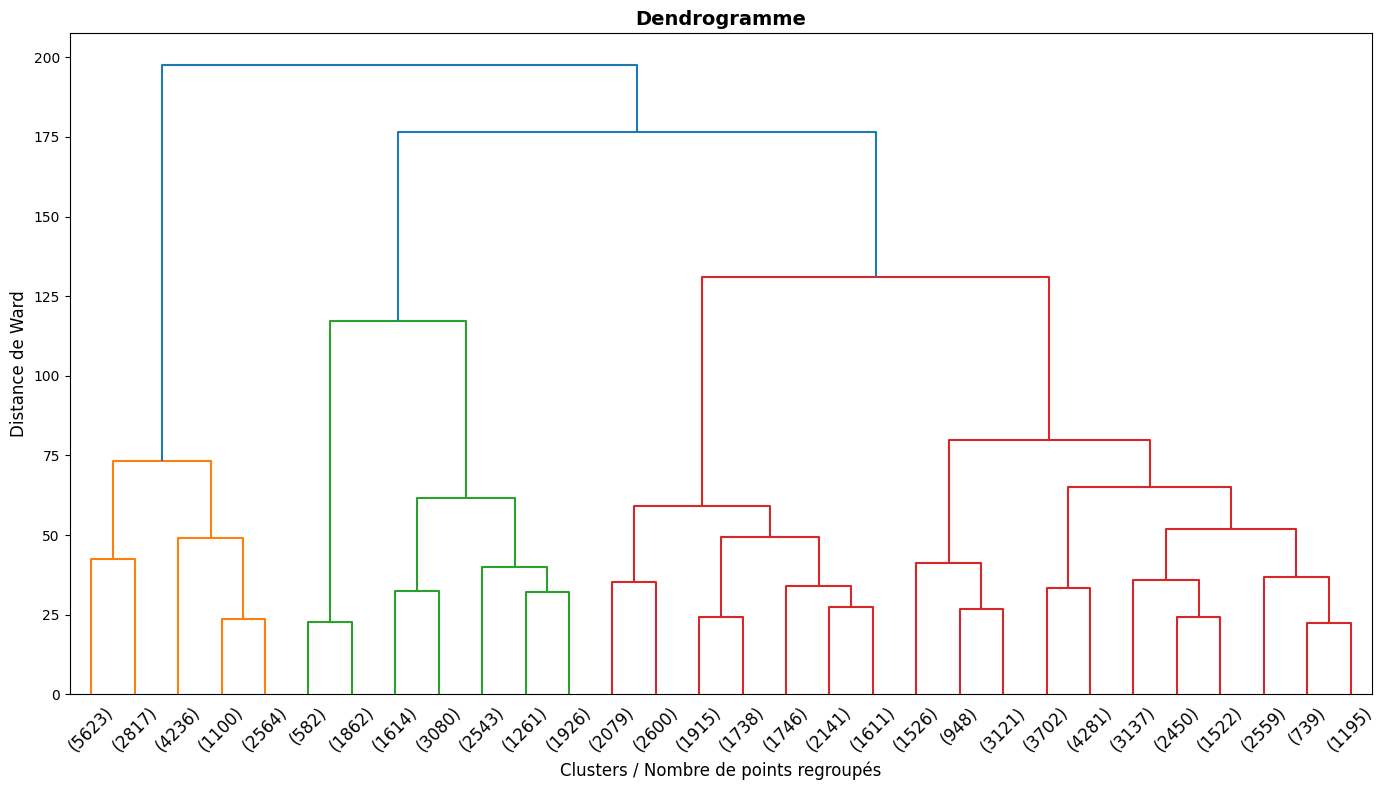

=== Répartition des individus par classe (CAH) ===


,Effectif,Pourcentage (%)
Classe,,
1,16340,23.95
2,12868,18.86
3,13830,20.27
4,25180,36.91


In [80]:
X = coordonnees_individus.values  # 68 218 x 5
Z = fastcluster.linkage_vector(X, method="ward")

# 1. Élargir la figure pour laisser de la place
plt.figure(figsize=(14, 8))

# 2. Augmenter 'p' (ex: p=50 ou p=100) pour afficher plus de détails
dendrogram(
    Z,
    truncate_mode="lastp",
    # p=50,
    show_leaf_counts=True,
    leaf_rotation=45,  # Incline les étiquettes
    leaf_font_size=12,  # Réduit la police pour qu'elles rentrent bien

)

plt.title("Dendrogramme", fontsize=14, fontweight="bold")
plt.xlabel("Clusters / Nombre de points regroupés", fontsize=12)
plt.ylabel("Distance de Ward", fontsize=12)
plt.tight_layout()
plt.show()

# Récupération des classes (en fixant 4 classes comme validé précédemment)
labels = fcluster(Z, t=4, criterion="maxclust")
# 4. Calcul et affichage de la répartition des individus par classe
df_distribution = pd.DataFrame({'Classe': labels})
repartition = df_distribution['Classe'].value_counts().sort_index().to_frame(name='Effectif')
repartition['Pourcentage (%)'] = (repartition['Effectif'] / len(df_distribution) * 100).round(2)

print("=== Répartition des individus par classe (CAH) ===")
display(repartition)

Avec 5 classes, on a cette réparititon :

| Classe | Nb d'individus | %
|---|---|---|
| 1 | 16340 | 23,95
| 2 | 2444 | 3,58
| 3 | 10424 | 15,28
| 4 | 13830 | 20,27
| 5 | 25180 | 36,91


Parition pas équilibré la classe 2 est beaucoup trop minoritaire par rapport aux autres classes, on reste sur 4 classes

## Stats desc par groupe - sur l'echantillon de base

In [81]:
# 1. Découpage final en 4 groupes
labels_4 = fcluster(Z, t=4, criterion='maxclust')

# 2. Intégration des étiquettes de groupes dans le dataset échantillonné
df_regrouped_sampled['Groupe'] = labels_4

# 3. Répartition globale des 4 groupes
print("=== Répartition finale des individus sur 4 classes ===")
rep_4 = df_regrouped_sampled['Groupe'].value_counts().sort_index().to_frame(name='Effectif')
rep_4['Pourcentage (%)'] = (rep_4['Effectif'] / len(df_regrouped_sampled) * 100).round(2)
display(rep_4)

# 4. Profilage avec les variables actives clés
print("\n=== Profilage des Groupes par rapport au Cycle de Vie (type_client) ===")
display(pd.crosstab(df_regrouped_sampled['Groupe'], df_regrouped_sampled['type_client'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport à la Valeur (valeur_12M_reg) ===")
display(pd.crosstab(df_regrouped_sampled['Groupe'], df_regrouped_sampled['valeur_12M_reg'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport au Profil d'Usage ===")
display(pd.crosstab(df_regrouped_sampled['Groupe'], df_regrouped_sampled['profil_usage'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport à l'Ancienneté ===")
display(pd.crosstab(df_regrouped_sampled['Groupe'], df_regrouped_sampled['anciennete_client_reg'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport à la Zone Géographique (Variable Supp.) ===")
display(pd.crosstab(df_regrouped_sampled['Groupe'], df_regrouped_sampled['zone_geo_reg'], normalize='index').mul(100).round(1))

=== Répartition finale des individus sur 4 classes ===


,Effectif,Pourcentage (%)
Groupe,,
1,16340,23.95
2,12868,18.86
3,13830,20.27
4,25180,36.91



=== Profilage des Groupes par rapport au Cycle de Vie (type_client) ===


type_client,churn,nouveau,reactivated,retained
Groupe,,,,
1,5.2,0.0,14.8,80.0
2,5.6,85.1,9.3,0.0
3,69.4,0.0,30.6,0.0
4,92.2,0.0,7.8,0.0



=== Profilage des Groupes par rapport à la Valeur (valeur_12M_reg) ===


...

profil_usage,0_dormant,frequent_courte,frequent_longue,rare_courte,rare_longue
Groupe,,,,,
1,13.2,28.2,18.8,20.2,19.6
2,4.3,32.7,14.3,30.5,18.2
3,18.9,17.8,6.2,35.4,21.7
4,11.7,32.3,24.2,16.2,15.6



=== Profilage des Groupes par rapport à l'Ancienneté ===


anciennete_client_reg,1-3ans,6-12m,<6m,>3ans
Groupe,,,,
1,51.6,3.5,0.0,44.9
2,5.5,35.5,58.1,0.9
3,46.7,26.3,1.1,26.0
4,21.0,44.0,23.6,11.4



=== Profilage des Groupes par rapport à la Zone Géographique (Variable Supp.) ===


zone_geo_reg,Amerique_Nord,Europe_hors_FR,FR,Reste_du_monde
Groupe,,,,
1,58.2,24.9,12.7,4.2
2,51.0,28.5,15.0,5.4
3,52.9,25.4,16.5,5.3
4,41.1,31.5,21.8,5.5


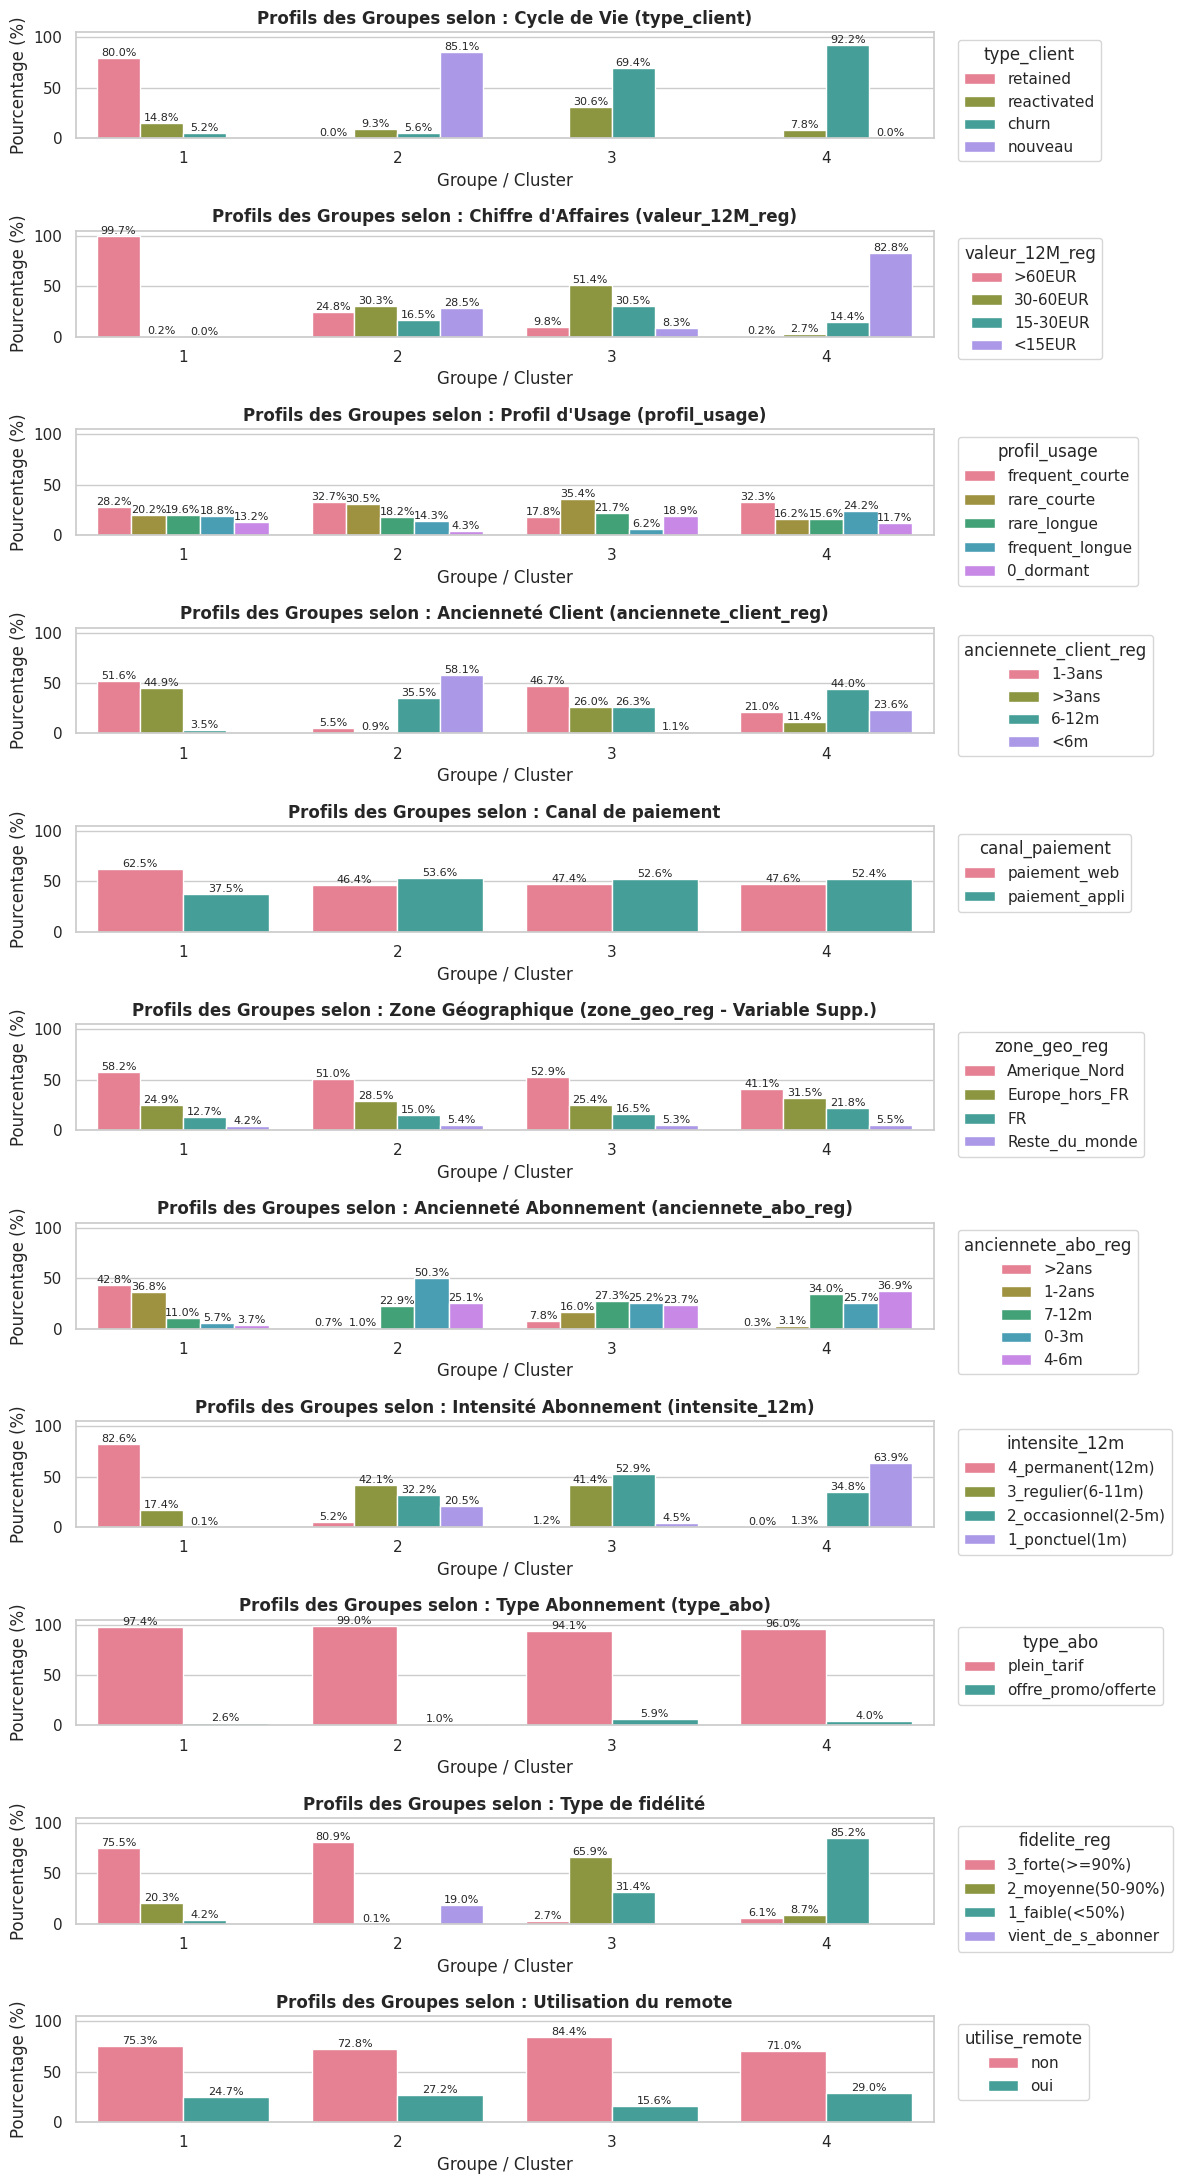

In [82]:
# Configuration globale pour de jolies figures
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 18)

# Variables d'intérêt à visualiser
variables_visualisation = [
    ('type_client', 'Cycle de Vie (type_client)'),
    ('valeur_12M_reg', "Chiffre d'Affaires (valeur_12M_reg)"),
    ('profil_usage', "Profil d'Usage (profil_usage)"),
    ('anciennete_client_reg', "Ancienneté Client (anciennete_client_reg)"),
    ('canal_paiement', "Canal de paiement"),
    ('zone_geo_reg', 'Zone Géographique (zone_geo_reg - Variable Supp.)'),
    ('anciennete_abo_reg', 'Ancienneté Abonnement (anciennete_abo_reg)'),
    ('intensite_12m', 'Intensité Abonnement (intensite_12m)'),
    ('type_abo', 'Type Abonnement (type_abo)'),
    ('fidelite_reg', 'Type de fidélité'),
    ('utilise_remote','Utilisation du remote')
]

# Création d'une grille de subplots
fig, axes = plt.subplots(nrows=len(variables_visualisation), ncols=1, figsize=(12, 22))

for i, (var, titre) in enumerate(variables_visualisation):
    # Calcul des pourcentages par Groupe (somme par ligne = 100%)
    df_plot = (
        df_regrouped_sampled.groupby('Groupe')[var]
        .value_counts(normalize=True)
        .mul(100)
        .rename('Pourcentage')
        .reset_index()
    )

    # Tracé du barplot
    sns.barplot(
        data=df_plot,
        x='Groupe',
        y='Pourcentage',
        hue=var,
        ax=axes[i],
        palette='husl'
    )

    # Configuration esthétique
    axes[i].set_title(f"Profils des Groupes selon : {titre}", fontsize=12, fontweight='bold')
    axes[i].set_ylabel("Pourcentage (%)")
    axes[i].set_xlabel("Groupe / Cluster")
    axes[i].set_ylim(0, 105)
    axes[i].legend(title=var, bbox_to_anchor=(1.02, 1), loc='upper left')

    # Ajout des étiquettes de pourcentage sur les barres
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.1f%%', label_type='edge', fontsize=8)

plt.tight_layout()
plt.show()

In [83]:
# Résumé statistique textuel complet
for g in sorted(df_regrouped_sampled['Groupe'].unique()):
    print(f"\n" + "="*60)
    print(f"   DESCRIPTION DU GROUPE {g} (Effectif : {rep_4.loc[g, 'Effectif']} individus - {rep_4.loc[g, 'Pourcentage (%)']}%)")
    print("="*60)

    df_sub = df_regrouped_sampled[df_regrouped_sampled['Groupe'] == g]

    for var in ['anciennete_client_reg', 'anciennete_abo_reg', 'type_client', 'type_abo', 'fidelite_reg','canal_paiement','intensite_12m','valeur_12M_reg','profil_usage','utilise_remote','zone_geo_reg']:
        dist = df_sub[var].value_counts(normalize=True).mul(100).round(1)
        print(f"\n* {var.upper()} (Top modalités) :")
        for modalite, pct in dist.items():
            print(f"  - {modalite:<35} : {pct}%")


   DESCRIPTION DU GROUPE 1 (Effectif : 16340 individus - 23.95%)

* ANCIENNETE_CLIENT_REG (Top modalités) :
  - 1-3ans                              : 51.6%
  - >3ans                               : 44.9%
  - 6-12m                               : 3.5%

* ANCIENNETE_ABO_REG (Top modalités) :
  - >2ans                               : 42.8%
  - 1-2ans                              : 36.8%
  - 7-12m                               : 11.0%
  - 0-3m                                : 5.7%
  - 4-6m                                : 3.7%

* TYPE_CLIENT (Top modalités) :
  - retained                            : 80.0%
  - reactivated                         : 14.8%
  - churn                               : 5.2%

* TYPE_ABO (Top modalités) :
  - plein_tarif                         : 97.4%
  - offre_promo/offerte                 : 2.6%

* FIDELITE_REG (Top modalités) :
  - 3_forte(>=90%)                      : 75.5%
  - 2_moyenne(50-90%)                   : 20.3%
  - 1_faible(<50%)                     

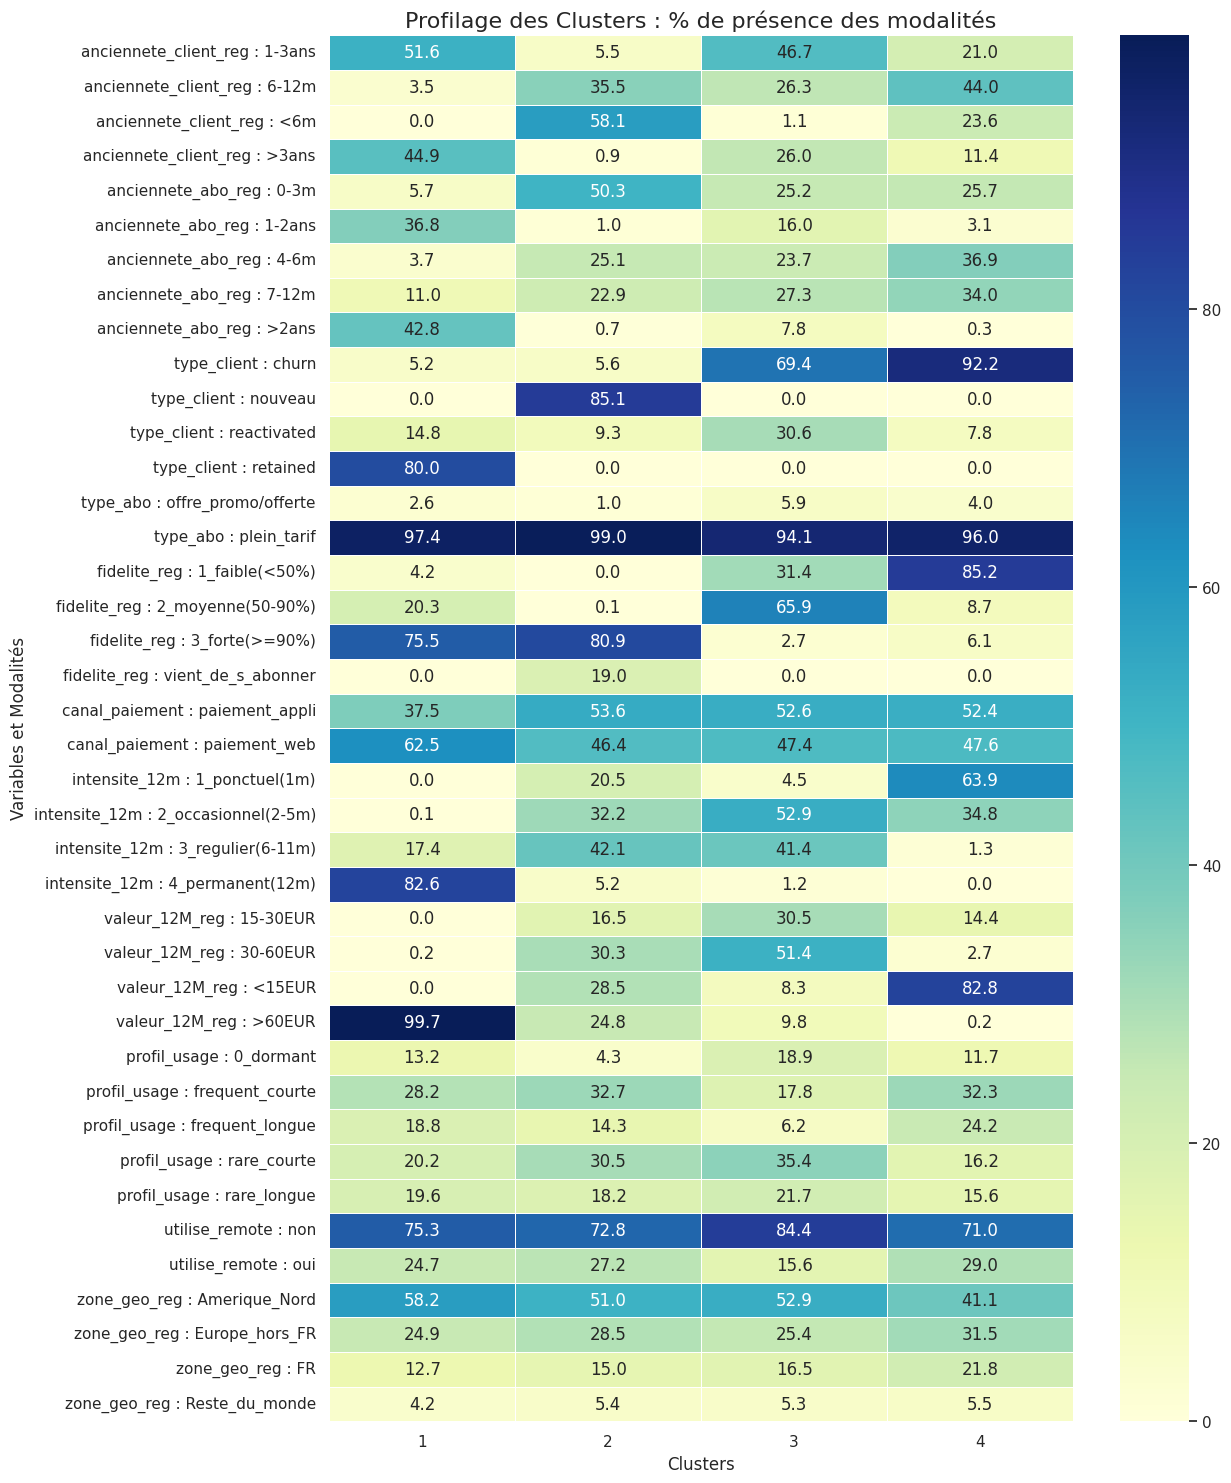

In [84]:
# 1. Chargement et préparation
cols_to_analyze= ['anciennete_client_reg', 'anciennete_abo_reg', 'type_client', 'type_abo', 'fidelite_reg','canal_paiement','intensite_12m','valeur_12M_reg','profil_usage','utilise_remote','zone_geo_reg']
# 2. Calcul des pourcentages par cluster
# On crée un grand tableau où chaque ligne est une modalité
all_stats = []
for col in cols_to_analyze:
    tab = pd.crosstab(df_regrouped_sampled[col], df_regrouped_sampled['Groupe'], normalize='columns') * 100
    tab.index = [f"{col} : {idx}" for idx in tab.index] # Pour garder le nom de la variable
    all_stats.append(tab)

df_heatmap = pd.concat(all_stats)

# 3. Génération de la Heatmap
plt.figure(figsize=(12, 18)) # Ajustez la hauteur selon le nombre de variables
sns.heatmap(df_heatmap,
            annot=True,      # Affiche les chiffres dans les cases
            fmt=".1f",       # Format avec une décimale
            cmap="YlGnBu",   # Couleur : Jaune (faible) à Bleu (fort)
            linewidths=.5)

plt.title('Profilage des Clusters : % de présence des modalités', fontsize=16)
plt.ylabel('Variables et Modalités')
plt.xlabel('Clusters')
plt.show()

In [85]:
# Tableau avec les modalités les + représentée par groupe
persona_data = []

for num_cluster in sorted(df_regrouped_sampled['Groupe'].unique()):
    # On filtre sur le cluster
    subset = df_regrouped_sampled[df_regrouped_sampled['Groupe'] == num_cluster]

    # Pour chaque variable, on trouve la modalité la plus fréquente
    row = {'Groupe': f"Groupe {num_cluster}"}
    for col in cols_to_analyze:
        # .value_counts().idxmax() donne la modalité la plus présente
        dominant = subset[col].value_counts().idxmax()
        # On peut aussi ajouter le % pour voir si c'est une écrasante majorité
        pct = round((subset[col].value_counts(normalize=True).max() * 100), 1)
        row[col] = f"{dominant} ({pct}%)"

    persona_data.append(row)

# 4. Affichage du tableau final
df_personas = pd.DataFrame(persona_data).set_index('Groupe').T
df_personas

Groupe,Groupe 1,Groupe 2,Groupe 3,Groupe 4
anciennete_client_reg,1-3ans (51.6%),<6m (58.1%),1-3ans (46.7%),6-12m (44.0%)
anciennete_abo_reg,>2ans (42.8%),0-3m (50.3%),7-12m (27.3%),4-6m (36.9%)
type_client,retained (80.0%),nouveau (85.1%),churn (69.4%),churn (92.2%)
type_abo,plein_tarif (97.4%),plein_tarif (99.0%),plein_tarif (94.1%),plein_tarif (96.0%)
fidelite_reg,3_forte(>=90%) (75.5%),3_forte(>=90%) (80.9%),2_moyenne(50-90%) (65.9%),1_faible(<50%) (85.2%)
canal_paiement,paiement_web (62.5%),paiement_appli (53.6%),paiement_appli (52.6%),paiement_appli (52.4%)
intensite_12m,4_permanent(12m) (82.6%),3_regulier(6-11m) (42.1%),2_occasionnel(2-5m) (52.9%),1_ponctuel(1m) (63.9%)
valeur_12M_reg,>60EUR (99.7%),30-60EUR (30.3%),30-60EUR (51.4%),<15EUR (82.8%)
profil_usage,frequent_courte (28.2%),frequent_courte (32.7%),rare_courte (35.4%),frequent_courte (32.3%)
utilise_remote,non (75.3%),non (72.8%),non (84.4%),non (71.0%)


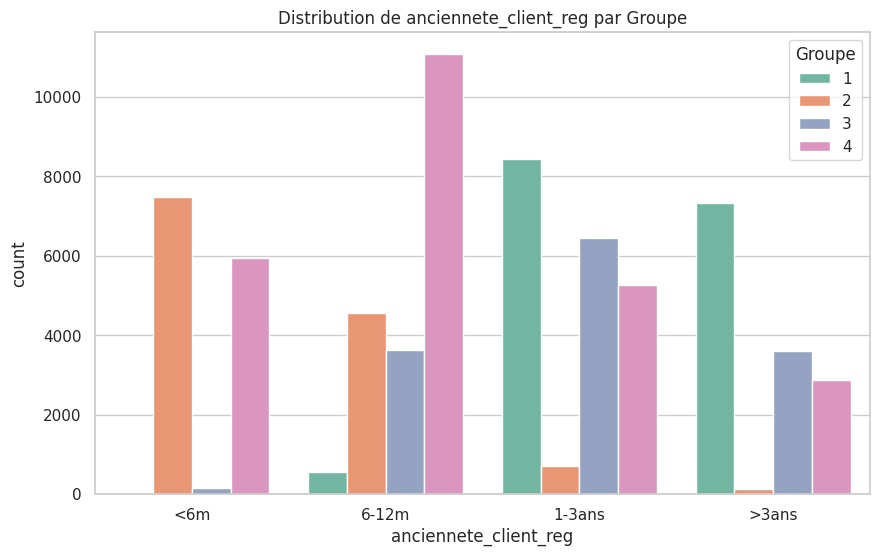

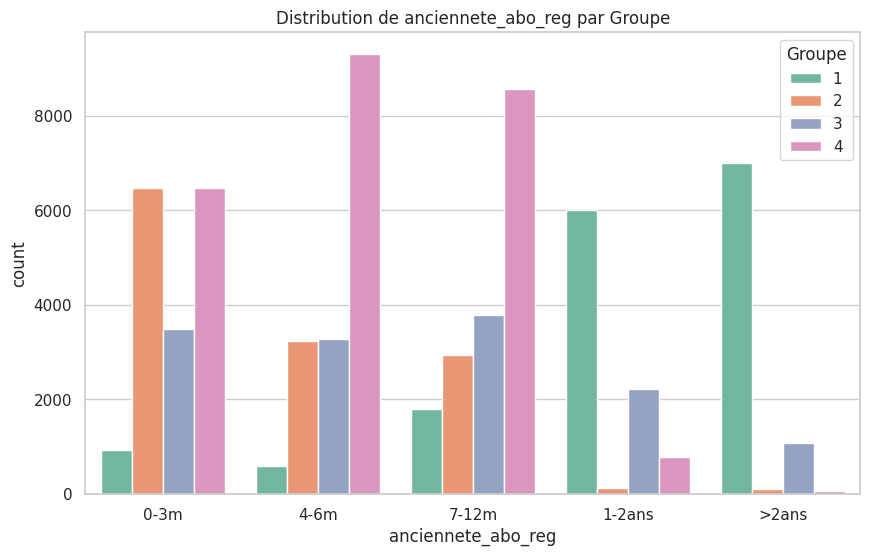

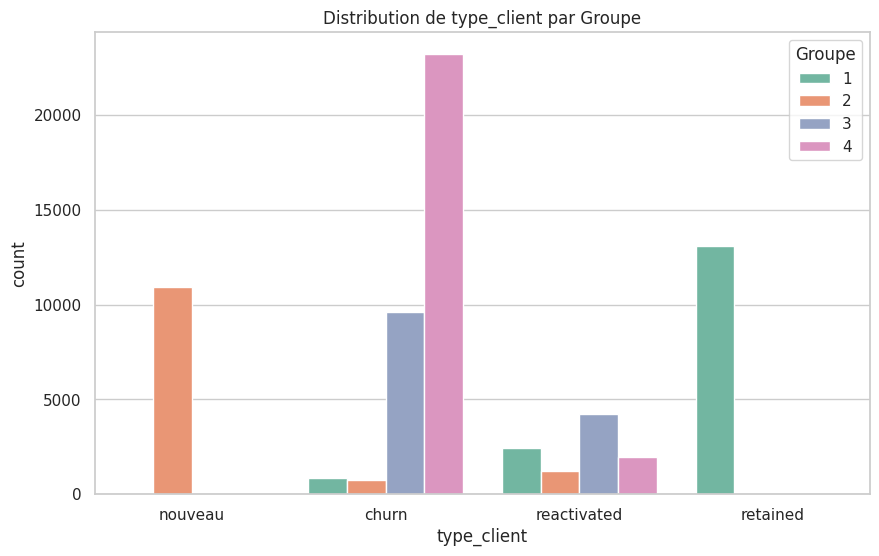

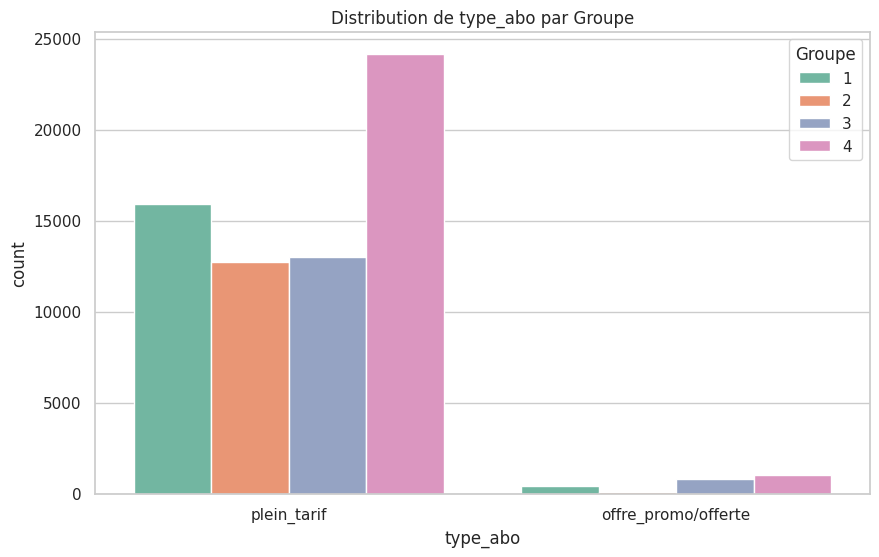

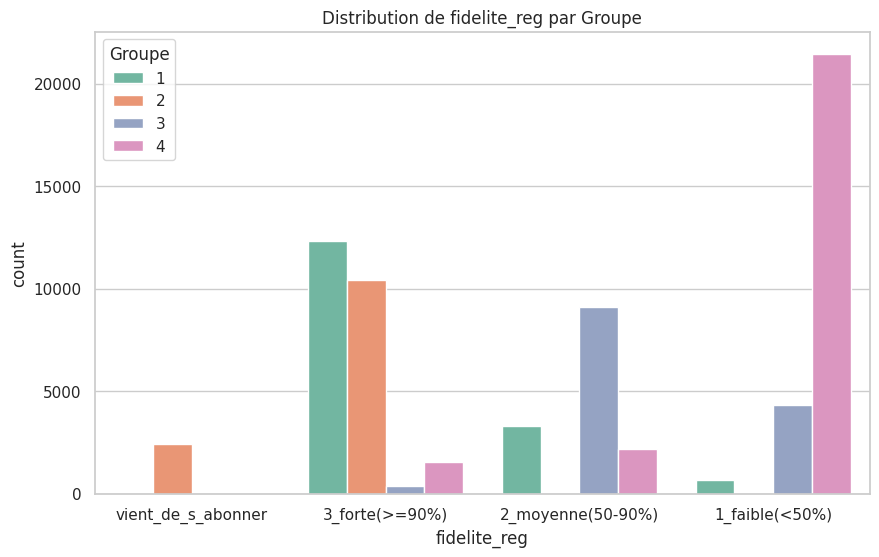

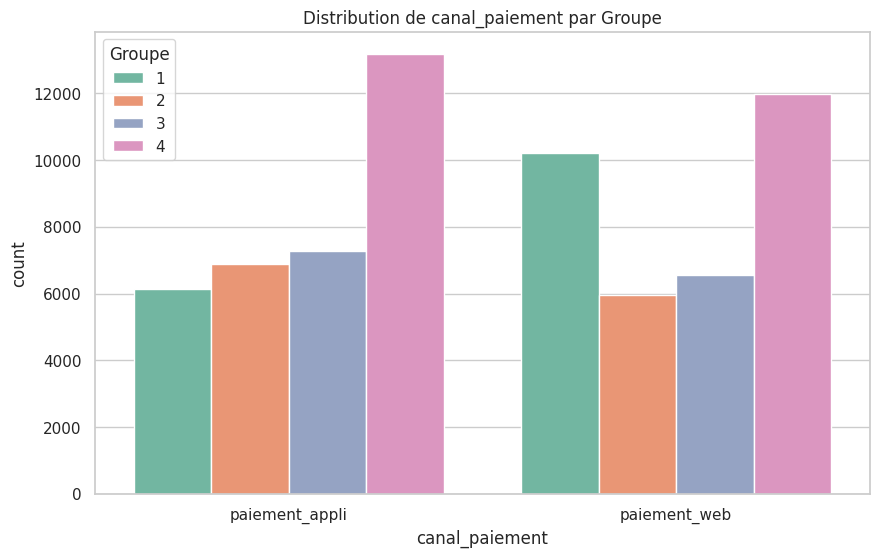

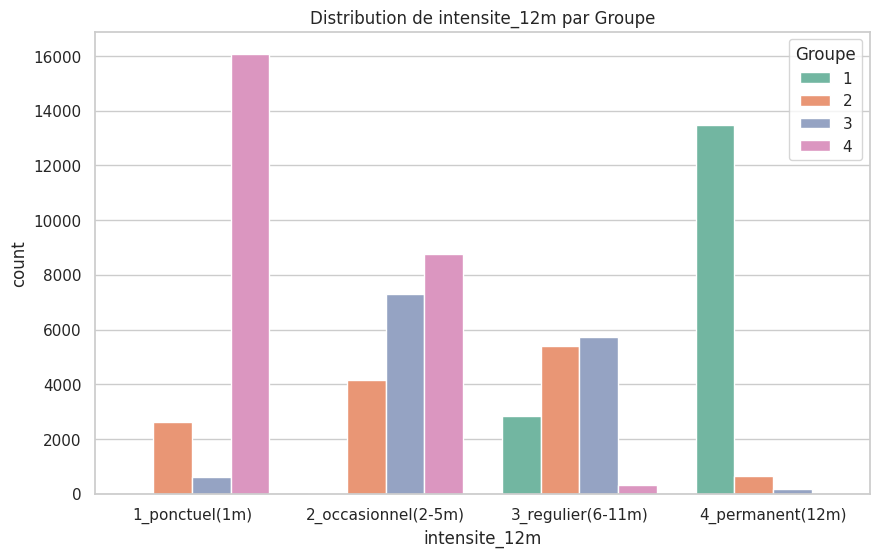

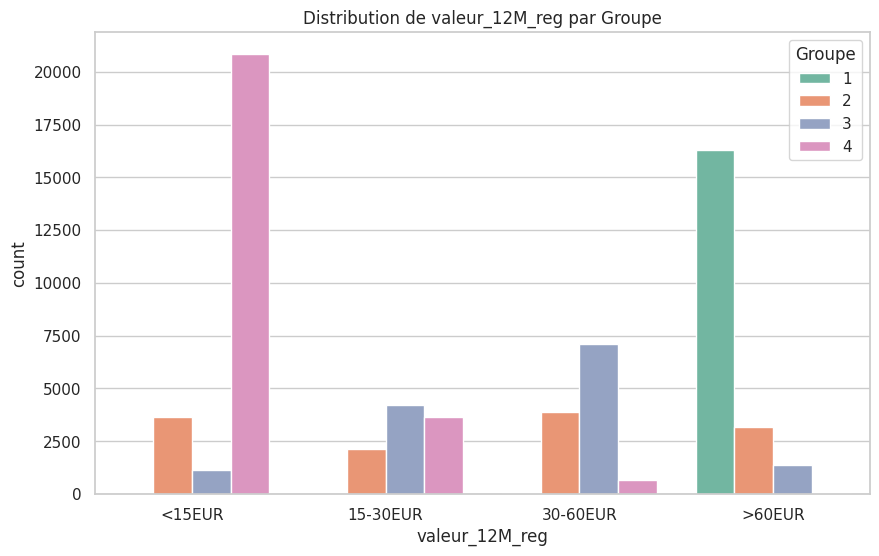

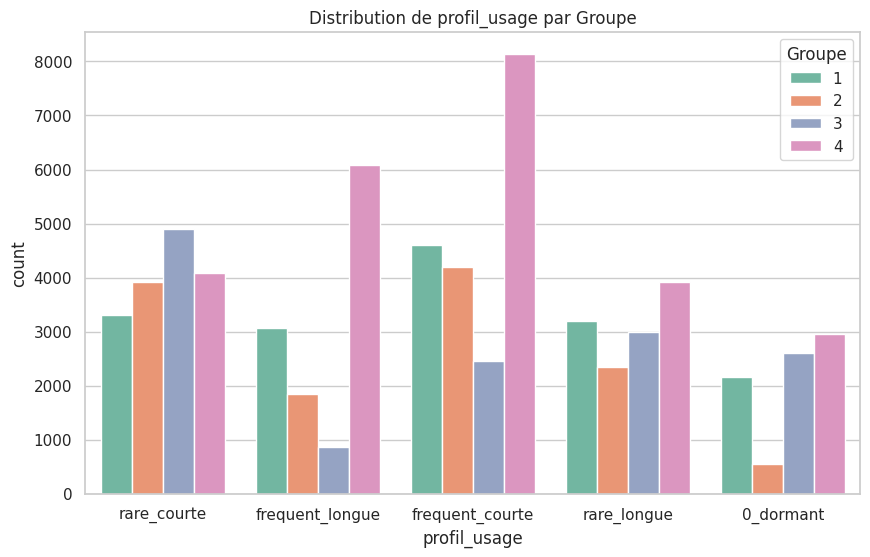

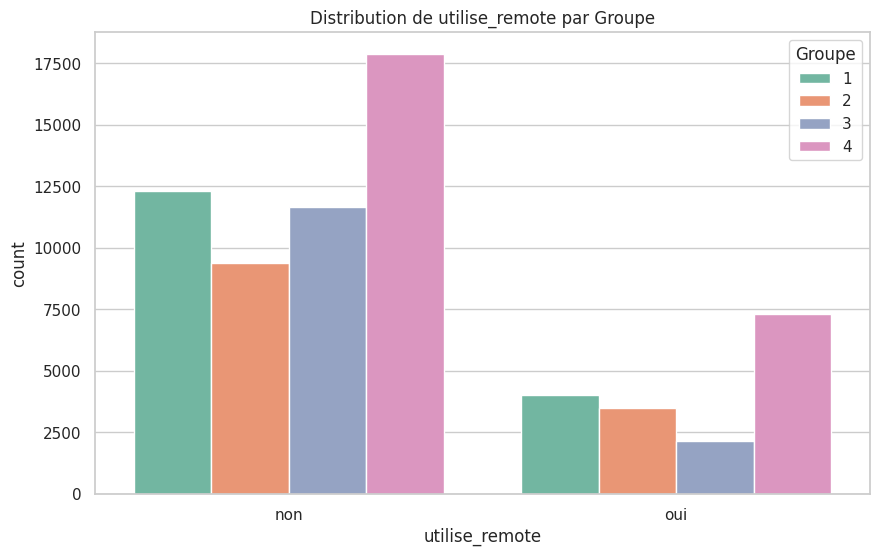

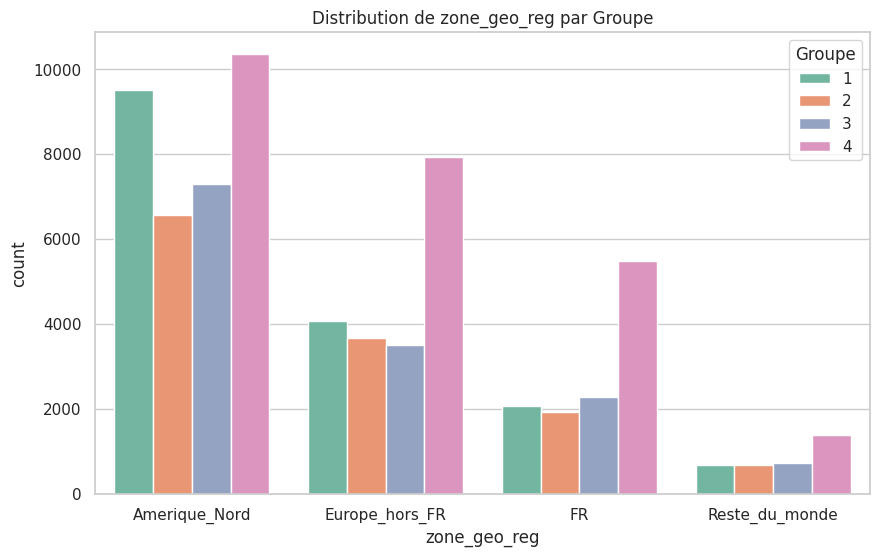

In [86]:
for var in cols_to_analyze:
  plt.figure(figsize=(10, 6))
  sns.countplot(data=df_regrouped_sampled, x=var, hue='Groupe', palette='Set2')
  plt.title(f'Distribution de {var} par Groupe')
  plt.xticks()
  plt.show()

In [87]:
import plotly.express as px

# Préparation des données pour le Groupe 1 (on filtre avec l'entier 1)
df_g1 = df_regrouped_sampled[df_regrouped_sampled['Groupe'] == 1]

for var in cols_to_analyze:
    # Calcul des effectifs pour la variable courante
    counts = df_g1[var].value_counts().reset_index()
    counts.columns = [var, 'Nombre']

    # Création et affichage du TreeMap pour chaque variable
    fig = px.treemap(counts,
                     path=[var],
                     values='Nombre',
                     title=f'Répartition de {var} au sein du Groupe 1',
                     color='Nombre',
                     color_continuous_scale='RdBu')
    fig.show()

In [88]:
import plotly.express as px

# Préparation des données pour le Groupe 1 (on filtre avec l'entier 1)
df_g2 = df_regrouped_sampled[df_regrouped_sampled['Groupe'] == 2]

for var in cols_to_analyze:
    # Calcul des effectifs pour la variable courante
    counts = df_g2[var].value_counts().reset_index()
    counts.columns = [var, 'Nombre']

    # Création et affichage du TreeMap pour chaque variable
    fig = px.treemap(counts,
                     path=[var],
                     values='Nombre',
                     title=f'Répartition de {var} au sein du Groupe 3',
                     color='Nombre',
                     color_continuous_scale='RdBu')
    fig.show()

In [89]:
import plotly.express as px

# Préparation des données pour le Groupe 1 (on filtre avec l'entier 1)
df_g3 = df_regrouped_sampled[df_regrouped_sampled['Groupe'] == 3]

for var in cols_to_analyze:
    # Calcul des effectifs pour la variable courante
    counts = df_g3[var].value_counts().reset_index()
    counts.columns = [var, 'Nombre']

    # Création et affichage du TreeMap pour chaque variable
    fig = px.treemap(counts,
                     path=[var],
                     values='Nombre',
                     title=f'Répartition de {var} au sein du Groupe 3',
                     color='Nombre',
                     color_continuous_scale='RdBu')
    fig.show()

In [90]:
import plotly.express as px

# Préparation des données pour le Groupe 1 (on filtre avec l'entier 1)
df_g4 = df_regrouped_sampled[df_regrouped_sampled['Groupe'] == 4]

for var in cols_to_analyze:
    # Calcul des effectifs pour la variable courante
    counts = df_g4[var].value_counts().reset_index()
    counts.columns = [var, 'Nombre']

    # Création et affichage du TreeMap pour chaque variable
    fig = px.treemap(counts,
                     path=[var],
                     values='Nombre',
                     title=f'Répartition de {var} au sein du Groupe 4',
                     color='Nombre',
                     color_continuous_scale='RdBu')
    fig.show()

# Modélisation

- Toujours sur les 20% de la base, on va entrainer une regression logistique multiple pour prédire à chaque individu, à quelle classe il appartient.
- On va comparer les résultats avec la CAH, il nous faut une précision d'au moins 85%
- Si le modèle est bon, on va l'utiliser pour prédire la classe d'appartenance des 80% autres individus (plus sur l'échantillon de 20%)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning:

'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.



=== Évaluation de la Régression Logistique Multinomiale ===
Précision globale (Accuracy) : 93.28%

✅ Félicitations ! Le modèle dépasse le seuil requis de 85% de précision.

Classification Report :
              precision    recall  f1-score   support

           1       0.94      0.97      0.96      3268
           2       0.96      0.95      0.95      2574
           3       0.89      0.84      0.87      2766
           4       0.94      0.95      0.94      5036

    accuracy                           0.93     13644
   macro avg       0.93      0.93      0.93     13644
weighted avg       0.93      0.93      0.93     13644



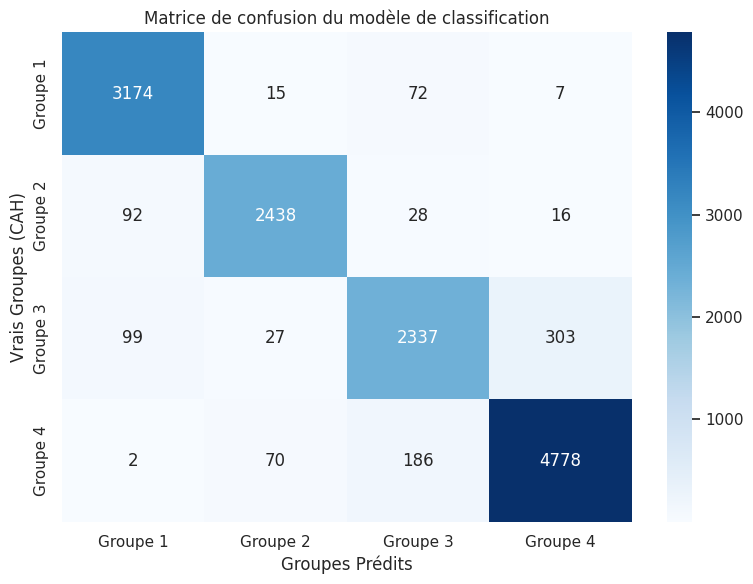

In [91]:

# 1. Préparation des variables explicatives (X = coordonnées ACM) et de la variable cible (y = Groupe de la CAH)
X_model = acm_3.row_coordinates(df_actives).values
y_model = df_regrouped_sampled['Groupe'].values

# 2. Division en ensemble d'entraînement (80%) et de test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=SEED,
    stratify=y_model
)

# 3. Entraînement de la régression logistique multinomiale
# multi_class='multinomial' et un solveur adapté (lbfgs)
model_lr = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000,
    random_state=SEED
)
model_lr.fit(X_train, y_train)

# 4. Prédictions sur l'ensemble de test
y_pred = model_lr.predict(X_test)

# 5. Évaluation du modèle
accuracy = accuracy_score(y_test, y_pred)
print("=== Évaluation de la Régression Logistique Multinomiale ===")
print(f"Précision globale (Accuracy) : {accuracy:.2%}")

# Vérification du seuil des 85%
if accuracy >= 0.85:
    print("\n✅ Félicitations ! Le modèle dépasse le seuil requis de 85% de précision.")
else:
    print("\n❌ Attention : Le modèle n'atteint pas le seuil requis de 85% de précision.")

print("\nClassification Report :")
print(classification_report(y_test, y_pred))

# 6. Visualisation de la matrice de confusion
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Groupe {i}' for i in np.unique(y_model)],
            yticklabels=[f'Groupe {i}' for i in np.unique(y_model)])
plt.title("Matrice de confusion du modèle de classification")
plt.ylabel("Vrais Groupes (CAH)")
plt.xlabel("Groupes Prédits")
plt.tight_layout()
plt.show()

In [92]:
# 1. Identifier les clients restants (les 80% hors échantillon)
df_remaining = df_regrouped[~df_regrouped['id_anonyme'].isin(sampled_ids)].copy()
print(f"Nombre de clients dans les 80% restants : {df_remaining.shape[0]}")

# 2. Préparation des variables actives pour la projection ACM
df_remaining_actives = df_remaining[ACTIVES]

# 3. Projection des 80% restants sur les 5 axes de notre ACM 3
X_remaining = acm_3.row_coordinates(df_remaining_actives).values

# 4. Prédiction des classes avec la régression logistique multinomiale entraînée
y_remaining_pred = model_lr.predict(X_remaining)

# 5. Injection des groupes prédits dans le sous-ensemble restant
df_remaining['Groupe'] = y_remaining_pred

# 6. Reconstruction de la base complète (20% CAH + 80% Régression Logistique)
# On fusionne l'échantillon initial (qui contient les vrais labels CAH) et l'échantillon prédit
df_segmentation_complete = pd.concat([df_regrouped_sampled, df_remaining], axis=0)

print(f"Taille finale de la base de données segmentée : {df_segmentation_complete.shape[0]} clients")
print("\nRépartition finale de la segmentation sur l'ensemble du portefeuille clients :")

rep_finale = df_segmentation_complete['Groupe'].value_counts().sort_index().to_frame(name='Effectif')
rep_finale['Pourcentage (%)'] = (rep_finale['Effectif'] / len(df_segmentation_complete) * 100).round(2)
display(rep_finale)

Nombre de clients dans les 80% restants : 272874
Taille finale de la base de données segmentée : 341092 clients

Répartition finale de la segmentation sur l'ensemble du portefeuille clients :


,Effectif,Pourcentage (%)
Groupe,,
1,83909,24.60
2,63689,18.67
3,66620,19.53
4,126874,37.20


## Stats desc par classe - sur l'ensemble du jeu de données

Pour le rapport : partie technique, on va vérifier que les caractéristique de nos classes sont les même qu'on ait 20 ou 100% de la base d'étude

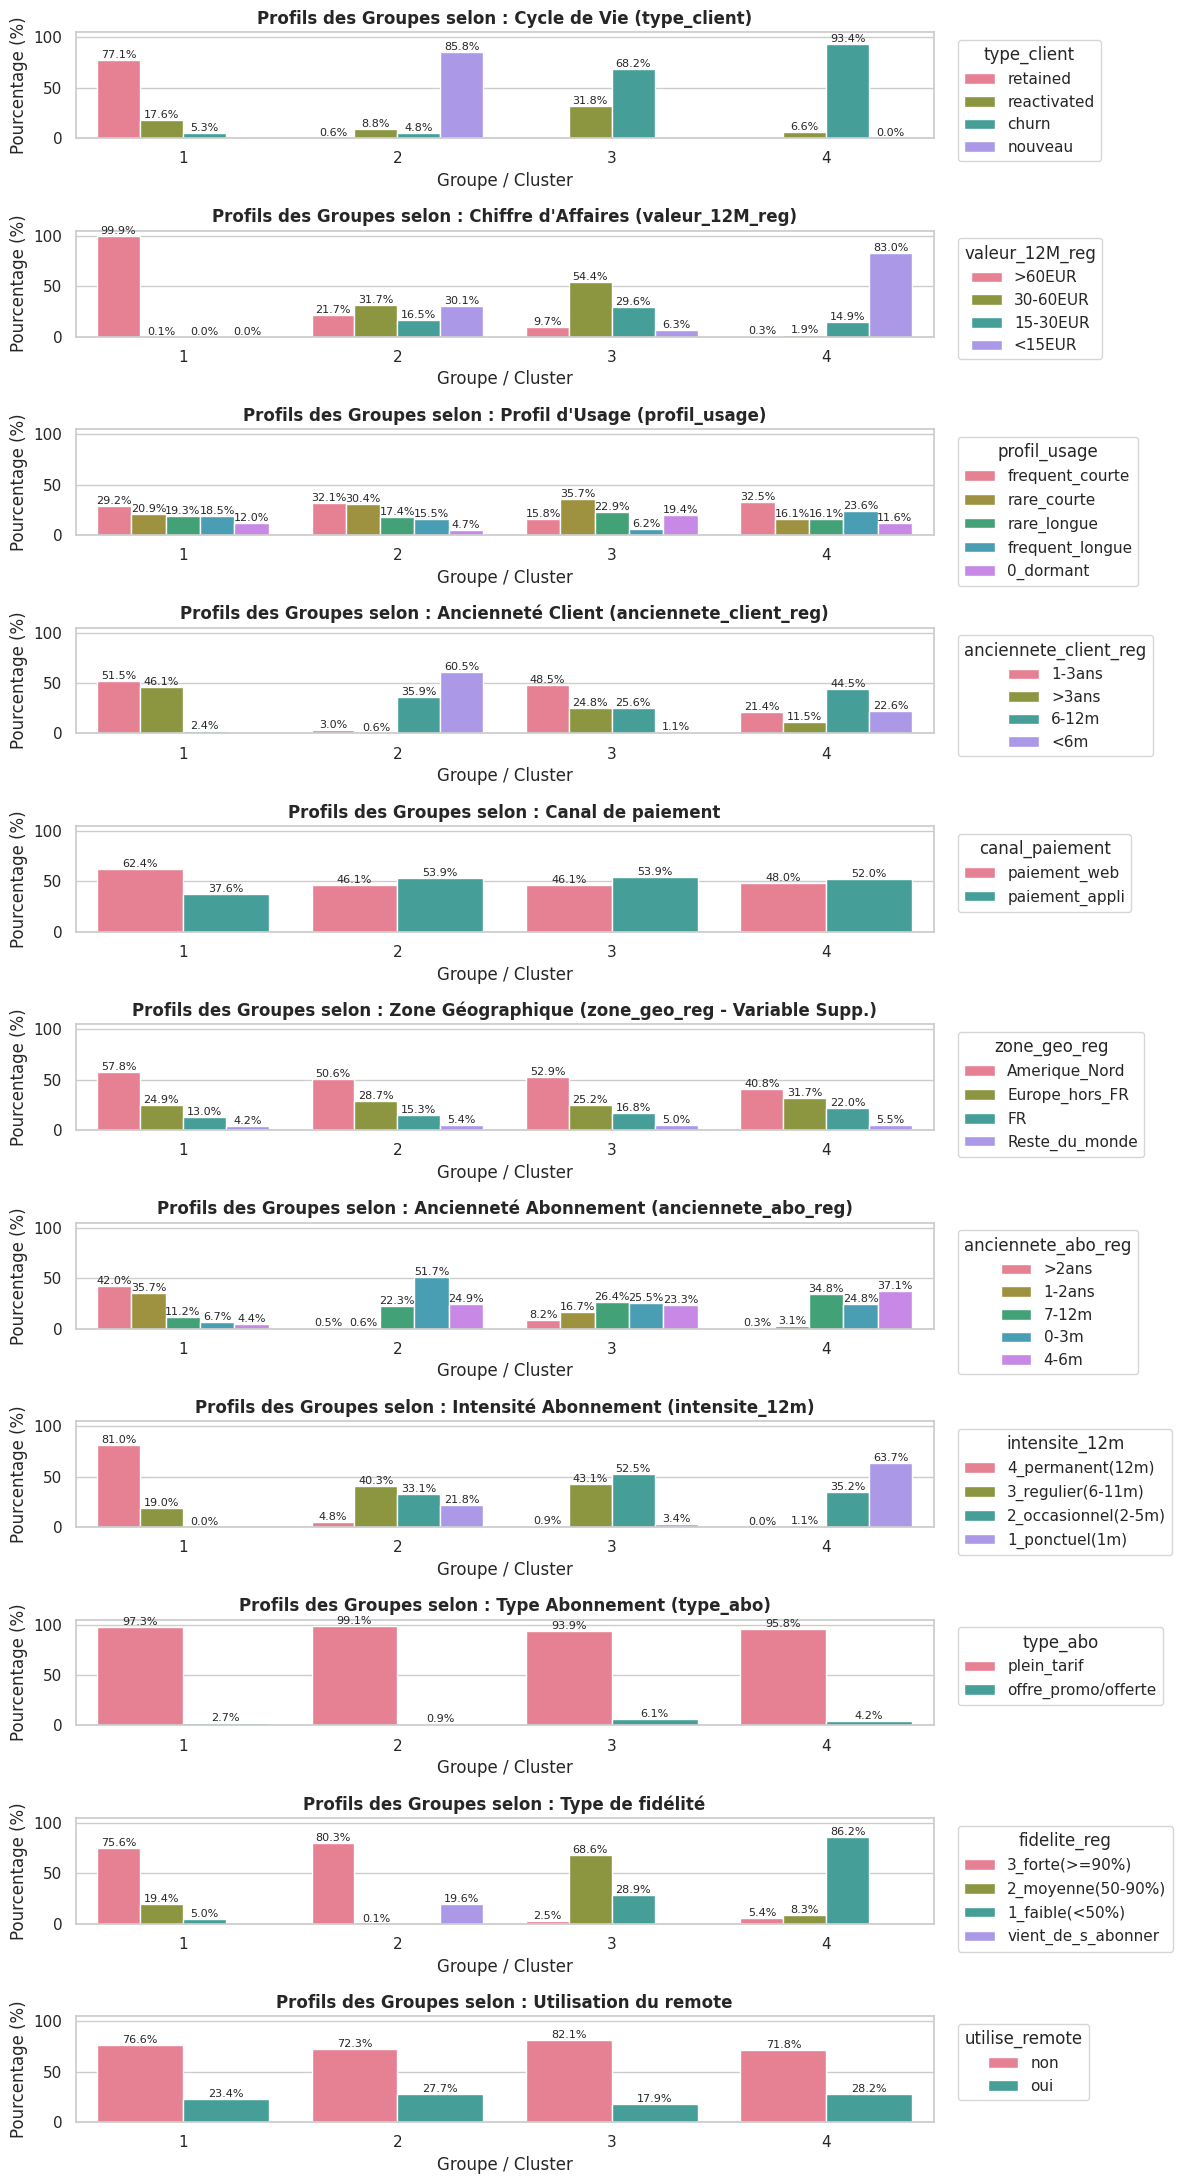

In [93]:
# Configuration globale pour de jolies figures
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 18)

# Variables d'intérêt à visualiser
variables_visualisation = [
    ('type_client', 'Cycle de Vie (type_client)'),
    ('valeur_12M_reg', "Chiffre d'Affaires (valeur_12M_reg)"),
    ('profil_usage', "Profil d'Usage (profil_usage)"),
    ('anciennete_client_reg', "Ancienneté Client (anciennete_client_reg)"),
    ('canal_paiement', "Canal de paiement"),
    ('zone_geo_reg', 'Zone Géographique (zone_geo_reg - Variable Supp.)'),
    ('anciennete_abo_reg', 'Ancienneté Abonnement (anciennete_abo_reg)'),
    ('intensite_12m', 'Intensité Abonnement (intensite_12m)'),
    ('type_abo', 'Type Abonnement (type_abo)'),
    ('fidelite_reg', 'Type de fidélité'),
    ('utilise_remote','Utilisation du remote')
]

# Création d'une grille de subplots
fig, axes = plt.subplots(nrows=len(variables_visualisation), ncols=1, figsize=(12, 22))

for i, (var, titre) in enumerate(variables_visualisation):
    # Calcul des pourcentages par Groupe (somme par ligne = 100%)
    df_plot = (
        df_segmentation_complete.groupby('Groupe')[var]
        .value_counts(normalize=True)
        .mul(100)
        .rename('Pourcentage')
        .reset_index()
    )

    # Tracé du barplot
    sns.barplot(
        data=df_plot,
        x='Groupe',
        y='Pourcentage',
        hue=var,
        ax=axes[i],
        palette='husl'
    )

    # Configuration esthétique
    axes[i].set_title(f"Profils des Groupes selon : {titre}", fontsize=12, fontweight='bold')
    axes[i].set_ylabel("Pourcentage (%)")
    axes[i].set_xlabel("Groupe / Cluster")
    axes[i].set_ylim(0, 105)
    axes[i].legend(title=var, bbox_to_anchor=(1.02, 1), loc='upper left')

    # Ajout des étiquettes de pourcentage sur les barres
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.1f%%', label_type='edge', fontsize=8)

plt.tight_layout()
plt.show()

In [94]:
# Résumé statistique textuel complet
for g in sorted(df_segmentation_complete['Groupe'].unique()):
    print(f"\n" + "="*60)
    print(f"   DESCRIPTION DU GROUPE {g} (Effectif : {rep_4.loc[g, 'Effectif']} individus - {rep_4.loc[g, 'Pourcentage (%)']}%)")
    print("="*60)

    df_sub = df_segmentation_complete[df_segmentation_complete['Groupe'] == g]

    for var in ['anciennete_client_reg', 'anciennete_abo_reg', 'type_client', 'type_abo', 'fidelite_reg','canal_paiement','intensite_12m','valeur_12M_reg','profil_usage','utilise_remote','zone_geo_reg']:
        dist = df_sub[var].value_counts(normalize=True).mul(100).round(1)
        print(f"\n* {var.upper()} (Top modalités) :")
        for modalite, pct in dist.items():
            print(f"  - {modalite:<35} : {pct}%")


   DESCRIPTION DU GROUPE 1 (Effectif : 16340 individus - 23.95%)

* ANCIENNETE_CLIENT_REG (Top modalités) :
  - 1-3ans                              : 51.5%
  - >3ans                               : 46.1%
  - 6-12m                               : 2.4%

* ANCIENNETE_ABO_REG (Top modalités) :
  - >2ans                               : 42.0%
  - 1-2ans                              : 35.7%
  - 7-12m                               : 11.2%
  - 0-3m                                : 6.7%
  - 4-6m                                : 4.4%

* TYPE_CLIENT (Top modalités) :
  - retained                            : 77.1%
  - reactivated                         : 17.6%
  - churn                               : 5.3%

* TYPE_ABO (Top modalités) :
  - plein_tarif                         : 97.3%
  - offre_promo/offerte                 : 2.7%

* FIDELITE_REG (Top modalités) :
  - 3_forte(>=90%)                      : 75.6%
  - 2_moyenne(50-90%)                   : 19.4%
  - 1_faible(<50%)                     

In [95]:
# 3. Répartition globale des 4 groupes
print("=== Répartition finale des individus sur 4 classes ===")
rep_4 = df_segmentation_complete['Groupe'].value_counts().sort_index().to_frame(name='Effectif')
rep_4['Pourcentage (%)'] = (rep_4['Effectif'] / len(df_segmentation_complete) * 100).round(2)
display(rep_4)

# 4. Profilage avec les variables actives clés
print("\n=== Profilage des Groupes par rapport au Cycle de Vie (type_client) ===")
display(pd.crosstab(df_segmentation_complete['Groupe'], df_segmentation_complete['type_client'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport à la Valeur (valeur_12M_reg) ===")
display(pd.crosstab(df_segmentation_complete['Groupe'], df_segmentation_complete['valeur_12M_reg'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport au Profil d'Usage ===")
display(pd.crosstab(df_segmentation_complete['Groupe'], df_segmentation_complete['profil_usage'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport à l'Ancienneté ===")
display(pd.crosstab(df_segmentation_complete['Groupe'], df_segmentation_complete['anciennete_client_reg'], normalize='index').mul(100).round(1))

print("\n=== Profilage des Groupes par rapport à la Zone Géographique (Variable Supp.) ===")
display(pd.crosstab(df_segmentation_complete['Groupe'], df_segmentation_complete['zone_geo_reg'], normalize='index').mul(100).round(1))

=== Répartition finale des individus sur 4 classes ===


,Effectif,Pourcentage (%)
Groupe,,
1,83909,24.60
2,63689,18.67
3,66620,19.53
4,126874,37.20



=== Profilage des Groupes par rapport au Cycle de Vie (type_client) ===


type_client,churn,nouveau,reactivated,retained
Groupe,,,,
1,5.3,0.0,17.6,77.1
2,4.8,85.8,8.8,0.6
3,68.2,0.0,31.8,0.0
4,93.4,0.0,6.6,0.0



=== Profilage des Groupes par rapport à la Valeur (valeur_12M_reg) ===


...

profil_usage,0_dormant,frequent_courte,frequent_longue,rare_courte,rare_longue
Groupe,,,,,
1,12.0,29.2,18.5,20.9,19.3
2,4.7,32.1,15.5,30.4,17.4
3,19.4,15.8,6.2,35.7,22.9
4,11.6,32.5,23.6,16.1,16.1



=== Profilage des Groupes par rapport à l'Ancienneté ===


anciennete_client_reg,1-3ans,6-12m,<6m,>3ans
Groupe,,,,
1,51.5,2.4,0.0,46.1
2,3.0,35.9,60.5,0.6
3,48.5,25.6,1.1,24.8
4,21.4,44.5,22.6,11.5



=== Profilage des Groupes par rapport à la Zone Géographique (Variable Supp.) ===


zone_geo_reg,Amerique_Nord,Europe_hors_FR,FR,Reste_du_monde
Groupe,,,,
1,57.8,24.9,13.0,4.2
2,50.6,28.7,15.3,5.4
3,52.9,25.2,16.8,5.0
4,40.8,31.7,22.0,5.5


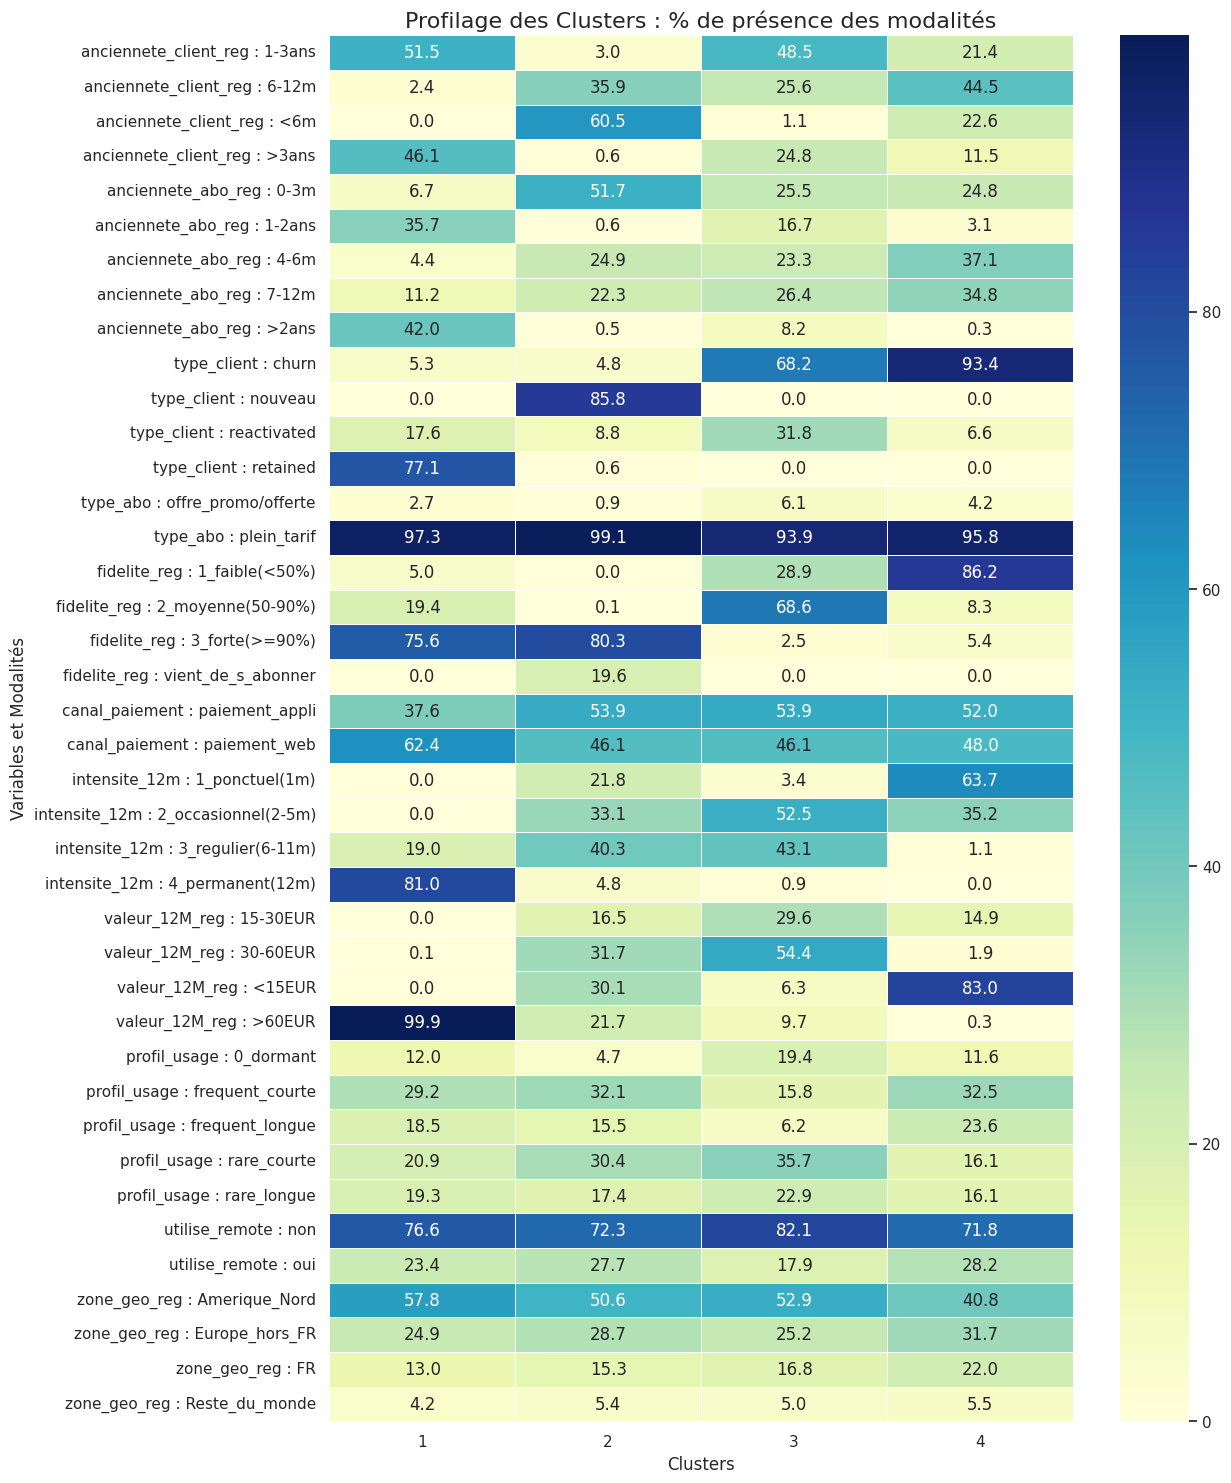

In [97]:
# 1. Chargement et préparation
cols_to_analyze= ['anciennete_client_reg', 'anciennete_abo_reg', 'type_client', 'type_abo', 'fidelite_reg','canal_paiement','intensite_12m','valeur_12M_reg','profil_usage','utilise_remote','zone_geo_reg']
# 2. Calcul des pourcentages par cluster
# On crée un grand tableau où chaque ligne est une modalité
all_stats = []
for col in cols_to_analyze:
    tab = pd.crosstab(df_segmentation_complete[col], df_segmentation_complete['Groupe'], normalize='columns') * 100
    tab.index = [f"{col} : {idx}" for idx in tab.index] # Pour garder le nom de la variable
    all_stats.append(tab)

df_heatmap = pd.concat(all_stats)

# 3. Génération de la Heatmap
plt.figure(figsize=(12, 18)) # Ajustez la hauteur selon le nombre de variables
sns.heatmap(df_heatmap,
            annot=True,      # Affiche les chiffres dans les cases
            fmt=".1f",       # Format avec une décimale
            cmap="YlGnBu",   # Couleur : Jaune (faible) à Bleu (fort)
            linewidths=.5)

plt.title('Profilage des Clusters : % de présence des modalités', fontsize=16)
plt.ylabel('Variables et Modalités')
plt.xlabel('Clusters')
plt.show()

In [99]:
# Tableau avec les modalités les + représentée par groupe
persona_data = []

for num_cluster in sorted(df_segmentation_complete['Groupe'].unique()):
    # On filtre sur le cluster
    subset = df_segmentation_complete[df_segmentation_complete['Groupe'] == num_cluster]

    # Pour chaque variable, on trouve la modalité la plus fréquente
    row = {'Groupe': f"Groupe {num_cluster}"}
    for col in cols_to_analyze:
        # .value_counts().idxmax() donne la modalité la plus présente
        dominant = subset[col].value_counts().idxmax()
        # On peut aussi ajouter le % pour voir si c'est une écrasante majorité
        pct = round((subset[col].value_counts(normalize=True).max() * 100), 1)
        row[col] = f"{dominant} ({pct}%)"

    persona_data.append(row)

# 4. Affichage du tableau final
df_personas = pd.DataFrame(persona_data).set_index('Groupe').T
df_personas

Groupe,Groupe 1,Groupe 2,Groupe 3,Groupe 4
anciennete_client_reg,1-3ans (51.5%),<6m (60.5%),1-3ans (48.5%),6-12m (44.5%)
anciennete_abo_reg,>2ans (42.0%),0-3m (51.7%),7-12m (26.4%),4-6m (37.1%)
type_client,retained (77.1%),nouveau (85.8%),churn (68.2%),churn (93.4%)
type_abo,plein_tarif (97.3%),plein_tarif (99.1%),plein_tarif (93.9%),plein_tarif (95.8%)
fidelite_reg,3_forte(>=90%) (75.6%),3_forte(>=90%) (80.3%),2_moyenne(50-90%) (68.6%),1_faible(<50%) (86.2%)
canal_paiement,paiement_web (62.4%),paiement_appli (53.9%),paiement_appli (53.9%),paiement_appli (52.0%)
intensite_12m,4_permanent(12m) (81.0%),3_regulier(6-11m) (40.3%),2_occasionnel(2-5m) (52.5%),1_ponctuel(1m) (63.7%)
valeur_12M_reg,>60EUR (99.9%),30-60EUR (31.7%),30-60EUR (54.4%),<15EUR (83.0%)
profil_usage,frequent_courte (29.2%),frequent_courte (32.1%),rare_courte (35.7%),frequent_courte (32.5%)
utilise_remote,non (76.6%),non (72.3%),non (82.1%),non (71.8%)


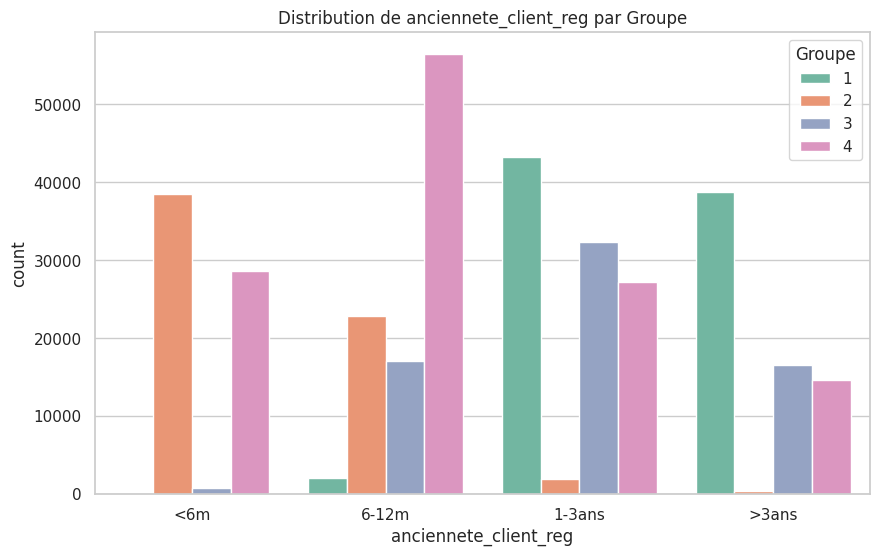

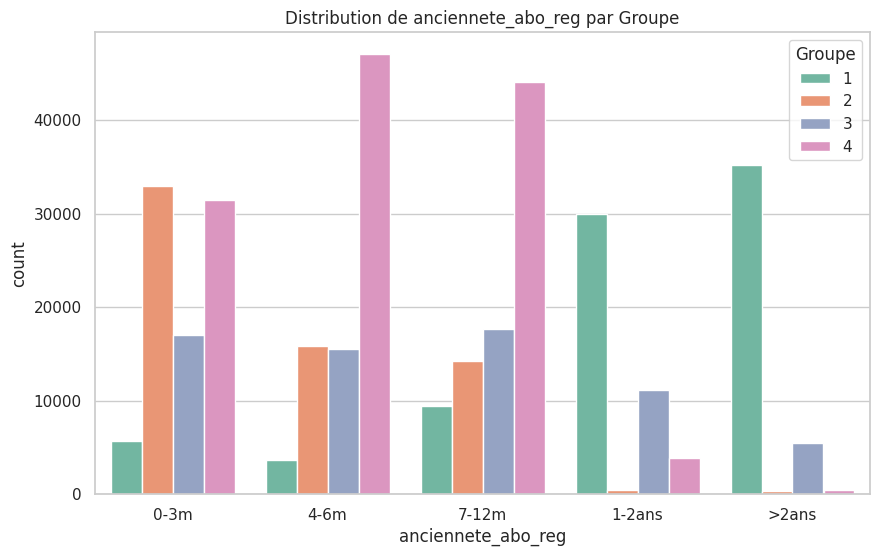

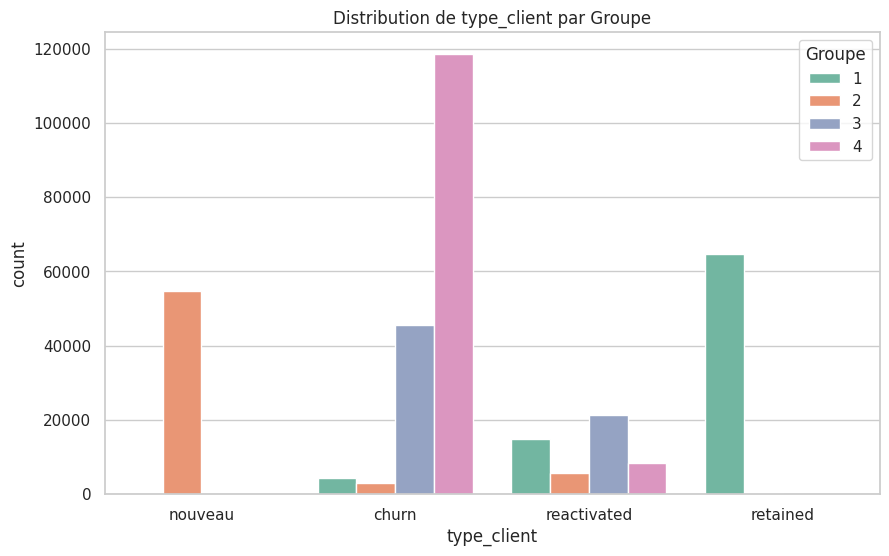

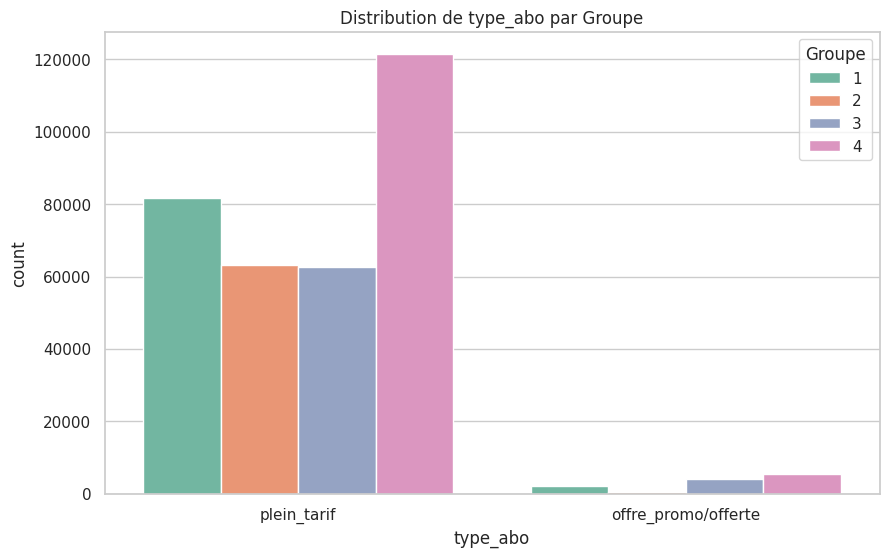

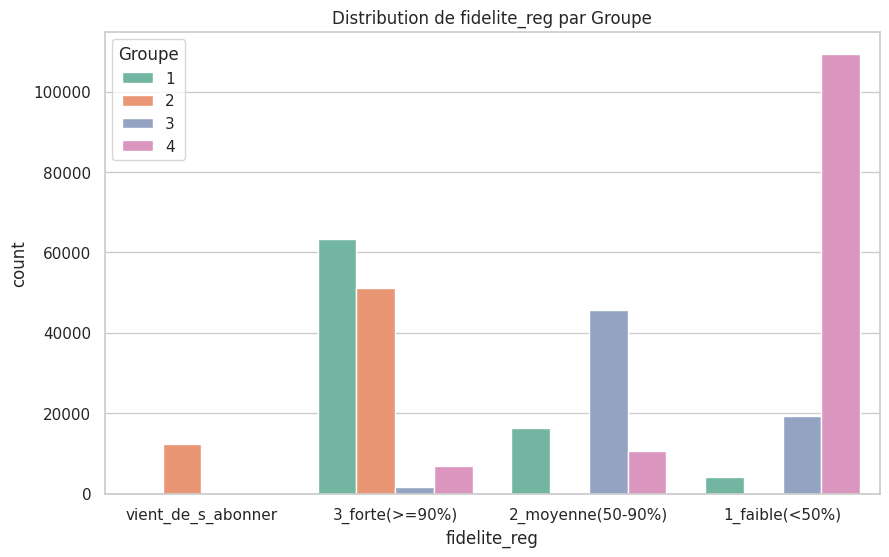

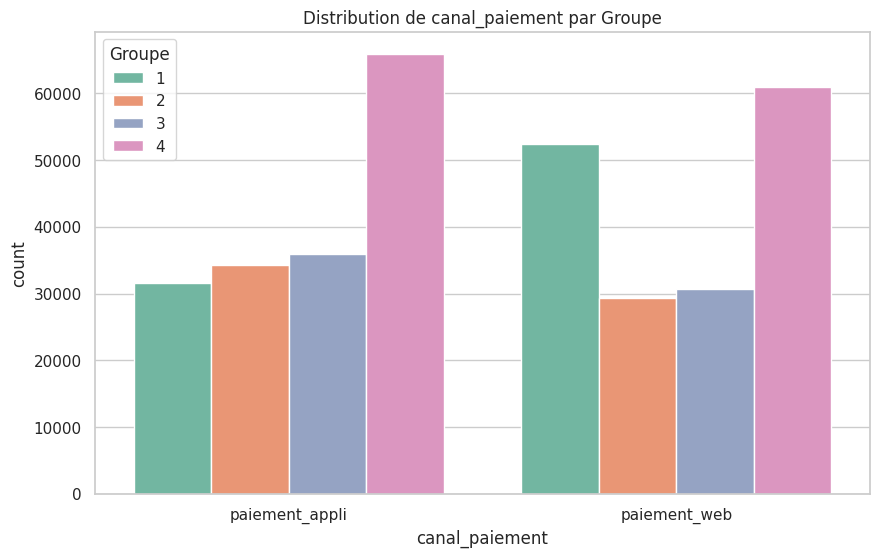

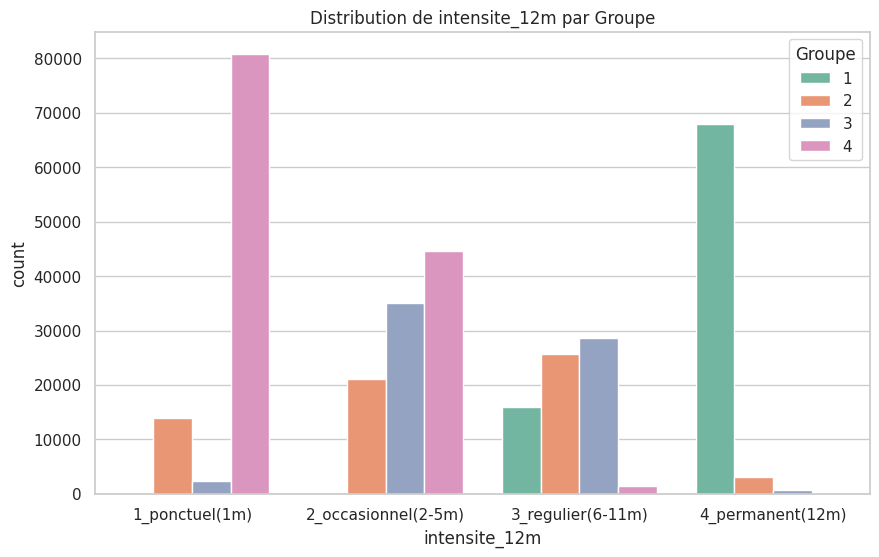

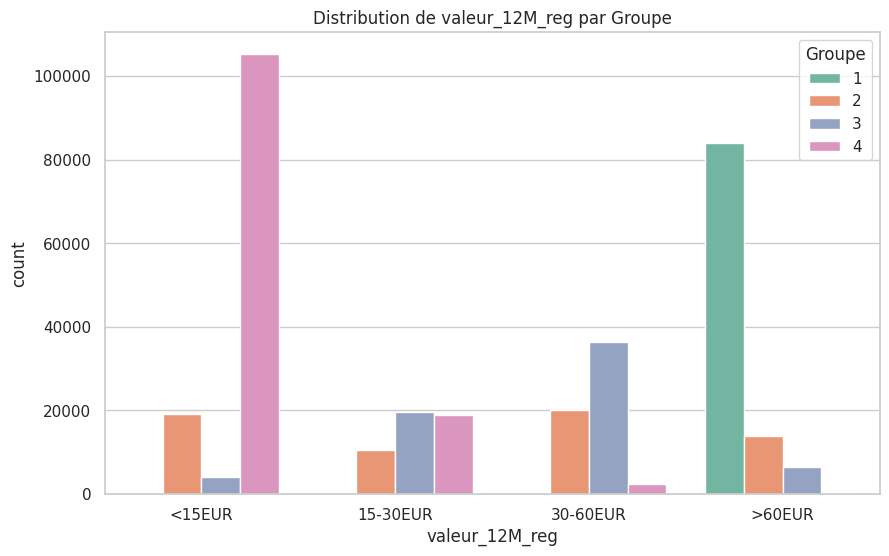

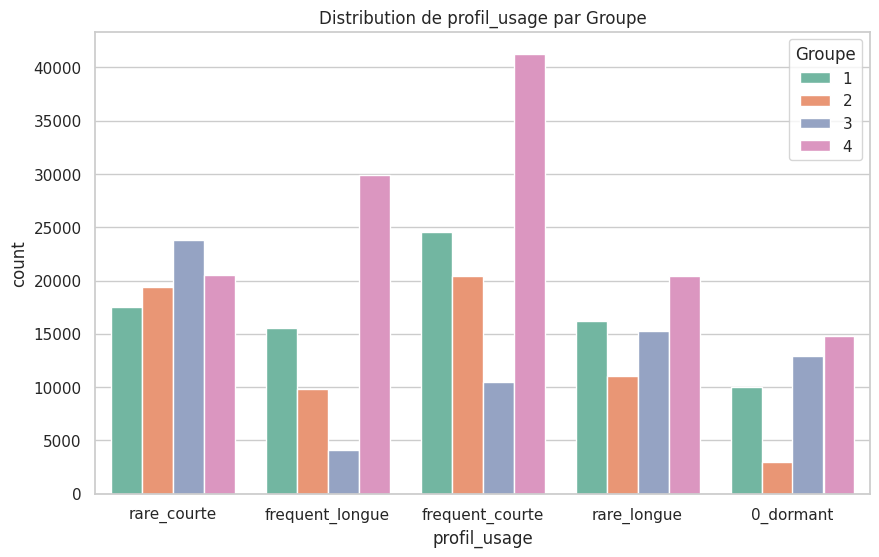

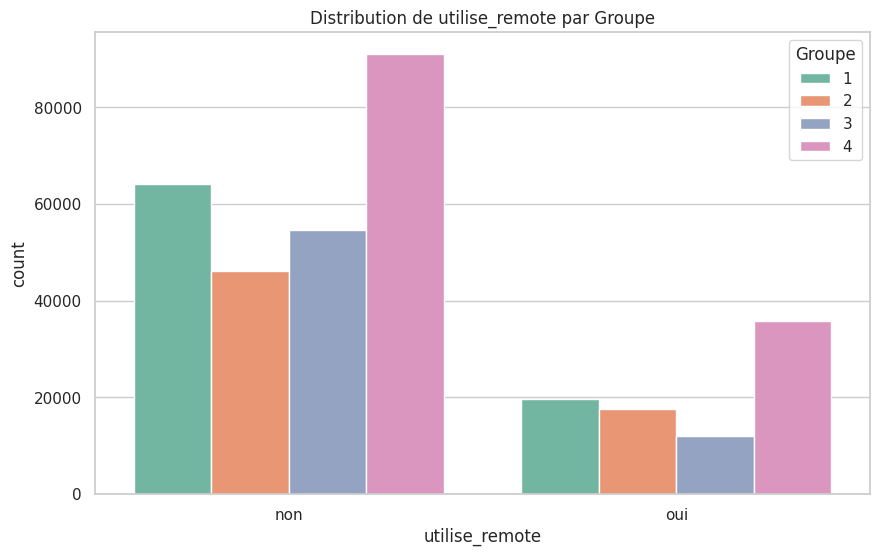

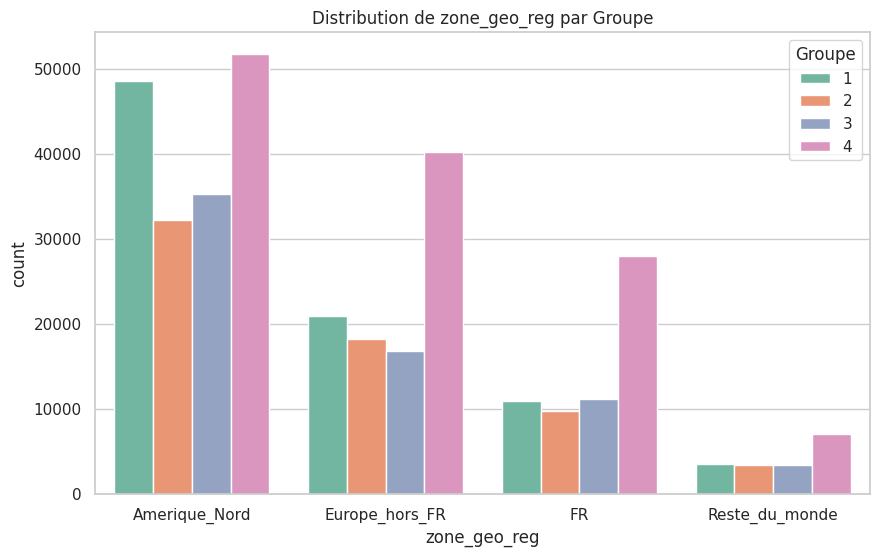

In [100]:
for var in cols_to_analyze:
  plt.figure(figsize=(10, 6))
  sns.countplot(data=df_segmentation_complete, x=var, hue='Groupe', palette='Set2')
  plt.title(f'Distribution de {var} par Groupe')
  plt.xticks()
  plt.show()